## Understand the problem before choosing the tools

**What are we trying to distinguish?**

An astronomical image is not simply a collection of bright and dark pixels. It contains several different kinds of structures:

| Image structure | What it represents | What we need to do |
|---|---|---|
| Point sources | Stars and other unresolved objects | Detect and characterise their PSF |
| Diffuse background | Sky brightness, scattered light and optical background | Estimate and subtract carefully |
| Bright saturated sources | Sources exceeding the detector's useful response | Identify saturation and affected regions |
| Bleed trails and diffraction spikes | Instrumental structures around bright sources | Identify separately from genuine streaks |
| Bad pixels and columns | Detector defects | Flag and exclude from measurements |
| Astronomical streaks | Moving objects integrated across the exposure | Preserve and detect |
| Random fluctuations | Photon and detector noise | Estimate statistically |

This distinction matters because the Fast Radon Transform is a detector of linear features, not an astronomical-object classifier.

Nir, Zackay and Ofek explicitly warn that residual point sources can create detections in Radon space, and that even a small number of bright sources can overpower a real streak. Their recommended workflow begins with point-source removal or reference subtraction, background subtraction, variance estimation and PSF filtering.

The ILMT uses time-delay integration (TDI). Its CCD is read at the sidereal rate so that ordinary sidereal sources remain approximately stationary on the detector rather than forming conventional star trails. The instrument's optical correction also addresses trajectory-related elongation in the TDI system. Oxford University Press

This gives us an important scientific clue: ordinary stars and moving objects do not necessarily produce the same morphology in an ILMT frame.

### What is a PSF, and why did we use Gaussian fitting?
A star is effectively a point-like source, but the telescope, atmosphere and detector spread its light over several pixels. The resulting image of a point source is called the point spread function (PSF).

Think of it this way:
- The star is the source.
- The PSF is how the imaging system makes that source appear.
- Its width and shape describe the system's effective spatial response.
A Gaussian is a convenient approximation to a PSF. It is not automatically the true PSF.

We measure it because the optimal streak-detection method correlates the image with a line broadened by the instrument's PSF. A wrong PSF can weaken the detection or give us biased width measurements. arXiv

We will therefore measure the PSF from multiple isolated, unsaturated stars, examine its shape and spatial variation, and compare Gaussian and empirical profiles before choosing the detection filter.

###  The Notebook structure

We will build the notebook in stages. Each stage has a deliverable and a gate. A stage is not considered complete merely because its Python cell executes without an exception.

| Stage | Work | Deliverable / acceptance gate |
|---|---|---|
| 0 | Configuration and project structure | One source of truth for paths and frame selection |
| 1 | Data ingestion and FITS audit | Verified frame identity, HDU inventory, header and raw array |
| 2 | Raw-data quality audit | Finite pixels, saturation, plateaus, bad rows/columns and pixel statistics |
| 3 | Visual EDA | Full-frame views, histograms, regional views, row/column profiles and stretch comparisons |
| 4 | Annotation and coordinate validation | DS9 coordinate consistency, edge geometry, WCS checks and visual overlay |
| 5 | Detector-defect analysis | Separate masks for invalid pixels, saturation, plateaus, columns and other defects |
| 6 | Background analysis | Competing background models and tests that the long trail is not removed |
| 7 | PSF analysis | Isolated-star selection, empirical PSF and spatial-variation diagnostics |
| 8 | Bright-source analysis | Stellar cores, halos, bleeding, diffraction spikes and source-model tests |
| 9 | Noise and variance analysis | Explicit noise model with justified calibration parameters |
| 10 | Preprocessing validation | Clean residual, variance, mask and provenance products |
| 11 | FRT readiness gate | Evidence that the input is suitable for the chosen FRT implementation |
| 12 | Synthetic and injection tests | Recovery, positional accuracy, sensitivity and false-positive tests |
| 13 | FRT experiment | Full-length and short-streak experiments, with memory controls |
| 14 | Characterisation | Endpoints, width, flux and SNR |
| 15 | Single-frame submission | Validated `submission.csv` for this frame |

### The preprocessing checklist

This is the standard we will hold ourselves to.
---
Data integrity
- [ ] Exact FITS identity and SHA-256 recorded.
- [ ] Correct image HDU selected.
- [ ] Pixel dimensions, dtype, scaling and units understood.
- [ ] Header metadata inspected, not assumed.
- [ ] No accidental modification of the original data.
- [ ] Every derived array linked to the input hash and processing configuration.
---
Image quality
- [ ] Non-finite values identified.
- [ ] Repeated-value plateaus and likely saturation identified.
- [ ] Abnormal rows and columns identified.
- [ ] Bright-source regions inspected at multiple display stretches.
- [ ] Diffuse halos and background gradients mapped.
- [ ] No relevant part of the frame silently discarded.
---
Annotation quality
- [ ] DS9 coordinate convention confirmed.
- [ ] WCS mapping and coordinate round-trip checked where applicable.
- [ ] Two edge lines have consistent endpoints and separation.
- [ ] Centreline and width independently calculated.
- [ ] Annotation visually follows the proposed trail in the unsmoothed image and residual.
- [ ] Annotation is used for evaluation, never as detector input.
---
Background and noise
- [ ] Background model compared at multiple spatial scales.
- [ ] Background subtraction does not erase or distort long linear features.
- [ ] Local RMS is not treated as a complete variance model without justification.
- [ ] Shot noise, read noise and other available detector terms are accounted for.
- [ ] Variance and mask treatment are mathematically consistent.
---
Source suppression
- [ ] Ordinary compact stars identified.
- [ ] Saturated cores identified separately.
- [ ] Stellar halos identified.
- [ ] Bleed trails identified.
- [ ] Diffraction spikes identified.
- [ ] Elongated genuine candidates are not automatically classified as ordinary stars.
- [ ] Source removal is tested for preservation of injected faint streaks.
- [ ] Mask overlap and lost trail coverage are measured.
---
PSF quality
- [ ] Enough isolated, unsaturated stars are available.
- [ ] Fit failures are recorded.
- [ ] Gaussian and empirical profiles are compared.
- [ ] PSF ellipticity and orientation are examined.
- [ ] Spatial variation across the frame is measured.
- [ ] Header-derived FWHM is used as a cross-check, not ground truth.
---
FRT readiness
- [ ] Residual image is finite and background-subtracted.
- [ ] Point-source contamination is controlled.
- [ ] Noise model is justified.
- [ ] PSF model is validated.
- [ ] Masked pixels are treated consistently.
- [ ] Synthetic long-line recovery succeeds.
- [ ] Memory requirements are measured before the full frame is processed.
---
This is the checklist we will use throughout the project.

### The Config Station

In [1]:
# ============================================================
# CELL 0 — PROJECT CONFIGURATION
# ============================================================

from pathlib import Path

# ------------------------------------------------------------
# EDIT ONLY THIS PATH IF YOUR PROJECT LOCATION CHANGES
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/home/deepmalya/pip_malya/ILMT_Streak_Detection"
).expanduser().resolve()

# ------------------------------------------------------------
# INPUTS
# ------------------------------------------------------------

DATA_DIR = PROJECT_ROOT / "ILMT_Contest_Materials" / "test_files"

FRAME_FILENAME = "20221026-0057.fits"
FRAME_PATH = DATA_DIR / FRAME_FILENAME

# Manual annotation is used only for geometry validation.
ANNOTATION_DIR = PROJECT_ROOT / "annotation"
EDGE_REGION_PATH = ANNOTATION_DIR / "ds9_edges_image.reg"

# ------------------------------------------------------------
# OUTPUTS
# ------------------------------------------------------------

OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "single_frame_preprocessing"

FRAME_OUTPUT_DIR = OUTPUT_ROOT / Path(FRAME_FILENAME).stem

# ------------------------------------------------------------
# REFERENCE EXPECTATIONS
# These are validation references, not image-processing inputs.
# ------------------------------------------------------------

EXPECTED_SHAPE = (4096, 4096)
EXPECTED_DATE_OBS = "2022-10-26"

# ------------------------------------------------------------
# RESOURCE / REPRODUCIBILITY SETTINGS
# ------------------------------------------------------------

RANDOM_SEED = 42

HASH_CHUNK_MIB = 8

DISPLAY_MAX_SIDE = 2048

# ------------------------------------------------------------
# PATH VALIDATION
# ------------------------------------------------------------

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(
        f"Project root does not exist: {PROJECT_ROOT}\n"
        "Edit PROJECT_ROOT in Cell 0."
    )

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"FITS data directory does not exist: {DATA_DIR}"
    )

if not FRAME_PATH.is_file():
    raise FileNotFoundError(
        f"Target FITS file does not exist: {FRAME_PATH}"
    )

if not EDGE_REGION_PATH.is_file():
    raise FileNotFoundError(
        f"Manual DS9 annotation is missing: {EDGE_REGION_PATH}"
    )

FRAME_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("PROJECT CONFIGURATION")
print("---------------------")
print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Target frame:", FRAME_PATH.name)
print("Frame exists:", FRAME_PATH.is_file())
print("Annotation:", EDGE_REGION_PATH)
print("Output directory:", FRAME_OUTPUT_DIR)
print("Expected shape:", EXPECTED_SHAPE)
print("Expected DATE-OBS:", EXPECTED_DATE_OBS)

PROJECT CONFIGURATION
---------------------
Project root: /home/deepmalya/pip_malya/ILMT_Streak_Detection
Data directory: /home/deepmalya/pip_malya/ILMT_Streak_Detection/ILMT_Contest_Materials/test_files
Target frame: 20221026-0057.fits
Frame exists: True
Annotation: /home/deepmalya/pip_malya/ILMT_Streak_Detection/annotation/ds9_edges_image.reg
Output directory: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057
Expected shape: (4096, 4096)
Expected DATE-OBS: 2022-10-26


### Environment and dependency audit

In [2]:
# ============================================================
# CELL 1 — ENVIRONMENT AUDIT
# ============================================================

import sys
import platform
import importlib.metadata as metadata

REQUIRED_PACKAGES = [
    "numpy",
    "astropy",
    "scipy",
    "matplotlib",
    "pandas",
    "sep",
    "psutil"
]

print("PYTHON ENVIRONMENT")
print("------------------")
print("Python:", platform.python_version())
print("Platform:", platform.platform())
print("Executable:", sys.executable)

print("\nPACKAGE VERSIONS")
print("----------------")

PACKAGE_VERSIONS = {}

for package in REQUIRED_PACKAGES:

    try:
        version = metadata.version(package)
        PACKAGE_VERSIONS[package] = version

        print(f"{package:15s}: {version}")

    except metadata.PackageNotFoundError:

        PACKAGE_VERSIONS[package] = None

        print(f"{package:15s}: NOT INSTALLED")

missing = [
    package
    for package, version in PACKAGE_VERSIONS.items()
    if version is None
]

if missing:

    print("\nMissing packages:", missing)

    raise ImportError(
        "Install the missing packages in the active project "
        "environment before continuing."
    )

print("\nEnvironment audit passed.")

PYTHON ENVIRONMENT
------------------
Python: 3.13.13
Platform: Linux-7.0.0-42-generic-x86_64-with-glibc2.43
Executable: /home/deepmalya/pip_malya/ILMT_Streak_Detection/ILMT_env/bin/python

PACKAGE VERSIONS
----------------
numpy          : 2.5.2
astropy        : 8.0.1
scipy          : 1.18.1
matplotlib     : 3.11.2
pandas         : 3.0.6
sep            : 1.4.1
psutil         : 7.2.2

Environment audit passed.


### FITS container and metadata inspection

A FITS file can contain multiple HDUs (Header/Data Units). Before selecting an image, we should inspect every HDU and identify which one contains the intended two-dimensional science image. We will also calculate the SHA-256 fingerprint. This is a file-identity check, not an image-quality check.

In [3]:
# ============================================================
# CELL 2 — FITS CONTAINER AUDIT
# ============================================================

import hashlib
import numpy as np
from astropy.io import fits

# ------------------------------------------------------------
# 1. File metadata
# ------------------------------------------------------------

file_size_bytes = FRAME_PATH.stat().st_size

print("FITS FILE")
print("---------")
print("Filename:", FRAME_PATH.name)
print("Size [MiB]:", round(file_size_bytes / 1024**2, 3))

# ------------------------------------------------------------
# 2. SHA-256 fingerprint
# ------------------------------------------------------------

sha256 = hashlib.sha256()

chunk_size = HASH_CHUNK_MIB * 1024 * 1024

with open(FRAME_PATH, "rb") as file_handle:

    while True:

        block = file_handle.read(chunk_size)

        if not block:
            break

        sha256.update(block)

FITS_SHA256 = sha256.hexdigest()

print("SHA-256:", FITS_SHA256)

# ------------------------------------------------------------
# 3. Inspect all HDUs without loading image arrays
# ------------------------------------------------------------

HDU_SUMMARY = []

with fits.open(
    FRAME_PATH,
    mode="readonly",
    memmap=True,
    lazy_load_hdus=False
) as hdul:

    print("\nHDU INVENTORY")
    print("-------------")

    for index, hdu in enumerate(hdul):

        shape = getattr(hdu, "shape", None)

        summary = {
            "hdu_index": index,
            "name": hdu.name,
            "type": type(hdu).__name__,
            "shape": shape,
            "bitpix": hdu.header.get("BITPIX"),
            "naxis": hdu.header.get("NAXIS"),
            "bunit": hdu.header.get("BUNIT"),
            "bscale": hdu.header.get("BSCALE"),
            "bzero": hdu.header.get("BZERO"),
            "checksum": hdu.header.get("CHECKSUM"),
            "datasum": hdu.header.get("DATASUM")
        }

        HDU_SUMMARY.append(summary)

        print(
            f"HDU {index}: "
            f"name={summary['name']!r}, "
            f"type={summary['type']}, "
            f"shape={shape}, "
            f"BITPIX={summary['bitpix']}, "
            f"BUNIT={summary['bunit']}"
        )

    # --------------------------------------------------------
    # 4. Inspect primary-header metadata
    # --------------------------------------------------------

    PRIMARY_HEADER = hdul[0].header.copy()

HEADER_KEYS = [
    "SIMPLE",
    "BITPIX",
    "NAXIS",
    "NAXIS1",
    "NAXIS2",
    "DATE-OBS",
    "MJD-OBS",
    "TIME-OBS",
    "FILTER",
    "BUNIT",
    "TELESCOP",
    "INSTRUME",
    "OBJECT",
    "EXPTIME",
    "GAIN",
    "RDNOISE",
    "SKY",
    "FWHM",
    "IMSCALE",
    "BSCALE",
    "BZERO",
    "SATURATE",
    "CHECKSUM",
    "DATASUM"
]

print("\nPRIMARY HEADER")
print("--------------")

for key in HEADER_KEYS:

    if key in PRIMARY_HEADER:

        print(f"{key:12s}: {PRIMARY_HEADER[key]}")

# ------------------------------------------------------------
# 5. Identify possible 2-D image HDUs
# ------------------------------------------------------------

IMAGE_HDU_CANDIDATES = [
    item
    for item in HDU_SUMMARY
    if item["shape"] is not None
    and len(item["shape"]) == 2
]

print("\n2-D IMAGE HDU CANDIDATES")
print("------------------------")

for item in IMAGE_HDU_CANDIDATES:
    print(
        f"Index={item['hdu_index']} | "
        f"Name={item['name']} | "
        f"Shape={item['shape']}"
    )

if not IMAGE_HDU_CANDIDATES:

    raise RuntimeError(
        "No two-dimensional image HDU was found."
    )

print("\nFITS container audit completed.")

FITS FILE
---------
Filename: 20221026-0057.fits
Size [MiB]: 64.015
SHA-256: 49d29e18f54b729456bd166f7037e551c727d7a32e8cde5530a776527bd38a10

HDU INVENTORY
-------------
HDU 0: name='PRIMARY', type=PrimaryHDU, shape=(4096, 4096), BITPIX=-32, BUNIT=None

PRIMARY HEADER
--------------
SIMPLE      : True
BITPIX      : -32
NAXIS       : 2
NAXIS1      : 4096
NAXIS2      : 4096
DATE-OBS    : 2022-10-26
FILTER      : g
OBJECT      : obs-g-2022102
EXPTIME     : 102.34550550528
SKY         : 1023.89
FWHM        : 2.5201002281347624
IMSCALE     : 0.3276

2-D IMAGE HDU CANDIDATES
------------------------
Index=0 | Name=PRIMARY | Shape=(4096, 4096)

FITS container audit completed.


### Load the raw science image

We have identified only one two-dimensional image HDU, so we can safely select HDU 0.

We will load one independent copy into memory and preserve it as our canonical raw image.

**Concept: why make a copy?**

FITS memory mapping can expose data directly from the file on disk. That is useful for large datasets. However, for our processing workflow, we prefer an independent in-memory copy so that later operations cannot accidentally modify the original FITS-backed data.

In [4]:
# ============================================================
# CELL 3 — LOAD CANONICAL RAW SCIENCE IMAGE
# ============================================================

import gc
import json
import numpy as np
import psutil

# ------------------------------------------------------------
# 1. Memory utility
# ------------------------------------------------------------

def memory_report():

    process = psutil.Process()

    rss_gib = (
        process.memory_info().rss / 1024**3
    )

    available_gib = (
        psutil.virtual_memory().available / 1024**3
    )

    return {
        "process_rss_gib": round(rss_gib, 3),
        "available_ram_gib": round(available_gib, 3)
    }


# ------------------------------------------------------------
# 2. Load the science image
# ------------------------------------------------------------

gc.collect()

with fits.open(
    FRAME_PATH,
    mode="readonly",
    memmap=True
) as hdul:

    if len(hdul) != 1:
        raise RuntimeError(
            f"Expected one HDU, found {len(hdul)}."
        )

    selected_hdu = hdul[0]

    if selected_hdu.data is None:
        raise RuntimeError(
            "Primary HDU contains no image data."
        )

    if selected_hdu.data.ndim != 2:
        raise RuntimeError(
            f"Expected 2-D image, got "
            f"{selected_hdu.data.ndim}-D data."
        )

    # Independent, C-contiguous copy.
    image_raw = np.array(
        selected_hdu.data,
        dtype=np.float32,
        copy=True,
        order="C"
    )

    raw_header = selected_hdu.header.copy()


# ------------------------------------------------------------
# 3. Verify the loaded image
# ------------------------------------------------------------

if image_raw.shape != EXPECTED_SHAPE:

    raise RuntimeError(
        f"Unexpected image shape: {image_raw.shape}"
    )

if image_raw.dtype != np.float32:

    raise RuntimeError(
        f"Expected float32, got {image_raw.dtype}"
    )

if not image_raw.flags["C_CONTIGUOUS"]:

    raise RuntimeError(
        "Image is not C-contiguous."
    )


# ------------------------------------------------------------
# 4. Preserve the raw-data identity
# ------------------------------------------------------------

RAW_IMAGE_SHAPE = tuple(image_raw.shape)
RAW_IMAGE_DTYPE = str(image_raw.dtype)

RAW_IMAGE_NBYTES = int(
    image_raw.nbytes
)

RAW_IMAGE_SHA256 = FITS_SHA256


# ------------------------------------------------------------
# 5. Report
# ------------------------------------------------------------

print("RAW IMAGE LOADED")
print("----------------")

print("Frame:", FRAME_FILENAME)
print("HDU:", 0)
print("Shape:", RAW_IMAGE_SHAPE)
print("Dtype:", RAW_IMAGE_DTYPE)

print(
    "Memory occupied:",
    round(RAW_IMAGE_NBYTES / 1024**2, 3),
    "MiB"
)

print("C-contiguous:", image_raw.flags["C_CONTIGUOUS"])
print("Writeable:", image_raw.flags["WRITEABLE"])

print("SHA-256:", RAW_IMAGE_SHA256)

print("Memory:", memory_report())

print("\nPASS: Canonical raw image loaded.")

RAW IMAGE LOADED
----------------
Frame: 20221026-0057.fits
HDU: 0
Shape: (4096, 4096)
Dtype: float32
Memory occupied: 64.0 MiB
C-contiguous: True
Writeable: True
SHA-256: 49d29e18f54b729456bd166f7037e551c727d7a32e8cde5530a776527bd38a10
Memory: {'process_rss_gib': 0.141, 'available_ram_gib': 6.792}

PASS: Canonical raw image loaded.


### Numerical pixel audit

ABefore identifying stars or background, we need to understand the distribution of pixel values. A pixel's numerical value tells us how much signal the detector recorded, but not automatically its physical origin. We shall go for Descriptive Analytics. 

| Statistic | What it tells us |
|---|---|
| Minimum / maximum | Numerical range and possible extreme pixels |
| Mean | Average pixel level |
| Median | Central pixel-value level |
| Standard deviation | Overall variation |
| Robust sigma | Spread estimated using MAD, less sensitive to bright sources |
| Percentiles | How the distribution changes from faint to bright pixels |
| Negative-pixel fraction | Useful diagnostic of the image's processing history |
| Zero-pixel fraction | Identifies exact zero values |
| Non-finite count | Identifies invalid pixels |



In [5]:
# ============================================================
# CELL 4 — RAW PIXEL STATISTICS
# ============================================================

# ------------------------------------------------------------
# 1. Build a finite-pixel mask
# ------------------------------------------------------------

raw_finite_mask = np.isfinite(image_raw)

n_total = int(image_raw.size)
n_finite = int(raw_finite_mask.sum())
n_invalid = n_total - n_finite

if n_finite == 0:
    raise RuntimeError("No finite image pixels were found.")

# Use the original flattened view when all pixels are finite.
# Otherwise, extract only finite values.
if n_invalid == 0:
    finite_values = image_raw.ravel()
else:
    finite_values = image_raw[raw_finite_mask]


# ------------------------------------------------------------
# 2. Distribution statistics
# ------------------------------------------------------------

raw_min = float(np.min(finite_values))
raw_max = float(np.max(finite_values))

raw_mean = float(np.mean(finite_values))
raw_median = float(np.median(finite_values))

raw_std = float(np.std(finite_values))

# Median absolute deviation.
raw_mad = float(
    np.median(
        np.abs(finite_values - raw_median)
    )
)

# Convert MAD to a robust Gaussian-equivalent sigma.
raw_robust_sigma = float(
    1.4826022185 * raw_mad
)


# ------------------------------------------------------------
# 3. Percentile distribution
# ------------------------------------------------------------

percentile_levels = [
    0,
    0.01,
    0.1,
    1,
    5,
    10,
    25,
    50,
    75,
    90,
    95,
    99,
    99.9,
    99.99,
    100
]

percentile_values = np.percentile(
    finite_values,
    percentile_levels
)

RAW_PERCENTILES = {
    str(p): float(v)
    for p, v in zip(
        percentile_levels,
        percentile_values
    )
}


# ------------------------------------------------------------
# 4. Pixel categories
# ------------------------------------------------------------

n_negative = int(
    np.count_nonzero(finite_values < 0)
)

n_zero = int(
    np.count_nonzero(finite_values == 0)
)

n_positive = int(
    np.count_nonzero(finite_values > 0)
)


# ------------------------------------------------------------
# 5. Compare the header SKY card with the image median
# ------------------------------------------------------------

header_sky = raw_header.get("SKY")

if header_sky is not None:

    header_sky = float(header_sky)

    sky_difference = (
        raw_median - header_sky
    )

    sky_difference_robust_sigma = (
        abs(sky_difference) / raw_robust_sigma
        if raw_robust_sigma > 0
        else np.nan
    )

else:

    sky_difference = np.nan
    sky_difference_robust_sigma = np.nan


# ------------------------------------------------------------
# 6. Header-derived FWHM reference
# ------------------------------------------------------------

header_fwhm = raw_header.get("FWHM")
header_imscale = raw_header.get("IMSCALE")

if (
    header_fwhm is not None
    and header_imscale is not None
    and float(header_imscale) > 0
):

    HEADER_FWHM_PIX = (
        float(header_fwhm) /
        float(header_imscale)
    )

    HEADER_PSF_SIGMA_PIX = (
        HEADER_FWHM_PIX / 2.354820045
    )

else:

    HEADER_FWHM_PIX = np.nan
    HEADER_PSF_SIGMA_PIX = np.nan


# ------------------------------------------------------------
# 7. Consolidated report
# ------------------------------------------------------------

RAW_PIXEL_AUDIT = {

    "shape": list(image_raw.shape),

    "dtype": str(image_raw.dtype),

    "total_pixels": n_total,

    "finite_pixels": n_finite,

    "invalid_pixels": n_invalid,

    "minimum": raw_min,

    "maximum": raw_max,

    "mean": raw_mean,

    "median": raw_median,

    "standard_deviation": raw_std,

    "mad": raw_mad,

    "robust_sigma": raw_robust_sigma,

    "negative_pixels": n_negative,

    "zero_pixels": n_zero,

    "positive_pixels": n_positive,

    "percentiles": RAW_PERCENTILES,

    "header_sky": header_sky,

    "median_minus_header_sky": sky_difference,

    "sky_difference_in_robust_sigma": sky_difference_robust_sigma,

    "header_fwhm_pix": HEADER_FWHM_PIX,

    "header_psf_sigma_pix": HEADER_PSF_SIGMA_PIX
}


print("RAW PIXEL AUDIT")
print("---------------")

print("Shape:", image_raw.shape)
print("Dtype:", image_raw.dtype)

print("\nPixel counts")
print("------------")

print("Total:", n_total)
print("Finite:", n_finite)
print("Non-finite:", n_invalid)

print(
    "Finite fraction:",
    round(n_finite / n_total, 8)
)

print("\nPixel-value statistics")
print("----------------------")

print("Minimum:", raw_min)
print("Maximum:", raw_max)
print("Mean:", raw_mean)
print("Median:", raw_median)
print("Standard deviation:", raw_std)
print("MAD:", raw_mad)
print("Robust sigma:", raw_robust_sigma)

print("\nPixel categories")
print("----------------")

print("Negative:", n_negative)
print("Zero:", n_zero)
print("Positive:", n_positive)

print("\nPercentiles")
print("-----------")

for p, v in RAW_PERCENTILES.items():

    print(f"P{p:>6s}: {v:.6f}")

print("\nHeader comparison")
print("-----------------")

print("Header SKY:", header_sky)
print("Image median:", raw_median)

print("Median - SKY:", sky_difference)

print(
    "Difference / robust sigma:",
    sky_difference_robust_sigma
)

print("\nHeader-derived resolution reference")

print("FWHM [pixels]:", HEADER_FWHM_PIX)
print("PSF sigma [pixels]:", HEADER_PSF_SIGMA_PIX)

print("\nMemory:", memory_report())


# ------------------------------------------------------------
# 8. Do not silently interpret the SKY card
# ------------------------------------------------------------

if (
    np.isfinite(sky_difference_robust_sigma)
    and sky_difference_robust_sigma > 5
):

    print(
        "\nREVIEW REQUIRED: Header SKY differs substantially "
        "from the image median."
    )

    print(
        "Do not use SKY as a direct pixel-background value "
        "until its definition is verified."
    )

else:

    print(
        "\nHeader SKY comparison completed. "
        "Its physical interpretation still requires verification."
    )

RAW PIXEL AUDIT
---------------
Shape: (4096, 4096)
Dtype: float32

Pixel counts
------------
Total: 16777216
Finite: 16777216
Non-finite: 0
Finite fraction: 1.0

Pixel-value statistics
----------------------
Minimum: -1525.989501953125
Maximum: 64366.15234375
Mean: 112.19290161132812
Median: 1.9607568979263306
Standard deviation: 681.462646484375
MAD: 27.608293533325195
Robust sigma: 40.93211724150714

Pixel categories
----------------
Negative: 8067510
Zero: 0
Positive: 8709706

Percentiles
-----------
P     0: -1525.989502
P  0.01: -85.562856
P   0.1: -73.478311
P     1: -58.462863
P     5: -44.191122
P    10: -35.985432
P    25: -20.625011
P    50: 1.960757
P    75: 43.053207
P    90: 191.985718
P    95: 539.141632
P    99: 2650.081299
P  99.9: 7299.487832
P 99.99: 32164.183118
P   100: 64366.152344

Header comparison
-----------------
Header SKY: 1023.89
Image median: 1.9607568979263306
Median - SKY: -1021.9292431020737
Difference / robust sigma: 24.966439851437446

Header-derived

### Why calculate both standard deviation and robust sigma ?

A few very bright sources can inflate the ordinary standard deviation.

The robust sigma uses the median absolute deviation:
$$
\sigma_{\text{robust}} = 1.4826 \times \text{median}\left( |I - \text{median}(I)| \right)
$$

This is a useful first estimate of the dominant pixel distribution's spread, but it is not the local detector-noise variance. We will estimate that separately.

Also, we are not treating the header's FWHM as our final PSF. We are recording its implied pixel-scale reference for a later independent measurement.

What the numbers tell us
A. The image appears to have a zero-centred background
Almost half the pixels are negative:

$$
\frac{8,067,510}{16,777,216}\times100
\approx 48.09\%
$$

And the median is only \(1.96\), despite the header reporting SKY=1023.89.

This is consistent with an image that has already had a substantial background or offset removed. It could also reflect another preprocessing convention. We cannot determine which one from the pixel distribution alone.

This matters because we must not subtract 1023.89 from the image again. That could introduce a large artificial negative offset.

The maximum is about 1,575 times the robust sigma.

That is why a normal linear display can make the faint background almost invisible: a small number of exceptionally bright pixels determine the display range. Again a negative pixel in a background-subtracted image can be perfectly valid. It might simply be a downward noise fluctuation.

---
**Note:** The value 40.93 that we calculated using MAD should currently be called the global robust image spread, not the background-noise sigma.

Why? Because the calculation uses pixels from the entire frame. It combines contributions from the background, spatial variations, stars and other structures.

For FRT, we will eventually need a local noise estimate, not simply one number describing the whole image.

This distinction will become important when we build the variance map.

---

### Exploratory Data Analysis (EDA)

### Inspect FITS header comments and processing history

In [6]:
# ============================================================
# CELL 5 — HEADER SEMANTICS AND PROCESSING HISTORY
# ============================================================

print("SELECTED HEADER CARD COMMENTS")
print("------------------------------")

IMPORTANT_CARDS = [
    "SKY",
    "DATE-OBS",
    "FILTER",
    "EXPTIME",
    "FWHM",
    "IMSCALE",
    "OBJECT",
    "GAIN",
    "RDNOISE",
    "BUNIT",
    "BSCALE",
    "BZERO"
]

for keyword in IMPORTANT_CARDS:

    if keyword in raw_header:

        card = raw_header.cards[keyword]

        print(
            f"{keyword:12s} "
            f"Value={card.value!r} "
            f"Comment={card.comment!r}"
        )


# ------------------------------------------------------------
# HISTORY records
# ------------------------------------------------------------

history_entries = raw_header.get("HISTORY", [])

if isinstance(history_entries, str):
    history_entries = [history_entries]

print("\nHISTORY RECORDS")
print("---------------")

if history_entries:

    for entry in history_entries:
        print(entry)

else:

    print("No HISTORY entries found.")


# ------------------------------------------------------------
# COMMENT records
# ------------------------------------------------------------

comment_entries = raw_header.get("COMMENT", [])

if isinstance(comment_entries, str):
    comment_entries = [comment_entries]

print("\nCOMMENT RECORDS")
print("---------------")

if comment_entries:

    for entry in comment_entries:
        print(entry)

else:

    print("No COMMENT entries found.")


# ------------------------------------------------------------
# Additional metadata cards not yet inspected
# ------------------------------------------------------------

print("\nOTHER NON-STANDARD HEADER CARDS")
print("--------------------------------")

known = set(IMPORTANT_CARDS)
known.update([
    "SIMPLE", "BITPIX", "NAXIS",
    "NAXIS1", "NAXIS2",
    "EXTEND", "HISTORY", "COMMENT"
])

for card in raw_header.cards:

    if card.keyword not in known:

        print(
            f"{card.keyword:12s} "
            f"{card.value!r} "
            f"{card.comment}"
        )

SELECTED HEADER CARD COMMENTS
------------------------------
SKY          Value=1023.89 Comment=''
DATE-OBS     Value='2022-10-26' Comment='UT date at start of exposure'
FILTER       Value='g' Comment=''
EXPTIME      Value=102.34550550528 Comment=''
FWHM         Value=2.5201002281347624 Comment='FWHM of star images (arcsec)'
IMSCALE      Value=0.3276 Comment=''
OBJECT       Value='obs-g-2022102' Comment=''

HISTORY RECORDS
---------------
No HISTORY entries found.

COMMENT RECORDS
---------------
No COMMENT entries found.

OTHER NON-STANDARD HEADER CARDS
--------------------------------
DATE         '2022-10-26' Date Format is YYYY-MM-DD
UTSTART      '22:24:00.785612' UT time at start of exposure
N_PARAM      114 Number of Parameters
PARAM0       0 Shutter Status,(Closed)
PARAM1       0 XIRQA Status,(None)
PARAM2       -110.0 CCD Temperature,C
PARAM3       -129.5 Cold End Temperature,C
PARAM4       0 Not Used
PARAM5       41.4 HKS Temperature,C
PARAM6       0 Not Used
PARAM7       0.0 

### Full-frame visual inspection

We will now create four views of the same raw image.

Each view answers a different question.

| Display | Purpose |
|---|---|
| Background-contrast linear | Reveals faint structures around the typical background |
| Percentile linear | Shows the overall distribution and visible stars |
| Asinh stretch | Displays faint and bright structures together |
| Bright-source stretch | Reveals stellar cores, halos and extreme sources |

The asinh stretch is especially useful here because it compresses the bright end without suppressing the faint end as aggressively as a standard linear stretch.

Important: these transformations are only for display. None of the displayed arrays will replace image_raw.

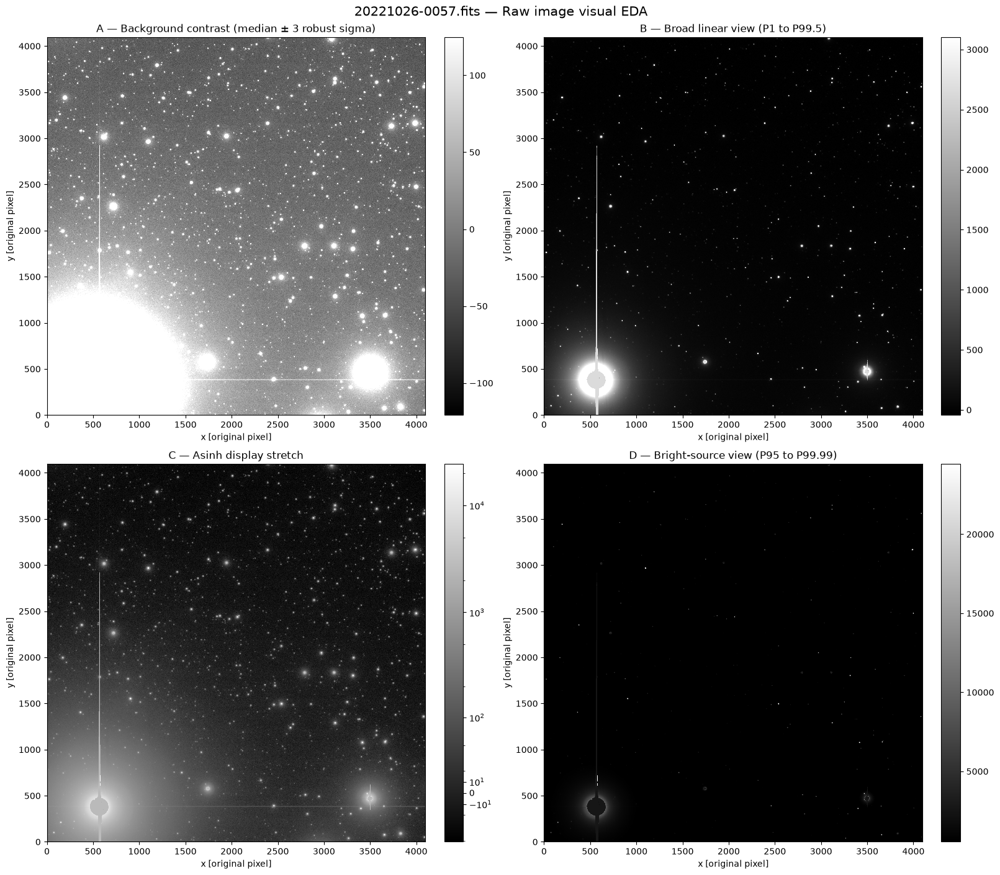

Display image shape: (2048, 2048)
Display bin factor: 2

Display limits
--------------
Background: -120.8355948265951 124.75710862244776
Broad: -43.145992279052734 3102.377685546875
Asinh: -51.44696044921875 24444.98828125
Bright sources: 540.7901000976562 24444.98828125

Saved: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/20221026-0057_raw_multistretch.png
Memory: {'process_rss_gib': 0.385, 'available_ram_gib': 6.467}


In [7]:
# ============================================================
# CELL 6 — FULL-FRAME MULTI-STRETCH VISUAL EDA
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.colors import AsinhNorm
from scipy import ndimage as ndi

# ------------------------------------------------------------
# 1. Memory-conscious display image
# ------------------------------------------------------------

# 2x2 block-mean binning.
# This is a display-only representation.
# The scientific raw data remains unchanged.

DISPLAY_BIN = 2

h, w = image_raw.shape

display_image = (
    image_raw
    .reshape(
        h // DISPLAY_BIN,
        DISPLAY_BIN,
        w // DISPLAY_BIN,
        DISPLAY_BIN
    )
    .mean(axis=(1, 3))
)

display_h = h // DISPLAY_BIN
display_w = w // DISPLAY_BIN

# Map display coordinates back to original image coordinates.
display_extent = (
    0,
    w,
    0,
    h
)


# ------------------------------------------------------------
# 2. Define display stretches from raw statistics
# ------------------------------------------------------------

display_median = raw_median
display_sigma = raw_robust_sigma

# Background contrast:
# approximately +/- 3 robust sigma around the median.
background_vmin = (
    display_median - 3.0 * display_sigma
)

background_vmax = (
    display_median + 3.0 * display_sigma
)


# Broad image view.
broad_vmin = float(
    np.percentile(display_image, 1)
)

broad_vmax = float(
    np.percentile(display_image, 99.5)
)


# Bright-source view.
bright_vmin = float(
    np.percentile(display_image, 95)
)

bright_vmax = float(
    np.percentile(display_image, 99.99)
)


# Asinh stretch.
asinh_vmin = float(
    np.percentile(display_image, 0.1)
)

asinh_vmax = float(
    np.percentile(display_image, 99.99)
)

asinh_norm = AsinhNorm(
    linear_width=display_sigma,
    vmin=asinh_vmin,
    vmax=asinh_vmax
)


# ------------------------------------------------------------
# 3. Create the diagnostic figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 14),
    constrained_layout=True
)

# A. Background contrast.
im0 = axes[0, 0].imshow(
    display_image,
    origin="lower",
    extent=display_extent,
    cmap="gray",
    vmin=background_vmin,
    vmax=background_vmax,
    interpolation="nearest"
)

axes[0, 0].set_title(
    "A — Background contrast "
    "(median ± 3 robust sigma)"
)

axes[0, 0].set_xlabel("x [original pixel]")
axes[0, 0].set_ylabel("y [original pixel]")

fig.colorbar(
    im0,
    ax=axes[0, 0],
    fraction=0.046,
    pad=0.04
)


# B. Broad percentile-linear view.
im1 = axes[0, 1].imshow(
    display_image,
    origin="lower",
    extent=display_extent,
    cmap="gray",
    vmin=broad_vmin,
    vmax=broad_vmax,
    interpolation="nearest"
)

axes[0, 1].set_title(
    "B — Broad linear view "
    "(P1 to P99.5)"
)

axes[0, 1].set_xlabel("x [original pixel]")
axes[0, 1].set_ylabel("y [original pixel]")

fig.colorbar(
    im1,
    ax=axes[0, 1],
    fraction=0.046,
    pad=0.04
)


# C. Asinh view.
im2 = axes[1, 0].imshow(
    display_image,
    origin="lower",
    extent=display_extent,
    cmap="gray",
    norm=asinh_norm,
    interpolation="nearest"
)

axes[1, 0].set_title(
    "C — Asinh display stretch"
)

axes[1, 0].set_xlabel("x [original pixel]")
axes[1, 0].set_ylabel("y [original pixel]")

fig.colorbar(
    im2,
    ax=axes[1, 0],
    fraction=0.046,
    pad=0.04
)


# D. Bright-source view.
im3 = axes[1, 1].imshow(
    display_image,
    origin="lower",
    extent=display_extent,
    cmap="gray",
    vmin=bright_vmin,
    vmax=bright_vmax,
    interpolation="nearest"
)

axes[1, 1].set_title(
    "D — Bright-source view "
    "(P95 to P99.99)"
)

axes[1, 1].set_xlabel("x [original pixel]")
axes[1, 1].set_ylabel("y [original pixel]")

fig.colorbar(
    im3,
    ax=axes[1, 1],
    fraction=0.046,
    pad=0.04
)


fig.suptitle(
    f"{FRAME_FILENAME} — Raw image visual EDA",
    fontsize=15
)

# Save without modifying the original image.
FIGURE_PATH = (
    FRAME_OUTPUT_DIR /
    f"{Path(FRAME_FILENAME).stem}_raw_multistretch.png"
)

fig.savefig(
    FIGURE_PATH,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


print("Display image shape:", display_image.shape)
print("Display bin factor:", DISPLAY_BIN)

print("\nDisplay limits")
print("--------------")

print("Background:", background_vmin, background_vmax)
print("Broad:", broad_vmin, broad_vmax)
print("Asinh:", asinh_vmin, asinh_vmax)
print("Bright sources:", bright_vmin, bright_vmax)

print("\nSaved:", FIGURE_PATH)
print("Memory:", memory_report())

### Observations

* A. There are two particularly problematic bright sources
The most prominent ones are approximately:
* * Source A: \((550, 400)\)
* * Source B: \((3500, 470)\)

Source A has a very extended halo, while source B also has visible extended structure.

These are the first objects we will investigate during source extraction. We should not assume that a circular mask around each one will be sufficient.

* B. There are prominent horizontal and vertical linear structures

The raw image visibly contains:
* * A nearly vertical structure around \(x\approx550\), extending from the lower part of the frame towards \(y\approx3000\).
* * A nearly horizontal structure around \(y\approx380\), extending from around \(x\approx550\) towards the right edge.
Their proximity to the bright sources makes them particularly interesting.

They could be detector-related structures, charge bleeding, diffraction or another optical/electronic effect. We cannot classify them from this display alone.

This is exactly why we need row-wise and column-wise diagnostics before constructing masks.

* C. The background is spatially non-uniform
The lower-left region is noticeably brighter than much of the upper-right region.

This indicates that a single global background estimate will probably be inadequate.

We need to measure the spatial variation before selecting a background model.

* D. The target diagonal is not clearly identifiable in these views
The manually annotated diagonal is not convincingly visible at full-frame scale. I would not conclude that it is absent.

The feature could be faint relative to the local background, and the large bright-source structures complicate its visual inspection.

We will eventually need a narrow, straightened view along the annotated corridor.

### Spatial background and detector-pattern analysis

Now we need to answer three questions:
1. Does the background change gradually across the frame?
2. Are particular rows or columns systematically brighter or darker?
3. Are the apparent horizontal and vertical structures localised features or part of a wider detector pattern?

We will use tile statistics and row/column profiles.

Divide the image into spatial tiles. Imagine dividing the 4096 × 4096 image into small squares.

Each square gets three measurements:
- Median pixel value.
- Robust spread of pixel values.
- 99th percentile.

We can then construct three maps showing how these quantities change across the detector.

For this first pass, use 128 × 128 pixel tiles. That gives us a 32 × 32 diagnostic grid.

Important: these are diagnostic measurements. A tile's robust spread is not automatically the detector's noise sigma. Stars and other structures can increase it.

SPATIAL TILE ANALYSIS
---------------------
Tile size: 128
Grid: (32, 32)

Tile median distribution
Minimum: -35.80615997314453
Median: -2.5149834156036377
Maximum: 4116.564453125

Tile robust-spread distribution
Minimum: 0.0
Median: 18.459716796875
Maximum: 2174.211181640625
10 HIGHEST-MEDIAN TILES
-----------------------
{'tile_x': 3, 'tile_y': 3, 'x_range': (384, 512), 'y_range': (384, 512), 'value': 4116.564453125}
{'tile_x': 3, 'tile_y': 2, 'x_range': (384, 512), 'y_range': (256, 384), 'value': 4116.357421875}
{'tile_x': 5, 'tile_y': 2, 'x_range': (640, 768), 'y_range': (256, 384), 'value': 3512.14501953125}
{'tile_x': 5, 'tile_y': 3, 'x_range': (640, 768), 'y_range': (384, 512), 'value': 3400.89599609375}
{'tile_x': 4, 'tile_y': 3, 'x_range': (512, 640), 'y_range': (384, 512), 'value': 2650.081298828125}
{'tile_x': 4, 'tile_y': 4, 'x_range': (512, 640), 'y_range': (512, 640), 'value': 2650.081298828125}
{'tile_x': 4, 'tile_y': 2, 'x_range': (512, 640), 'y_range': (256, 384), 'val

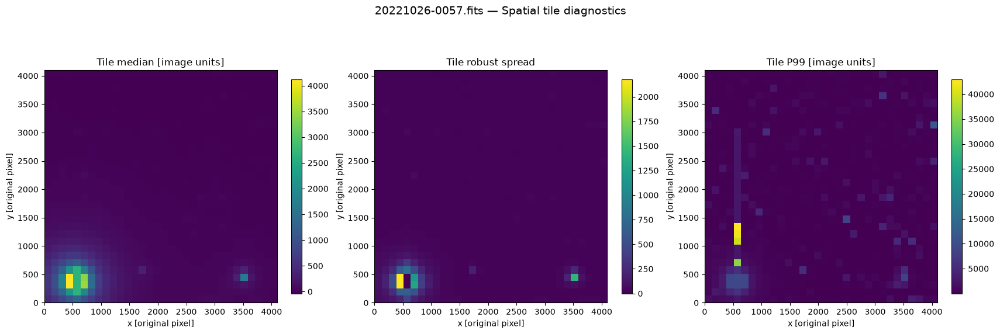


Saved: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/20221026-0057_spatial_tiles.png
Memory: {'process_rss_gib': 0.387, 'available_ram_gib': 6.366}


In [8]:
# ============================================================
# CELL 7 — SPATIAL TILE STATISTICS
# ============================================================

TILE_SIZE = 128

h, w = image_raw.shape

if h % TILE_SIZE != 0 or w % TILE_SIZE != 0:
    raise ValueError("Image dimensions must be divisible by TILE_SIZE.")

n_tiles_y = h // TILE_SIZE
n_tiles_x = w // TILE_SIZE

tile_median = np.full(
    (n_tiles_y, n_tiles_x),
    np.nan,
    dtype=np.float32
)

tile_robust_spread = np.full_like(tile_median, np.nan)
tile_p99 = np.full_like(tile_median, np.nan)

# ------------------------------------------------------------
# Calculate tile statistics without constructing a giant
# temporary array.
# ------------------------------------------------------------

for iy in range(n_tiles_y):

    y0 = iy * TILE_SIZE
    y1 = y0 + TILE_SIZE

    for ix in range(n_tiles_x):

        x0 = ix * TILE_SIZE
        x1 = x0 + TILE_SIZE

        tile = image_raw[y0:y1, x0:x1]

        values = tile[np.isfinite(tile)]

        if values.size == 0:
            continue

        med = np.median(values)

        mad = np.median(
            np.abs(values - med)
        )

        tile_median[iy, ix] = med

        tile_robust_spread[iy, ix] = (
            1.4826022185 * mad
        )

        tile_p99[iy, ix] = np.percentile(
            values,
            99
        )


# ------------------------------------------------------------
# Tile map statistics
# ------------------------------------------------------------

print("SPATIAL TILE ANALYSIS")
print("---------------------")

print("Tile size:", TILE_SIZE)
print("Grid:", tile_median.shape)

print("\nTile median distribution")

print(
    "Minimum:",
    float(np.nanmin(tile_median))
)

print(
    "Median:",
    float(np.nanmedian(tile_median))
)

print(
    "Maximum:",
    float(np.nanmax(tile_median))
)

print("\nTile robust-spread distribution")

print(
    "Minimum:",
    float(np.nanmin(tile_robust_spread))
)

print(
    "Median:",
    float(np.nanmedian(tile_robust_spread))
)

print(
    "Maximum:",
    float(np.nanmax(tile_robust_spread))
)


# ------------------------------------------------------------
# Identify the 10 brightest and darkest tiles by median
# ------------------------------------------------------------

# ============================================================
# CELL 7.1 — CORRECTED TILE EXTREMES
# ============================================================

def extreme_tiles(array, count=10, largest=False):

    flat = np.asarray(array).ravel()

    valid = np.flatnonzero(
        np.isfinite(flat)
    )

    order = np.argsort(flat[valid])

    if largest:
        selected = valid[order[-count:][::-1]]
    else:
        selected = valid[order[:count]]

    result = []

    for index in selected:

        iy, ix = np.unravel_index(
            index,
            array.shape
        )

        result.append({
            "tile_x": int(ix),
            "tile_y": int(iy),

            "x_range": (
                int(ix * TILE_SIZE),
                int((ix + 1) * TILE_SIZE)
            ),

            "y_range": (
                int(iy * TILE_SIZE),
                int((iy + 1) * TILE_SIZE)
            ),

            "value": float(array[iy, ix])
        })

    return result


print("10 HIGHEST-MEDIAN TILES")
print("-----------------------")

for item in extreme_tiles(
    tile_median,
    count=10,
    largest=True
):
    print(item)


print("\n10 HIGHEST-SPREAD TILES")
print("-----------------------")

for item in extreme_tiles(
    tile_robust_spread,
    count=10,
    largest=True
):
    print(item)


# ------------------------------------------------------------
# Visualise spatial maps
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 6),
    constrained_layout=True
)

maps = [
    (tile_median, "Tile median [image units]"),
    (tile_robust_spread, "Tile robust spread"),
    (tile_p99, "Tile P99 [image units]")
]

for ax, (array, title) in zip(axes, maps):

    im = ax.imshow(
        array,
        origin="lower",
        extent=(0, w, 0, h),
        interpolation="nearest",
        aspect="equal"
    )

    ax.set_title(title)
    ax.set_xlabel("x [original pixel]")
    ax.set_ylabel("y [original pixel]")

    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )


fig.suptitle(
    f"{FRAME_FILENAME} — Spatial tile diagnostics",
    fontsize=14
)

TILE_FIGURE_PATH = (
    FRAME_OUTPUT_DIR /
    f"{Path(FRAME_FILENAME).stem}_spatial_tiles.png"
)

fig.savefig(
    TILE_FIGURE_PATH,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved:", TILE_FIGURE_PATH)
print("Memory:", memory_report())

* Tile median map: reveals broad background gradients and local offset patterns.

* Tile robust-spread map: reveals regions with greater pixel variation. Bright stars, halos and structured backgrounds may increase this value.

* Tile P99 map: reveals where bright-source contamination is concentrated.

### Row-wise and column-wise profiles
This cell is particularly important because of the apparent horizontal and vertical features.

We will calculate the median, 95th percentile and 99th percentile for each row and column.

Why three statistics?

say Considering a bright feature running along a row:
- Its row median may barely change if it occupies only a small fraction of the row.
- Its 95th percentile may change substantially.
- Its 99th percentile may be even more sensitive to a bright local structure.
The same applies to columns.

ROW PROFILE OUTLIERS
--------------------
Row  384 | Median=   189.119 | P95=  2848.254 | P99=  7405.524 | Robust Z=    5.20
Row  383 | Median=   186.024 | P95=  2763.437 | P99=  7256.718 | Robust Z=    5.12
Row  385 | Median=   180.358 | P95=  2886.860 | P99=  7350.691 | Robust Z=    4.96
Row  386 | Median=   171.435 | P95=  2912.155 | P99=  7621.683 | Robust Z=    4.71
Row  382 | Median=   165.108 | P95=  2741.646 | P99=  7072.448 | Robust Z=    4.54
Row  387 | Median=   154.226 | P95=  2911.881 | P99=  7668.600 | Robust Z=    4.23
Row  381 | Median=   149.231 | P95=  2700.594 | P99=  7044.435 | Robust Z=    4.10
Row  501 | Median=   138.861 | P95=  3707.207 | P99=  6556.466 | Robust Z=    3.81
Row  380 | Median=   138.231 | P95=  2661.404 | P99=  7009.730 | Robust Z=    3.79
Row  500 | Median=   137.572 | P95=  3756.266 | P99=  6693.061 | Robust Z=    3.77

COLUMN PROFILE OUTLIERS
-----------------------
Column  566 | Median=  2650.081 | P95=  2650.081 | P99=  2650.081 | Robust Z=  

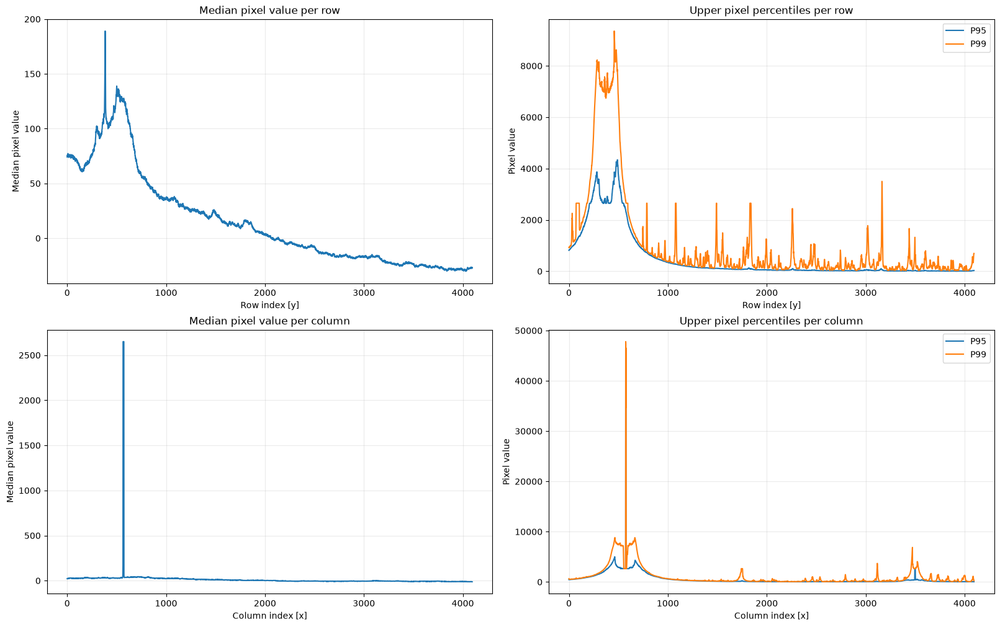


Saved: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/20221026-0057_row_column_profiles.png
Memory: {'process_rss_gib': 0.389, 'available_ram_gib': 6.352}


In [9]:
# ============================================================
# CELL 8 — ROW AND COLUMN PROFILE ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. Row profiles
# ------------------------------------------------------------

row_median = np.median(
    image_raw,
    axis=1
)

row_p95 = np.percentile(
    image_raw,
    95,
    axis=1
)

row_p99 = np.percentile(
    image_raw,
    99,
    axis=1
)


# ------------------------------------------------------------
# 2. Column profiles
# ------------------------------------------------------------

col_median = np.median(
    image_raw,
    axis=0
)

col_p95 = np.percentile(
    image_raw,
    95,
    axis=0
)

col_p99 = np.percentile(
    image_raw,
    99,
    axis=0
)


# ------------------------------------------------------------
# 3. Robust anomalies in row/column medians
# ------------------------------------------------------------

def robust_zscore(values):

    values = np.asarray(values, dtype=np.float64)

    med = np.median(values)

    mad = np.median(
        np.abs(values - med)
    )

    sigma = 1.4826022185 * mad

    if sigma <= 0:
        return np.zeros_like(values)

    return (values - med) / sigma


row_median_z = robust_zscore(row_median)
col_median_z = robust_zscore(col_median)


# ------------------------------------------------------------
# 4. Print strongest row/column median excursions
# ------------------------------------------------------------

N_EXTREMES = 10

row_order = np.argsort(
    np.abs(row_median_z)
)[::-1][:N_EXTREMES]

col_order = np.argsort(
    np.abs(col_median_z)
)[::-1][:N_EXTREMES]

print("ROW PROFILE OUTLIERS")
print("--------------------")

for index in row_order:

    print(
        f"Row {index:4d} | "
        f"Median={row_median[index]:10.3f} | "
        f"P95={row_p95[index]:10.3f} | "
        f"P99={row_p99[index]:10.3f} | "
        f"Robust Z={row_median_z[index]:8.2f}"
    )


print("\nCOLUMN PROFILE OUTLIERS")
print("-----------------------")

for index in col_order:

    print(
        f"Column {index:4d} | "
        f"Median={col_median[index]:10.3f} | "
        f"P95={col_p95[index]:10.3f} | "
        f"P99={col_p99[index]:10.3f} | "
        f"Robust Z={col_median_z[index]:8.2f}"
    )


# ------------------------------------------------------------
# 5. Plot profiles
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
    constrained_layout=True
)

x_rows = np.arange(h)
x_cols = np.arange(w)

# Row median
axes[0, 0].plot(
    x_rows,
    row_median
)

axes[0, 0].set_title("Median pixel value per row")
axes[0, 0].set_xlabel("Row index [y]")
axes[0, 0].set_ylabel("Median pixel value")
axes[0, 0].grid(alpha=0.25)


# Row upper percentiles
axes[0, 1].plot(
    x_rows,
    row_p95,
    label="P95"
)

axes[0, 1].plot(
    x_rows,
    row_p99,
    label="P99"
)

axes[0, 1].set_title("Upper pixel percentiles per row")
axes[0, 1].set_xlabel("Row index [y]")
axes[0, 1].set_ylabel("Pixel value")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.25)


# Column median
axes[1, 0].plot(
    x_cols,
    col_median
)

axes[1, 0].set_title("Median pixel value per column")
axes[1, 0].set_xlabel("Column index [x]")
axes[1, 0].set_ylabel("Median pixel value")
axes[1, 0].grid(alpha=0.25)


# Column upper percentiles
axes[1, 1].plot(
    x_cols,
    col_p95,
    label="P95"
)

axes[1, 1].plot(
    x_cols,
    col_p99,
    label="P99"
)

axes[1, 1].set_title("Upper pixel percentiles per column")
axes[1, 1].set_xlabel("Column index [x]")
axes[1, 1].set_ylabel("Pixel value")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.25)


PROFILE_FIGURE_PATH = (
    FRAME_OUTPUT_DIR /
    f"{Path(FRAME_FILENAME).stem}_row_column_profiles.png"
)

fig.savefig(
    PROFILE_FIGURE_PATH,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved:", PROFILE_FIGURE_PATH)
print("Memory:", memory_report())

### Interpretation
If the vertical structure at \(x = approx 550\) creates a substantial column-wide pattern, the corresponding column statistics may show an anomaly.

If the horizontal structure at \(y = approx 380\) is strong over a substantial fraction of the row, the row statistics may show an anomaly.

However, a local feature can be diluted by thousands of other pixels in its row or column. Therefore, a lack of a strong median outlier does not prove that the feature is absent.

That is why we are combining row/column profiles with the spatial tile maps.

---

**What the spatial maps reveal**

**A. The background is strongly non-uniform**

Our row-median profile changes substantially across the detector:
- Around \(y=0\): approximately \(75\).
- Around \(y=384\): approximately \(189\).
- Around \(y=500\): approximately \(139\).
- Around \(y=2000\): close to zero.
- Near \(y=4000\): approximately \(-30\).
This is a substantial spatial variation.

The important point is that the background is not simply a constant offset. It has a strong large-scale gradient, particularly along the vertical direction.

A single global background subtraction would therefore be inappropriate.

We need a two-dimensional background model, but we must choose its spatial scale carefully. A model that is too flexible could remove the faint streak along with the background.

**B. The lower-left bright source dominates the local statistics**

The tile median and robust-spread maps show a large region of elevated values around the source near \((550,400)\).

The robust spread reaches approximately 2174 in some tiles, compared with a median tile spread of approximately 18.46.

This tells us that the source affects much more than its central few pixels. There is substantial surrounding structure.

We will need to distinguish its compact core, extended halo and any associated linear artefacts.

The second bright source near \((3500,470)\) also needs to be investigated, but the lower-left source is the more severe contamination in these maps.

**C. As per the column profile output, there is an extremely suspicious group of columns**

Column 565 | Median = 2650.081
Column 566 | Median = 2650.081
...
Column 573 | Median = 2650.081

For these columns, even P95 and P99 are exactly the same value.

That is highly unusual.

It suggests that a large fraction of the pixels in these columns may have been assigned one repeated value. The pattern is consistent with a constant-valued column defect or fill region.

It is not enough evidence to call it saturation. The image maximum is 64366, substantially higher than 2650.081.

We need to determine whether these are:
- Full-height columns with a constant value.
- Long sections of defective columns.
- A special fill value applied during previous data processing.
- Another unusual detector or acquisition artefact.
This matters because a vertical structure of this type could trigger a linear-feature detector.

### Investigate the suspicious columns

Repeated-value and column-defect investigation

This cell will:

1. Identify the most frequent exact value in the suspicious region.
2. Measure how many pixels in each column equal that value.
3. Find consecutive columns dominated by it.
4. Determine whether the repeated values extend through the entire detector.
5. Plot the full-height region at higher spatial resolution.

REPEATED-VALUE INVESTIGATION
----------------------------
Inspection region: (545, 590)
Most frequent value: 2650.081298828125
Occurrences: 44228
Fraction of inspection region: 0.239952

COLUMN-BY-COLUMN DIAGNOSTICS
----------------------------
x= 545 | matching=0.0474 | median=31.5898 | P95=2650.0813 | P99=7157.7119 | unique=3903
x= 546 | matching=0.0471 | median=33.1274 | P95=2654.9700 | P99=7222.6050 | unique=3904
x= 547 | matching=0.0476 | median=30.8087 | P95=2654.4490 | P99=7223.0903 | unique=3902
x= 548 | matching=0.0476 | median=30.7146 | P95=2650.0813 | P99=7151.7480 | unique=3902
x= 549 | matching=0.0481 | median=30.7580 | P95=2650.0813 | P99=7135.2212 | unique=3900
x= 550 | matching=0.0503 | median=32.3810 | P95=2650.0813 | P99=6728.6494 | unique=3891
x= 551 | matching=0.0549 | median=32.1606 | P95=2650.0813 | P99=5780.3818 | unique=3872
x= 552 | matching=0.0613 | median=31.2545 | P95=2650.0813 | P99=4665.4429 | unique=3846
x= 553 | matching=0.0686 | median=31.9646 | P95=265

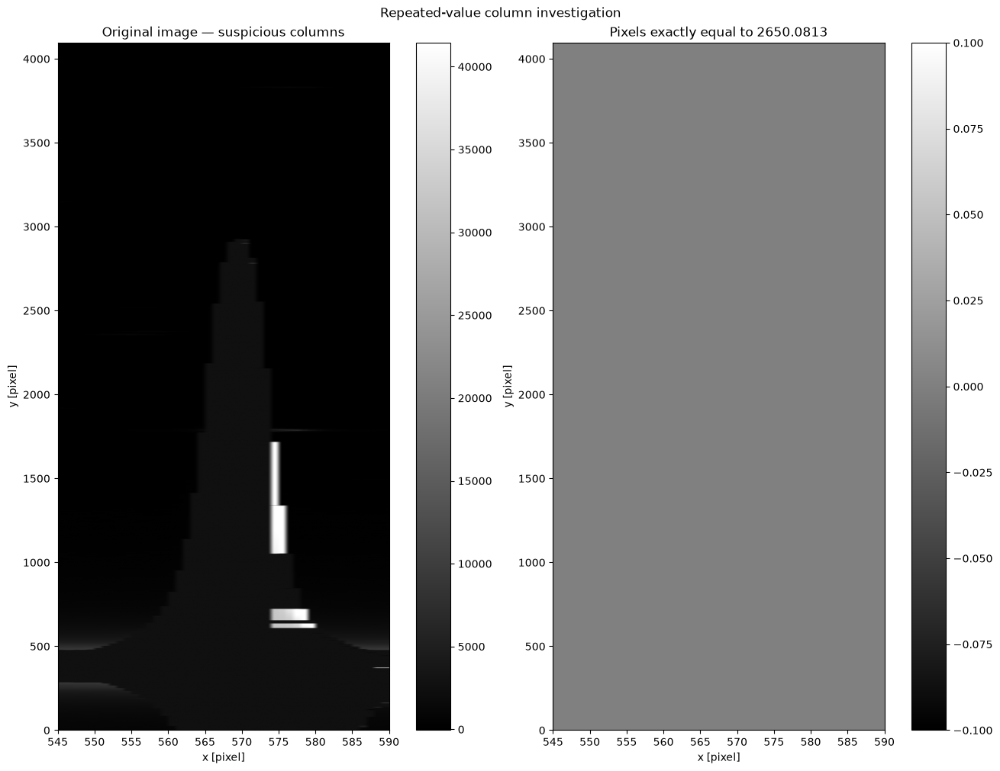


Saved: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/repeated_value_column_investigation.png
Memory: {'process_rss_gib': 0.409, 'available_ram_gib': 6.276}


In [10]:
# ============================================================
# CELL 9 — INVESTIGATE REPEATED-VALUE COLUMNS
# ============================================================

# ------------------------------------------------------------
# 1. Inspect a local region around the suspicious columns
# ------------------------------------------------------------

X0 = 545
X1 = 590

column_strip = image_raw[:, X0:X1]

values, counts = np.unique(
    column_strip,
    return_counts=True
)

mode_index = np.argmax(counts)

SUSPECT_CONSTANT_VALUE = np.float32(
    values[mode_index]
)

SUSPECT_CONSTANT_COUNT = int(
    counts[mode_index]
)

print("REPEATED-VALUE INVESTIGATION")
print("----------------------------")

print("Inspection region:", (X0, X1))
print("Most frequent value:", float(SUSPECT_CONSTANT_VALUE))
print("Occurrences:", SUSPECT_CONSTANT_COUNT)

print(
    "Fraction of inspection region:",
    round(
        SUSPECT_CONSTANT_COUNT / column_strip.size,
        6
    )
)


# ------------------------------------------------------------
# 2. Examine every column in the region
# ------------------------------------------------------------

column_diagnostics = []

for x in range(X0, X1):

    col = image_raw[:, x]

    equal_count = int(
        np.count_nonzero(
            col == SUSPECT_CONSTANT_VALUE
        )
    )

    fraction = equal_count / len(col)

    column_diagnostics.append({

        "x": x,

        "matching_pixels": equal_count,

        "matching_fraction": fraction,

        "median": float(np.median(col)),

        "p95": float(np.percentile(col, 95)),

        "p99": float(np.percentile(col, 99)),

        "unique_values": int(np.unique(col).size)

    })


print("\nCOLUMN-BY-COLUMN DIAGNOSTICS")
print("----------------------------")

for item in column_diagnostics:

    print(
        f"x={item['x']:4d} | "
        f"matching={item['matching_fraction']:.4f} | "
        f"median={item['median']:.4f} | "
        f"P95={item['p95']:.4f} | "
        f"P99={item['p99']:.4f} | "
        f"unique={item['unique_values']}"
    )


# ------------------------------------------------------------
# 3. Identify strongly affected columns
# ------------------------------------------------------------

AFFECTED_COLUMN_THRESHOLD = 0.95

affected_columns = [

    item["x"]
    for item in column_diagnostics

    if item["matching_fraction"] >=
       AFFECTED_COLUMN_THRESHOLD
]


print("\nSTRONGLY AFFECTED COLUMNS")
print("-------------------------")

print(affected_columns)


# ------------------------------------------------------------
# 4. Examine whether the affected columns form a
# continuous full-height structure
# ------------------------------------------------------------

if affected_columns:

    x_start = min(affected_columns)
    x_end = max(affected_columns) + 1

    affected_mask = (
        image_raw[:, x_start:x_end]
        == SUSPECT_CONSTANT_VALUE
    )

    # Rows where every column in the suspected block has
    # exactly the same repeated value.
    full_block_rows = np.all(
        affected_mask,
        axis=1
    )

    full_block_fraction = float(
        full_block_rows.mean()
    )

    print("\nFULL-BLOCK TEST")
    print("---------------")

    print("Columns:", (x_start, x_end - 1))

    print(
        "Rows where all columns match:",
        int(full_block_rows.sum())
    )

    print(
        "Fraction of detector height:",
        round(full_block_fraction, 6)
    )

    # Find continuous row intervals.
    edges = np.diff(
        np.r_[False, full_block_rows, False].astype(int)
    )

    starts = np.where(edges == 1)[0]
    stops = np.where(edges == -1)[0]

    row_runs = list(
        zip(starts.tolist(), stops.tolist())
    )

    print("Continuous row intervals:", row_runs)

else:

    affected_mask = np.zeros(
        column_strip.shape,
        dtype=bool
    )

    full_block_fraction = 0.0

    print(
        "No columns met the selected "
        "95% repeated-value criterion."
    )


# ------------------------------------------------------------
# 5. Count the repeated value across the entire image
# ------------------------------------------------------------

global_repeat_count = int(
    np.count_nonzero(
        image_raw == SUSPECT_CONSTANT_VALUE
    )
)

print("\nGLOBAL OCCURRENCE")
print("-----------------")

print("Repeated value:", float(SUSPECT_CONSTANT_VALUE))

print("Global count:", global_repeat_count)

print(
    "Global fraction:",
    global_repeat_count / image_raw.size
)


# ------------------------------------------------------------
# 6. Visualise the suspect columns
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 10),
    constrained_layout=True
)

# Original narrow strip.
vmin = np.percentile(column_strip, 1)
vmax = np.percentile(column_strip, 99.5)

im0 = axes[0].imshow(
    column_strip,
    origin="lower",
    aspect="auto",
    cmap="gray",
    vmin=vmin,
    vmax=vmax,
    extent=(X0, X1, 0, image_raw.shape[0])
)

axes[0].set_title(
    "Original image — suspicious columns"
)

axes[0].set_xlabel("x [pixel]")
axes[0].set_ylabel("y [pixel]")

fig.colorbar(im0, ax=axes[0])


# Exact-value mask.
im1 = axes[1].imshow(
    affected_mask,
    origin="lower",
    aspect="auto",
    cmap="gray",
    extent=(X0, X1, 0, image_raw.shape[0]),
    interpolation="nearest"
)

axes[1].set_title(
    f"Pixels exactly equal to {float(SUSPECT_CONSTANT_VALUE):.4f}"
)

axes[1].set_xlabel("x [pixel]")
axes[1].set_ylabel("y [pixel]")

fig.colorbar(im1, ax=axes[1])


fig.suptitle(
    "Repeated-value column investigation"
)

REPEATED_VALUE_FIGURE = (
    FRAME_OUTPUT_DIR /
    "repeated_value_column_investigation.png"
)

fig.savefig(
    REPEATED_VALUE_FIGURE,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved:", REPEATED_VALUE_FIGURE)
print("Memory:", memory_report())

### INterpretation

**A. The repeated value is significant**
The value 2650.081298828125 occurs:

- 72,427 times across the image.
- 44,228 times within columns 545–589.
- 0.432% of all image pixels.

Most importantly, columns 565–573 have between approximately 53% and 71% of their pixels equal to this value.

That is unusual, but the 95% threshold was too strict: no column passed it.

**B. These are not demonstrated full-height bad columns**

The image has a striking spatially localised pattern around the bright source near \((550,400)\). The repeated-value fractions increase towards columns 565–573 and decrease again outside them.

That pattern suggests a local two-dimensional structure rather than nine uniformly defective detector columns.

Possible explanations include a clipped or quantised region, a fill-value region introduced during processing, or a source-related structure. The present evidence does not distinguish these explanations.

We must not label it saturation yet. The maximum pixel value is 64,366, while the repeated value is 2,650.08. It is not the maximum-value plateau we would normally investigate first.

### Inspect the two dominant sources at native resolution

Now we need to understand the two bright sources themselves.

We will inspect them in separate cutouts. The purpose is to distinguish:
- Compact cores.
- Extended halos.
- Saturated or flattened regions.
- Vertical or horizontal linear structures.
- Nearby ordinary stars.
Use native-resolution cutouts rather than the 2× binned display.

### Map the repeated-value structure across the entire image

It will answer:
1. Where are all 72,427 repeated-value pixels?
2. Are they one connected region or several separate regions?
3. Do they form a local source-related shape?
4. Do any affected columns contain uninterrupted full-height runs?
5. What is the boundary between repeated-value pixels and surrounding image values?

GLOBAL REPEATED-VALUE MASK
--------------------------
Value: 2650.081298828125
Count: 72427
Fraction: 0.004316985607147217

GLOBAL BOUNDING BOX
-------------------
{'x_min': 464, 'x_max': 3837, 'y_min': 0, 'y_max': 4091}

Most affected rows
y= 383 | matching pixels=212
y= 385 | matching pixels=212
y= 382 | matching pixels=212
y= 387 | matching pixels=211
y= 381 | matching pixels=211
y= 384 | matching pixels=211
y= 388 | matching pixels=210
y= 386 | matching pixels=210
y= 379 | matching pixels=209
y= 389 | matching pixels=209

Most affected columns
x= 569 | matching pixels=2927
x= 568 | matching pixels=2910
x= 570 | matching pixels=2907
x= 571 | matching pixels=2807
x= 567 | matching pixels=2788
x= 572 | matching pixels=2552
x= 566 | matching pixels=2542
x= 565 | matching pixels=2186
x= 573 | matching pixels=2155
x= 564 | matching pixels=1774

CONNECTED COMPONENTS
---------------------
Number of components: 12

Largest 12 components
{'label': 1, 'area_pixels': 66656, 'x_range': (464, 66

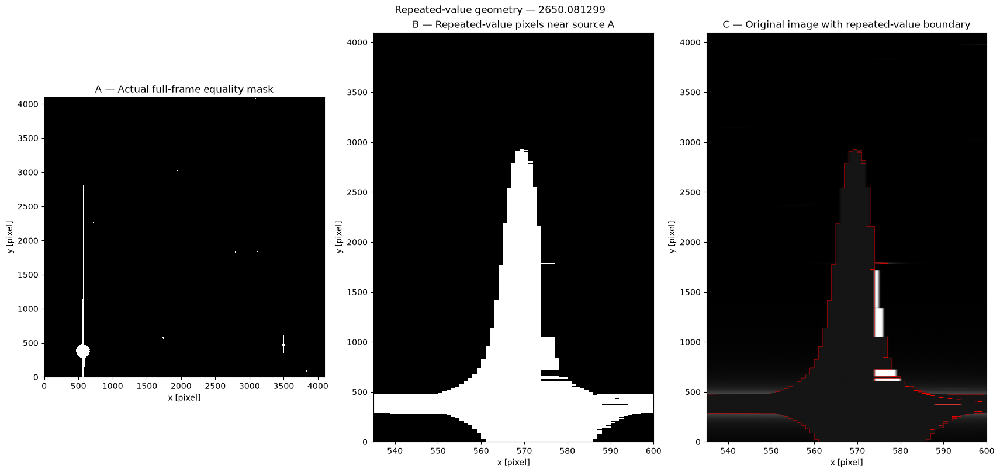


Saved: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/repeated_value_global_geometry.png
Memory: {'process_rss_gib': 0.512, 'available_ram_gib': 6.111}


In [11]:
# ============================================================
# CELL 9.1 — GLOBAL GEOMETRY OF THE REPEATED-VALUE REGION
# ============================================================

from scipy import ndimage as ndi
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Construct the actual full-frame equality mask
# ------------------------------------------------------------

repeat_value = np.float32(SUSPECT_CONSTANT_VALUE)

repeat_mask = (
    image_raw == repeat_value
)

repeat_count = int(repeat_mask.sum())

print("GLOBAL REPEATED-VALUE MASK")
print("--------------------------")

print("Value:", float(repeat_value))
print("Count:", repeat_count)
print("Fraction:", repeat_count / image_raw.size)

if repeat_count == 0:
    raise RuntimeError("Repeated-value mask unexpectedly empty.")


# ------------------------------------------------------------
# 2. Coordinate bounds of all matching pixels
# ------------------------------------------------------------

yy, xx = np.nonzero(repeat_mask)

global_bbox = {
    "x_min": int(xx.min()),
    "x_max": int(xx.max()),
    "y_min": int(yy.min()),
    "y_max": int(yy.max())
}

print("\nGLOBAL BOUNDING BOX")
print("-------------------")

print(global_bbox)

# Row/column occupancy.
repeat_count_per_row = repeat_mask.sum(axis=1)
repeat_count_per_column = repeat_mask.sum(axis=0)

print("\nMost affected rows")

for y in np.argsort(repeat_count_per_row)[-10:][::-1]:
    print(
        f"y={y:4d} | "
        f"matching pixels={int(repeat_count_per_row[y])}"
    )

print("\nMost affected columns")

for x in np.argsort(repeat_count_per_column)[-10:][::-1]:
    print(
        f"x={x:4d} | "
        f"matching pixels={int(repeat_count_per_column[x])}"
    )


# ------------------------------------------------------------
# 3. Connected-component analysis
# ------------------------------------------------------------

# 8-connectivity: diagonal neighbours belong to the same component.
structure = np.ones((3, 3), dtype=np.uint8)

labels, n_components = ndi.label(
    repeat_mask,
    structure=structure
)

component_sizes = np.bincount(
    labels.ravel()
)[1:]

print("\nCONNECTED COMPONENTS")
print("---------------------")

print("Number of components:", n_components)

if n_components:

    top_n = min(15, n_components)

    top_labels = (
        np.argsort(component_sizes)[-top_n:][::-1] + 1
    )

    component_slices = ndi.find_objects(
        labels,
        max_label=n_components
    )

    print(f"\nLargest {top_n} components")

    for label_id in top_labels:

        bbox = component_slices[label_id - 1]

        if bbox is None:
            continue

        ys, xs = bbox

        print({
            "label": int(label_id),
            "area_pixels": int(component_sizes[label_id - 1]),
            "x_range": (xs.start, xs.stop - 1),
            "y_range": (ys.start, ys.stop - 1)
        })


# ------------------------------------------------------------
# 4. Longest consecutive repeated-value run per column
# ------------------------------------------------------------

def longest_true_run(boolean_array):

    boolean_array = np.asarray(
        boolean_array,
        dtype=bool
    )

    edges = np.diff(
        np.r_[False, boolean_array, False].astype(np.int8)
    )

    starts = np.where(edges == 1)[0]
    stops = np.where(edges == -1)[0]

    if len(starts) == 0:
        return None

    lengths = stops - starts

    index = int(np.argmax(lengths))

    return (
        int(starts[index]),
        int(stops[index] - 1),
        int(lengths[index])
    )


print("\nLONGEST RUNS IN SUSPICIOUS COLUMNS")
print("----------------------------------")

for x in range(545, 590):

    run = longest_true_run(repeat_mask[:, x])

    if run is not None and run[2] >= 10:

        print(
            f"x={x:4d} | "
            f"start_y={run[0]:4d} | "
            f"end_y={run[1]:4d} | "
            f"length={run[2]:4d}"
        )


# ------------------------------------------------------------
# 5. Visualise the actual equality mask
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 8),
    constrained_layout=True
)

# A. Full-frame equality mask.
axes[0].imshow(
    repeat_mask,
    origin="lower",
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

axes[0].set_title(
    "A — Actual full-frame equality mask"
)

axes[0].set_xlabel("x [pixel]")
axes[0].set_ylabel("y [pixel]")


# B. Local equality mask around suspect area.
X0, X1 = 535, 600

local_mask = repeat_mask[:, X0:X1]

axes[1].imshow(
    local_mask,
    origin="lower",
    aspect="auto",
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest",
    extent=(X0, X1, 0, image_raw.shape[0])
)

axes[1].set_title(
    "B — Repeated-value pixels near source A"
)

axes[1].set_xlabel("x [pixel]")
axes[1].set_ylabel("y [pixel]")


# C. Local original image with repeated-value locations overlaid.
crop = image_raw[:, X0:X1]

vmin = float(np.percentile(crop, 1))
vmax = float(np.percentile(crop, 99.5))

axes[2].imshow(
    crop,
    origin="lower",
    aspect="auto",
    cmap="gray",
    vmin=vmin,
    vmax=vmax,
    extent=(X0, X1, 0, image_raw.shape[0])
)

axes[2].contour(
    local_mask.astype(np.uint8),
    levels=[0.5],
    colors="red",
    linewidths=0.35,
    origin="lower",
    extent=(X0, X1, 0, image_raw.shape[0])
)

axes[2].set_title(
    "C — Original image with repeated-value boundary"
)

axes[2].set_xlabel("x [pixel]")
axes[2].set_ylabel("y [pixel]")


fig.suptitle(
    f"Repeated-value geometry — {float(repeat_value):.6f}"
)

REPEAT_GEOMETRY_PATH = (
    FRAME_OUTPUT_DIR /
    "repeated_value_global_geometry.png"
)

fig.savefig(
    REPEAT_GEOMETRY_PATH,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved:", REPEAT_GEOMETRY_PATH)
print("Memory:", memory_report())

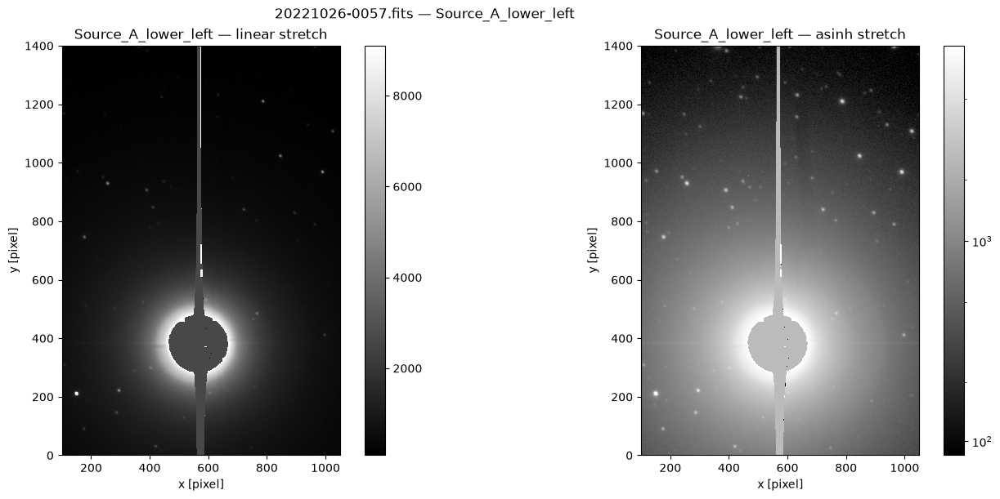

Saved: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/Source_A_lower_left_native_cutout.png


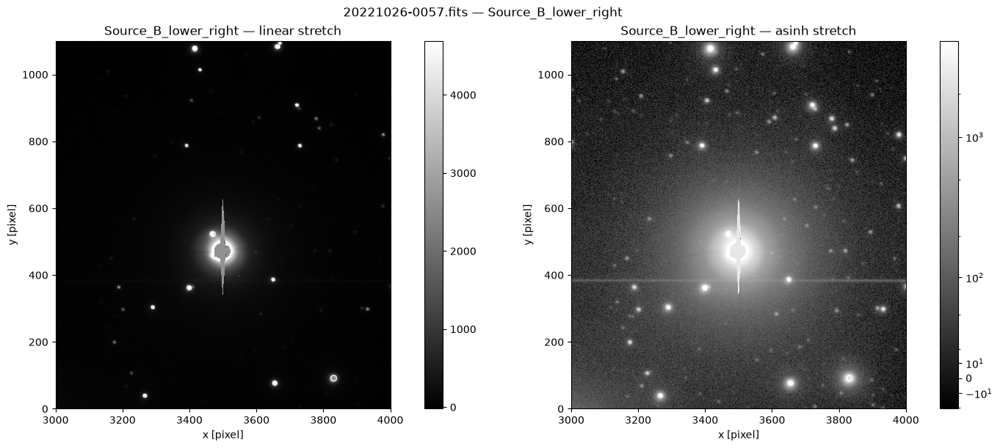

Saved: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/Source_B_lower_right_native_cutout.png
Memory: {'process_rss_gib': 0.533, 'available_ram_gib': 6.129}


In [12]:
# ============================================================
# CELL 10 — BRIGHT-SOURCE NATIVE-RESOLUTION CUTOUTS
# ============================================================

BRIGHT_SOURCE_REGIONS = {

    "Source_A_lower_left": {
        "x0": 100,
        "x1": 1050,
        "y0": 0,
        "y1": 1400
    },

    "Source_B_lower_right": {
        "x0": 3000,
        "x1": 4000,
        "y0": 0,
        "y1": 1100
    }
}


def plot_source_cutout(name, bounds):

    x0 = bounds["x0"]
    x1 = bounds["x1"]

    y0 = bounds["y0"]
    y1 = bounds["y1"]

    crop = image_raw[y0:y1, x0:x1]

    p_low = float(
        np.percentile(crop, 1)
    )

    p_high = float(
        np.percentile(crop, 99.8)
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 6),
        constrained_layout=True
    )

    # Linear view.
    im0 = axes[0].imshow(
        crop,
        origin="lower",
        cmap="gray",
        vmin=p_low,
        vmax=p_high,
        extent=(x0, x1, y0, y1),
        interpolation="nearest"
    )

    axes[0].set_title(
        f"{name} — linear stretch"
    )

    axes[0].set_xlabel("x [pixel]")
    axes[0].set_ylabel("y [pixel]")

    fig.colorbar(im0, ax=axes[0])


    # Asinh view.
    norm = AsinhNorm(
        linear_width=max(raw_robust_sigma, 1.0),
        vmin=p_low,
        vmax=max(p_high, p_low + 1.0)
    )

    im1 = axes[1].imshow(
        crop,
        origin="lower",
        cmap="gray",
        norm=norm,
        extent=(x0, x1, y0, y1),
        interpolation="nearest"
    )

    axes[1].set_title(
        f"{name} — asinh stretch"
    )

    axes[1].set_xlabel("x [pixel]")
    axes[1].set_ylabel("y [pixel]")

    fig.colorbar(im1, ax=axes[1])


    fig.suptitle(
        f"{FRAME_FILENAME} — {name}"
    )

    output_path = (
        FRAME_OUTPUT_DIR /
        f"{name}_native_cutout.png"
    )

    fig.savefig(
        output_path,
        dpi=140,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)


for name, bounds in BRIGHT_SOURCE_REGIONS.items():

    plot_source_cutout(
        name,
        bounds
    )

print("Memory:", memory_report())

These results are much more informative than the original column profiles. They show that the repeated value is not simply a collection of defective pixels, and that the two bright sources have substantial surrounding structures.

**Finding A — It is a spatially structured replacement or plateau-like feature**
The exact value is:

$$
V_{\mathrm{repeat}}=2650.081298828125
$$

It occurs in 72,427 pixels, or 0.432% of the frame.

The connected-component analysis is especially useful:

| Component | Area | Bounding box | Interpretation |
|---|---:|---|---|
| 1 | 66,656 px | x=464–668, y=0–2926 | Large, connected structure associated with source A |
| 3 | 3,808 px | x=3474–3521, y=345–626 | Local structure associated with source B |
| 5 | 639 px | x=1731–1755, y=555–601 | Small isolated structure |
| Remaining components | Smaller | Distributed across the frame | Need inspection, but lower immediate priority |

The most important observation is that the largest component is roughly 2,927 pixels long in the vertical direction. It is not just the saturated-looking core of source A.

**Finding B — The equality mask is associated with more than one bright source**

The second component around source B is important. A similar repeated-value pattern around two distinct bright sources makes a purely isolated column defect less likely.

It suggests that the phenomenon may be associated with bright-source regions or a common image-processing operation.

However, we cannot yet distinguish a source-related detector effect from a replacement operation applied during earlier processing.

Decision: classify these pixels as REPEATED_VALUE_SUSPICIOUS, not BAD_PIXEL or SATURATION, until we establish their origin.

---

**What the two bright-source cutouts reveal**

**Source A — lower left**

This is the more problematic source.

The native-resolution view shows:
- A very bright, approximately circular core.
- An extended halo.
- A prominent vertical structure passing through the source.
- Additional bright, narrow structures offset from the central vertical feature.
- A much broader region affected by the repeated-value plateau.

This is not a simple isolated Gaussian-looking star.

A circular mask around its core would leave much of the contamination behind. Conversely, masking the entire halo would discard a large portion of useful image area.

We need to identify the core, halo and linear structures separately.

**Source B — lower right**

This source is more compact, but it also has:
- A bright central core.
- A visible surrounding halo.
- A narrow vertical feature passing through the source.
- A possible horizontal background feature near the same detector row as source A.

The similar vertical orientation around two separate bright sources deserves attention.

It could be associated with the instrument, detector readout, source morphology or image processing. We need more evidence before calling it charge bleeding.

---

There is another feature we should not overlook: the unusually elevated rows around \(y=380\)–390.

The median of row 384 is approximately 189, whereas the overall image median is approximately 2.

That could be a horizontal detector-related band, but it could also be caused by the broad halo around source A. We need to distinguish a row-wide offset from a localised structure.

Similarly, the repeated-value pattern around \(x=570\) should be compared against nearby columns.

### Test whether the horizontal and vertical structures are local or detector-wide


HORIZONTAL BAND DIFFERENCE
--------------------------
{'median': 46.87981414794922, 'robust_sigma': 15.281835948419301, 'p10': 21.066001892089844, 'p90': 86.6312255859375, 'minimum': -6526.732421875, 'maximum': 8641.0087890625}

VERTICAL BAND DIFFERENCE
------------------------
{'median': 1742.8014526367188, 'robust_sigma': 1345.6250302692695, 'p10': -0.4476470947265625, 'p90': 2643.7362060546875, 'minimum': -6374.0341796875, 'maximum': 2668.760498046875}

Horizontal intervals beyond 3 robust sigma (threshold=45.846)
(326, 774)
(3454, 3537)
(2435, 2478)
(3381, 3418)
(3631, 3667)
(301, 307)
(319, 324)
(309, 313)
(776, 779)
(3445, 3448)
(275, 277)
(280, 282)
(294, 296)
(315, 317)
(3450, 3452)

Vertical intervals beyond 3 robust sigma (threshold=4036.875)
(242, 287)
(475, 517)


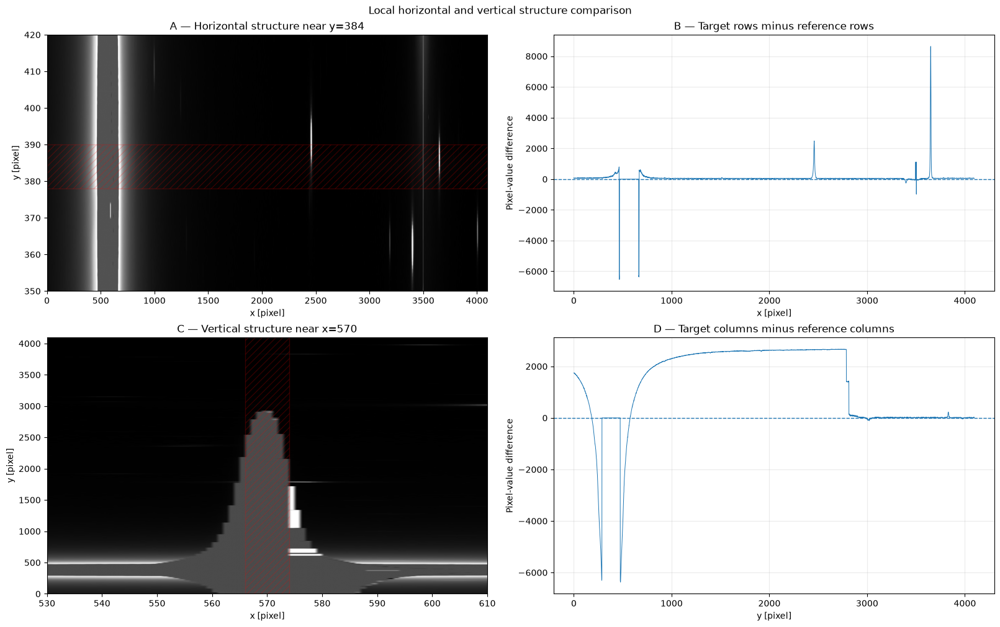


Saved: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/horizontal_vertical_structure_comparison.png
Memory: {'process_rss_gib': 0.531, 'available_ram_gib': 6.189}


In [13]:
# ============================================================
# CELL 11 — HORIZONTAL AND VERTICAL STRUCTURE INVESTIGATION
# ============================================================

# ------------------------------------------------------------
# 1. Compare suspicious horizontal band with reference rows
# ------------------------------------------------------------

TARGET_ROWS = (378, 390)

REFERENCE_ROW_BANDS = [
    (350, 370),
    (400, 420)
]

target_row_band = np.median(
    image_raw[
        TARGET_ROWS[0]:TARGET_ROWS[1],
        :
    ],
    axis=0
)

reference_rows = np.concatenate(
    [
        image_raw[a:b, :]
        for a, b in REFERENCE_ROW_BANDS
    ],
    axis=0
)

reference_row_profile = np.median(
    reference_rows,
    axis=0
)

horizontal_delta = (
    target_row_band - reference_row_profile
)


# ------------------------------------------------------------
# 2. Compare suspicious vertical structure with side columns
# ------------------------------------------------------------

TARGET_COLUMNS = (566, 574)

REFERENCE_COLUMN_BANDS = [
    (530, 545),
    (595, 610)
]

target_column_band = np.median(
    image_raw[
        :,
        TARGET_COLUMNS[0]:TARGET_COLUMNS[1]
    ],
    axis=1
)

reference_columns = np.concatenate(
    [
        image_raw[:, a:b]
        for a, b in REFERENCE_COLUMN_BANDS
    ],
    axis=1
)

reference_column_profile = np.median(
    reference_columns,
    axis=1
)

vertical_delta = (
    target_column_band - reference_column_profile
)


# ------------------------------------------------------------
# 3. Robust diagnostic statistics
# ------------------------------------------------------------

def robust_summary(values):

    values = np.asarray(
        values,
        dtype=np.float64
    )

    med = np.median(values)

    sigma = 1.4826022185 * np.median(
        np.abs(values - med)
    )

    return {
        "median": float(med),
        "robust_sigma": float(sigma),
        "p10": float(np.percentile(values, 10)),
        "p90": float(np.percentile(values, 90)),
        "minimum": float(np.min(values)),
        "maximum": float(np.max(values))
    }


print("HORIZONTAL BAND DIFFERENCE")
print("--------------------------")

print(
    robust_summary(horizontal_delta)
)

print("\nVERTICAL BAND DIFFERENCE")
print("------------------------")

print(
    robust_summary(vertical_delta)
)


# ------------------------------------------------------------
# 4. Identify contiguous intervals of large deviations
# ------------------------------------------------------------

def find_intervals(condition):

    condition = np.asarray(
        condition,
        dtype=bool
    )

    edges = np.diff(
        np.r_[False, condition, False].astype(np.int8)
    )

    starts = np.where(edges == 1)[0]
    stops = np.where(edges == -1)[0]

    return [
        (int(a), int(b - 1))
        for a, b in zip(starts, stops)
    ]


def report_large_intervals(values, axis_name):

    med = np.median(values)

    sigma = 1.4826022185 * np.median(
        np.abs(values - med)
    )

    threshold = max(
        3.0 * sigma,
        1e-6
    )

    condition = (
        np.abs(values - med) > threshold
    )

    intervals = find_intervals(condition)

    intervals = sorted(
        intervals,
        key=lambda x: x[1] - x[0],
        reverse=True
    )

    print(
        f"\n{axis_name} intervals beyond "
        f"3 robust sigma (threshold={threshold:.3f})"
    )

    for interval in intervals[:15]:
        print(interval)


report_large_intervals(
    horizontal_delta,
    "Horizontal"
)

report_large_intervals(
    vertical_delta,
    "Vertical"
)


# ------------------------------------------------------------
# 5. Visual comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
    constrained_layout=True
)

# A. Horizontal target/reference region.
row_image = image_raw[
    350:420,
    :
]

row_low, row_high = np.percentile(
    row_image,
    [1, 99.5]
)

axes[0, 0].imshow(
    row_image,
    origin="lower",
    aspect="auto",
    cmap="gray",
    vmin=row_low,
    vmax=row_high,
    extent=(0, image_raw.shape[1], 350, 420)
)

axes[0, 0].axhspan(
    TARGET_ROWS[0],
    TARGET_ROWS[1],
    alpha=0.2,
    hatch="///",
    edgecolor="red",
    facecolor="none"
)

axes[0, 0].set_title(
    "A — Horizontal structure near y=384"
)

axes[0, 0].set_xlabel("x [pixel]")
axes[0, 0].set_ylabel("y [pixel]")


# B. Horizontal difference profile.
axes[0, 1].plot(
    np.arange(image_raw.shape[1]),
    horizontal_delta,
    linewidth=0.7
)

axes[0, 1].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[0, 1].set_title(
    "B — Target rows minus reference rows"
)

axes[0, 1].set_xlabel("x [pixel]")
axes[0, 1].set_ylabel("Pixel-value difference")
axes[0, 1].grid(alpha=0.25)


# C. Vertical target region.
column_image = image_raw[
    :,
    530:610
]

col_low, col_high = np.percentile(
    column_image,
    [1, 99.5]
)

axes[1, 0].imshow(
    column_image,
    origin="lower",
    aspect="auto",
    cmap="gray",
    vmin=col_low,
    vmax=col_high,
    extent=(530, 610, 0, image_raw.shape[0])
)

axes[1, 0].axvspan(
    TARGET_COLUMNS[0],
    TARGET_COLUMNS[1],
    alpha=0.2,
    hatch="///",
    edgecolor="red",
    facecolor="none"
)

axes[1, 0].set_title(
    "C — Vertical structure near x=570"
)

axes[1, 0].set_xlabel("x [pixel]")
axes[1, 0].set_ylabel("y [pixel]")


# D. Vertical difference profile.
axes[1, 1].plot(
    np.arange(image_raw.shape[0]),
    vertical_delta,
    linewidth=0.7
)

axes[1, 1].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[1, 1].set_title(
    "D — Target columns minus reference columns"
)

axes[1, 1].set_xlabel("y [pixel]")
axes[1, 1].set_ylabel("Pixel-value difference")
axes[1, 1].grid(alpha=0.25)


fig.suptitle(
    "Local horizontal and vertical structure comparison"
)

STRUCTURE_FIGURE_PATH = (
    FRAME_OUTPUT_DIR /
    "horizontal_vertical_structure_comparison.png"
)

fig.savefig(
    STRUCTURE_FIGURE_PATH,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved:", STRUCTURE_FIGURE_PATH)
print("Memory:", memory_report())

**The apparent row and column defects are localised structures**

Horizontal structure near \(y=384\)
The difference is not uniform across the detector.

The strongest intervals are:
- \(x=326\)–774: source A and its surrounding structure.
- \(x=3454\)–3537: source B.
- Smaller peaks around other bright sources.

The target rows also pass directly through the lower-left source's bright region. The reference rows at 350–370 and 400–420 are not clean background controls either; they are still affected by the source halo.

Therefore, the median difference of 46.88 cannot be interpreted as a detector-wide row offset.

Decision: no global row correction or row masking yet.
Vertical structure near \(x=570\)
The target columns are dominated by the repeated value across a large part of their height. The reference columns are outside that structure.

That explains the large difference:
$$ \operatorname{median}(\Delta_{\mathrm{vertical}})
\approx 1743$$
The result is evidence of a strong localised structure, not evidence that the CCD has a uniform additive offset across columns 566–573.

**What about the bright-source vertical features?**

Both bright-source cutouts show structures that extend approximately vertically from the sources. Their morphology is consistent with a source-associated instrumental feature, potentially charge bleeding, but we have not established its physical origin.

We will retain separate categories for:
- Bright source core.
- Extended source halo.
- Repeated-value region.
- Narrow vertical structure.
One mask should not silently combine all four.

**Parse, validate and overlay the DS9 annotation**

This cell has four jobs:
1. Verify the DS9 file actually declares IMAGE coordinates.
2. Convert its two edge lines from DS9's 1-based coordinates to NumPy's 0-based coordinates.
3. Calculate the centreline, width, length and visible endpoints.
4. Measure how much of the annotated corridor intersects the repeated-value region.

It will also compare the centreline with four parallel control corridors, offset by ±40 and ±80 pixels. These controls help us distinguish a signal genuinely concentrated along the annotation from a broader local background pattern.

DS9 ANNOTATION VALIDATION
-------------------------
Coordinate mode: image
DS9-to-array conversion: subtract 1

Edge lengths [px]: [4552.850199050125, 4552.849330654971]
Width at first endpoint: 8.595276438636288
Width at second endpoint: 8.594356462819047
Mean edge separation: 8.594816450727667

Centreline endpoints [0-based]
Start: [  10.191868 3167.8256  ]
End: [4095.87585 1158.9385 ]
Centreline length: 4552.849764852535
Visible length: 4551.873768303582
Angle: 153.81714810568533
Width variation [%]: 0.010703844840850595
Endpoint outside image: False

WCS ROUND-TRIP CHECK
--------------------
Maximum round-trip error [px]: 2.2522996446595423e-08
Round-trip passed: True
WCS warnings: ["'datfix' made the change 'Set MJD-OBS to 59878.000000 from DATE-OBS'."]

TARGET AND CONTROL CORRIDORS
-----------------------------

 CONTROL OFFSET -80 px
valid_fraction                    : 0.9938515590689504
median_contrast                   : -0.6292530298233032
p10_contrast                      : 

/tmp/ipykernel_346302/3105725721.py:441: RuntimeWarning: All-NaN slice encountered
  core_median = np.nanmedian(
/tmp/ipykernel_346302/3105725721.py:446: RuntimeWarning: All-NaN slice encountered
  side_median = np.nanmedian(


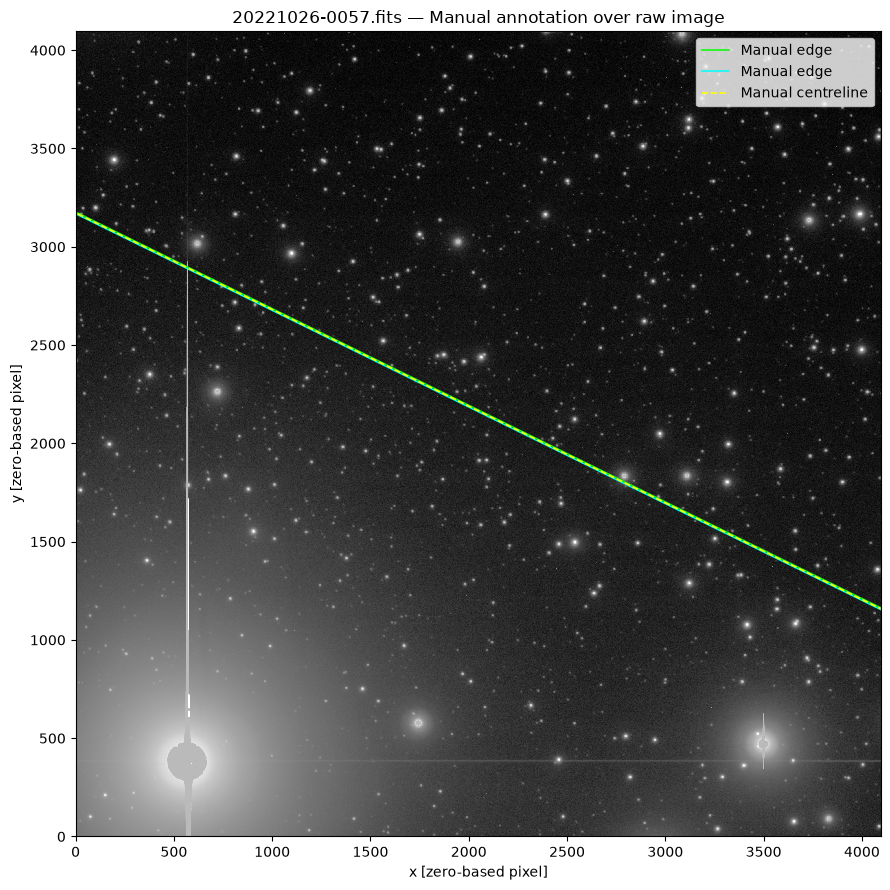

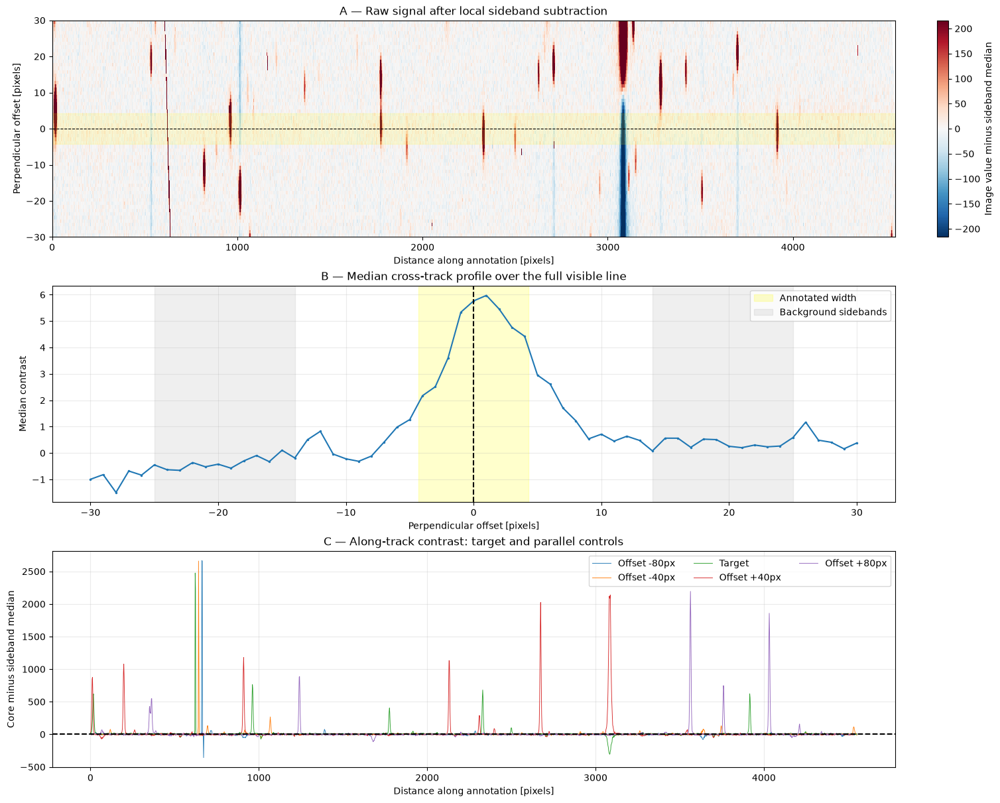


STAGE 4 OUTPUTS
---------------
Raw overlay: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/manual_annotation_raw_overlay.png
Straightened corridor: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/annotated_corridor_straightened_analysis.png
Diagnostics: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/annotation_corridor_diagnostics.json

Memory: {'process_rss_gib': 0.599, 'available_ram_gib': 6.106}


In [14]:
# ============================================================
# CELL 12 — ANNOTATION GEOMETRY AND TRAIL-CORRIDOR VALIDATION
# ============================================================

import re
import warnings
import numpy as np
import matplotlib.pyplot as plt

from scipy import ndimage as ndi
from astropy.wcs import WCS
from matplotlib.colors import AsinhNorm


# ------------------------------------------------------------
# 1. Read and validate DS9 coordinate convention
# ------------------------------------------------------------

region_text = EDGE_REGION_PATH.read_text(
    encoding="utf-8",
    errors="replace"
)

coordinate_modes = re.findall(
    r"(?im)^\s*(image|physical|fk5|icrs|j2000|galactic)\s*$",
    region_text
)

if not coordinate_modes:
    raise ValueError(
        "No explicit DS9 coordinate declaration was found. "
        "Do not assume the annotation coordinate system."
    )

if coordinate_modes[-1].lower() != "image":
    raise ValueError(
        "Expected DS9 IMAGE coordinates, but found: "
        f"{coordinate_modes[-1]!r}. "
        "Re-save the region in DS9 using Coordinate > Image."
    )


# Extract only actual line regions, not commented examples.
number = (
    r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)"
    r"(?:[eE][-+]?\d+)?"
)

line_pattern = re.compile(
    rf"(?im)^\s*line\s*\(\s*"
    rf"({number})\s*,\s*"
    rf"({number})\s*,\s*"
    rf"({number})\s*,\s*"
    rf"({number})\s*\)"
)

line_matches = list(
    line_pattern.finditer(region_text)
)

if len(line_matches) != 2:
    raise ValueError(
        f"Expected exactly two DS9 edge lines; "
        f"found {len(line_matches)}."
    )

# DS9 IMAGE coordinates are 1-based.
# NumPy array coordinates are 0-based.
edges_ds9 = np.array(
    [
        [float(v) for v in match.groups()]
        for match in line_matches
    ],
    dtype=np.float64
).reshape(2, 2, 2)

edges_xy = edges_ds9 - 1.0


# ------------------------------------------------------------
# 2. Match the endpoint ordering of the two edges
# ------------------------------------------------------------

edge_a = edges_xy[0].copy()
edge_b = edges_xy[1].copy()

direct_cost = (
    np.linalg.norm(edge_a[0] - edge_b[0])
    + np.linalg.norm(edge_a[1] - edge_b[1])
)

reverse_cost = (
    np.linalg.norm(edge_a[0] - edge_b[1])
    + np.linalg.norm(edge_a[1] - edge_b[0])
)

if reverse_cost < direct_cost:

    edge_b = edge_b[::-1].copy()

# The two edges should now have corresponding endpoints.
center_start = 0.5 * (edge_a[0] + edge_b[0])
center_end = 0.5 * (edge_a[1] + edge_b[1])

width_start = float(
    np.linalg.norm(edge_a[0] - edge_b[0])
)

width_end = float(
    np.linalg.norm(edge_a[1] - edge_b[1])
)

annotation_width = 0.5 * (
    width_start + width_end
)

edge_lengths = [
    float(np.linalg.norm(edge[1] - edge[0]))
    for edge in (edge_a, edge_b)
]

centerline_vector = center_end - center_start

annotation_length = float(
    np.linalg.norm(centerline_vector)
)

if annotation_length <= 0:
    raise ValueError("Invalid zero-length annotation.")

direction = (
    centerline_vector / annotation_length
)

normal = np.array(
    [-direction[1], direction[0]]
)

annotation_angle = float(
    np.degrees(
        np.arctan2(
            direction[1],
            direction[0]
        )
    ) % 180.0
)


# ------------------------------------------------------------
# 3. Clip the centreline to the actual image boundary
# ------------------------------------------------------------

def clip_segment_to_image(p0, p1, shape):
    """
    Liang-Barsky line clipping.

    Returns the visible segment inside the image, or None.
    Pixel-centre bounds are [0, width-1] and [0, height-1].
    """

    h, w = shape

    x0, y0 = map(float, p0)
    x1, y1 = map(float, p1)

    dx = x1 - x0
    dy = y1 - y0

    t0 = 0.0
    t1 = 1.0

    tests = [
        (-dx, x0),
        ( dx, (w - 1) - x0),
        (-dy, y0),
        ( dy, (h - 1) - y0)
    ]

    for p, q in tests:

        if abs(p) < 1e-12:

            if q < 0:
                return None

            continue

        r = q / p

        if p < 0:
            t0 = max(t0, r)

        else:
            t1 = min(t1, r)

        if t0 > t1:
            return None

    visible_p0 = np.array(
        [x0 + t0 * dx, y0 + t0 * dy]
    )

    visible_p1 = np.array(
        [x0 + t1 * dx, y0 + t1 * dy]
    )

    return visible_p0, visible_p1


visible_segment = clip_segment_to_image(
    center_start,
    center_end,
    image_raw.shape
)

if visible_segment is None:
    raise RuntimeError(
        "The annotated centreline does not intersect the image."
    )

visible_start, visible_end = visible_segment

visible_length = float(
    np.linalg.norm(visible_end - visible_start)
)


# ------------------------------------------------------------
# 4. Geometry report
# ------------------------------------------------------------

print("DS9 ANNOTATION VALIDATION")
print("-------------------------")

print("Coordinate mode:", coordinate_modes[-1])
print("DS9-to-array conversion: subtract 1")

print("\nEdge lengths [px]:", edge_lengths)

print("Width at first endpoint:", width_start)
print("Width at second endpoint:", width_end)
print("Mean edge separation:", annotation_width)

print("\nCentreline endpoints [0-based]")

print("Start:", center_start)
print("End:", center_end)

print("Centreline length:", annotation_length)
print("Visible length:", visible_length)
print("Angle:", annotation_angle)

print(
    "Width variation [%]:",
    100.0 * abs(width_start - width_end)
    / max(annotation_width, 1e-12)
)

print(
    "Endpoint outside image:",
    not (
        np.all(center_start >= 0)
        and center_start[0] < image_raw.shape[1]
        and center_start[1] < image_raw.shape[0]
        and np.all(center_end >= 0)
        and center_end[0] < image_raw.shape[1]
        and center_end[1] < image_raw.shape[0]
    )
)


# ------------------------------------------------------------
# 5. Optional WCS round-trip check
# ------------------------------------------------------------

print("\nWCS ROUND-TRIP CHECK")
print("--------------------")

try:

    with warnings.catch_warnings(record=True) as wcs_warnings:

        warnings.simplefilter("always")

        celestial_wcs = WCS(
            raw_header,
            relax=True
        ).celestial

        test_points = np.array([
            center_start,
            center_end,
            0.5 * (center_start + center_end)
        ])

        world = celestial_wcs.pixel_to_world_values(
            test_points[:, 0],
            test_points[:, 1]
        )

        x_back, y_back = (
            celestial_wcs.world_to_pixel_values(*world)
        )

        roundtrip_error = np.hypot(
            x_back - test_points[:, 0],
            y_back - test_points[:, 1]
        )

        print(
            "Maximum round-trip error [px]:",
            float(np.max(roundtrip_error))
        )

        print(
            "Round-trip passed:",
            bool(np.max(roundtrip_error) < 1e-3)
        )

        if wcs_warnings:

            print(
                "WCS warnings:",
                [str(w.message) for w in wcs_warnings]
            )

except Exception as exc:

    print("WCS check unavailable:", repr(exc))


# ------------------------------------------------------------
# 6. Prepare the repeated-value mask
# ------------------------------------------------------------

# Preserve the exact equality test from the previous stage.
repeat_mask_for_validation = (
    image_raw == np.float32(SUSPECT_CONSTANT_VALUE)
)


# ------------------------------------------------------------
# 7. Straighten the annotated corridor
# ------------------------------------------------------------

# Use visible endpoints so all samples correspond to the image.
dx = visible_end[0] - visible_start[0]
dy = visible_end[1] - visible_start[1]

L = float(np.hypot(dx, dy))

direction = np.array(
    [dx, dy],
    dtype=np.float64
) / L

normal = np.array(
    [-direction[1], direction[0]]
)

# Two-pixel along-track sampling.
along_step = 2.0

s = np.arange(
    0.0,
    L + 0.5 * along_step,
    along_step
)

s = np.minimum(s, L)

# Cross-track sampling.
u = np.arange(
    -30.0,
    30.01,
    1.0
)

core_mask_1d = (
    np.abs(u) <= annotation_width / 2
)

sideband_mask_1d = (
    (np.abs(u) >= 14.0)
    & (np.abs(u) <= 25.0)
)

if core_mask_1d.sum() < 3:
    raise RuntimeError("Annotation aperture is unexpectedly narrow.")

if sideband_mask_1d.sum() < 10:
    raise RuntimeError("Insufficient sideband samples.")


# ------------------------------------------------------------
# 8. Sample a track and estimate its local sideband level
# ------------------------------------------------------------

def sample_track(offset_px):

    # Offset shifts the centre of the test/control line
    # in the perpendicular direction.
    u_shifted = u + float(offset_px)

    X = (
        visible_start[0]
        + s[:, None] * direction[0]
        + u_shifted[None, :] * normal[0]
    )

    Y = (
        visible_start[1]
        + s[:, None] * direction[1]
        + u_shifted[None, :] * normal[1]
    )

    coordinates = [
        Y.ravel(),
        X.ravel()
    ]

    samples = ndi.map_coordinates(
        image_raw,
        coordinates,
        order=1,
        mode="constant",
        cval=np.nan
    ).reshape(X.shape)

    repeated = ndi.map_coordinates(
        repeat_mask_for_validation.astype(np.uint8),
        coordinates,
        order=0,
        mode="constant",
        cval=0
    ).reshape(X.shape).astype(bool)

    core_values = samples[:, core_mask_1d]
    side_values = samples[:, sideband_mask_1d]

    core_median = np.nanmedian(
        core_values,
        axis=1
    )

    side_median = np.nanmedian(
        side_values,
        axis=1
    )

    contrast = (
        core_median - side_median
    )

    # Subtract the sideband level from every cross-track sample.
    corrected_strip = (
        samples - side_median[:, None]
    )

    return {
        "samples": samples,
        "repeated": repeated,
        "corrected_strip": corrected_strip,
        "contrast": contrast,
        "core_median": core_median,
        "side_median": side_median,
        "X": X,
        "Y": Y
    }


# Target plus parallel controls.
CONTROL_OFFSETS = [
    -80.0,
    -40.0,
    0.0,
    40.0,
    80.0
]

track_results = {}

for offset in CONTROL_OFFSETS:

    track_results[offset] = sample_track(
        offset
    )


# ------------------------------------------------------------
# 9. Quantify target/control contrast and mask overlap
# ------------------------------------------------------------

def track_summary(result):

    contrast = result["contrast"]

    valid = np.isfinite(contrast)

    if not valid.any():

        return {
            "valid_fraction": 0.0,
            "median_contrast": np.nan,
            "p10_contrast": np.nan,
            "p90_contrast": np.nan,
            "positive_fraction": np.nan,
            "repeated_core_fraction": np.nan,
            "along_track_repeated_fraction": np.nan
        }

    repeated = result["repeated"]

    repeated_core = repeated[:, core_mask_1d]

    # Fraction of pixels in the central annotated-width
    # corridor that equal the suspicious repeated value.
    repeated_core_fraction = float(
        repeated_core.mean()
    )

    # Fraction of along-track positions with at least
    # one repeated-value pixel in the central corridor.
    repeated_positions_fraction = float(
        repeated_core.any(axis=1).mean()
    )

    values = contrast[valid]

    return {

        "valid_fraction": float(valid.mean()),

        "median_contrast": float(np.median(values)),

        "p10_contrast": float(np.percentile(values, 10)),

        "p90_contrast": float(np.percentile(values, 90)),

        "positive_fraction": float(
            np.mean(values > 0)
        ),

        "repeated_core_fraction": repeated_core_fraction,

        "along_track_repeated_fraction": repeated_positions_fraction
    }


print("\nTARGET AND CONTROL CORRIDORS")
print("-----------------------------")

track_summaries = {}

for offset in CONTROL_OFFSETS:

    summary = track_summary(
        track_results[offset]
    )

    track_summaries[offset] = summary

    label = (
        "ANNOTATED TARGET"
        if offset == 0
        else f"CONTROL OFFSET {offset:+.0f} px"
    )

    print("\n", label)

    for key, value in summary.items():

        print(f"{key:34s}: {value}")


# ------------------------------------------------------------
# 10. Along-track block statistics for the annotated target
# ------------------------------------------------------------

target_contrast = track_results[0.0]["contrast"]

BLOCK_LENGTH = 256.0

block_edges = np.arange(
    0,
    L + BLOCK_LENGTH,
    BLOCK_LENGTH
)

print("\nANNOTATED-CORRIDOR BLOCK STATISTICS")
print("-----------------------------------")

block_records = []

for left, right in zip(
    block_edges[:-1],
    block_edges[1:]
):

    select = (
        (s >= left)
        & (s < right)
        & np.isfinite(target_contrast)
    )

    if select.sum() == 0:
        continue

    block_values = target_contrast[select]

    record = {
        "s_start": float(left),
        "s_end": float(min(right, L)),
        "median_contrast": float(
            np.median(block_values)
        ),
        "positive_fraction": float(
            np.mean(block_values > 0)
        )
    }

    block_records.append(record)

    print(record)


# ------------------------------------------------------------
# 11. Full-frame raw image with the annotation
# ------------------------------------------------------------

# Use the existing display-only image from Cell 6.
if "display_image" not in globals():

    raise RuntimeError(
        "Run Cell 6 first to create display_image."
    )

display_norm = AsinhNorm(
    linear_width=max(raw_robust_sigma, 1.0),
    vmin=float(np.percentile(display_image, 0.1)),
    vmax=float(np.percentile(display_image, 99.99))
)

fig, ax = plt.subplots(
    figsize=(10, 9)
)

ax.imshow(
    display_image,
    origin="lower",
    extent=(0, image_raw.shape[1], 0, image_raw.shape[0]),
    cmap="gray",
    norm=display_norm,
    interpolation="nearest"
)

# Manual edges.
for edge, colour in (
    (edge_a, "lime"),
    (edge_b, "cyan")
):

    ax.plot(
        edge[:, 0],
        edge[:, 1],
        color=colour,
        linewidth=1.1,
        label="Manual edge"
    )

# Manual centreline.
ax.plot(
    [visible_start[0], visible_end[0]],
    [visible_start[1], visible_end[1]],
    color="yellow",
    linestyle="--",
    linewidth=1.2,
    label="Manual centreline"
)

ax.set_xlim(0, image_raw.shape[1])
ax.set_ylim(0, image_raw.shape[0])

ax.set_xlabel("x [zero-based pixel]")
ax.set_ylabel("y [zero-based pixel]")

ax.set_title(
    f"{FRAME_FILENAME} — Manual annotation over raw image"
)

ax.legend(loc="best")

fig.tight_layout()

ANNOTATION_OVERLAY_PATH = (
    FRAME_OUTPUT_DIR /
    "manual_annotation_raw_overlay.png"
)

fig.savefig(
    ANNOTATION_OVERLAY_PATH,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 12. Straightened target corridor and cross-track profile
# ------------------------------------------------------------

target = track_results[0.0]

strip = target["corrected_strip"]

finite_strip = strip[np.isfinite(strip)]

if finite_strip.size == 0:
    raise RuntimeError("No finite samples in the target strip.")

clip = float(
    np.percentile(
        np.abs(finite_strip),
        99
    )
)

clip = max(clip, 1e-6)

median_cross_profile = np.nanmedian(
    strip,
    axis=0
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 12),
    constrained_layout=True
)

# A. Straightened image.
im = axes[0].imshow(
    strip.T,
    origin="lower",
    aspect="auto",
    extent=(0, L, u[0], u[-1]),
    cmap="RdBu_r",
    vmin=-clip,
    vmax=clip,
    interpolation="nearest"
)

axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=0.8
)

axes[0].axhspan(
    -annotation_width / 2,
    annotation_width / 2,
    color="yellow",
    alpha=0.13
)

axes[0].set_title(
    "A — Raw signal after local sideband subtraction"
)

axes[0].set_xlabel("Distance along annotation [pixels]")
axes[0].set_ylabel("Perpendicular offset [pixels]")

fig.colorbar(im, ax=axes[0], label="Image value minus sideband median")


# B. Median cross-track profile.
axes[1].plot(
    u,
    median_cross_profile,
    marker=".",
    markersize=3
)

axes[1].axvline(0, color="black", linestyle="--")

axes[1].axvspan(
    -annotation_width / 2,
    annotation_width / 2,
    color="yellow",
    alpha=0.2,
    label="Annotated width"
)

axes[1].axvspan(
    -25,
    -14,
    color="grey",
    alpha=0.12,
    label="Background sidebands"
)

axes[1].axvspan(
    14,
    25,
    color="grey",
    alpha=0.12
)

axes[1].set_title(
    "B — Median cross-track profile over the full visible line"
)

axes[1].set_xlabel("Perpendicular offset [pixels]")
axes[1].set_ylabel("Median contrast")
axes[1].legend()
axes[1].grid(alpha=0.25)


# C. Target versus parallel control corridors.
for offset in CONTROL_OFFSETS:

    axes[2].plot(
        s,
        track_results[offset]["contrast"],
        linewidth=0.65,
        label=(
            "Target"
            if offset == 0
            else f"Offset {offset:+.0f}px"
        )
    )

axes[2].axhline(
    0,
    color="black",
    linestyle="--"
)

axes[2].set_title(
    "C — Along-track contrast: target and parallel controls"
)

axes[2].set_xlabel("Distance along annotation [pixels]")
axes[2].set_ylabel("Core minus sideband median")
axes[2].legend(ncol=3)
axes[2].grid(alpha=0.25)


CORRIDOR_FIGURE_PATH = (
    FRAME_OUTPUT_DIR /
    "annotated_corridor_straightened_analysis.png"
)

fig.savefig(
    CORRIDOR_FIGURE_PATH,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 13. Save geometry and corridor diagnostics
# ------------------------------------------------------------

ANNOTATION_DIAGNOSTICS = {

    "frame": FRAME_FILENAME,

    "fits_sha256": FITS_SHA256,

    "coordinate_system": "DS9 IMAGE, converted to 0-based array pixels",

    "edge_lengths_px": edge_lengths,

    "width_start_px": width_start,

    "width_end_px": width_end,

    "mean_width_px": annotation_width,

    "centerline_start_px": center_start.tolist(),

    "centerline_end_px": center_end.tolist(),

    "visible_start_px": visible_start.tolist(),

    "visible_end_px": visible_end.tolist(),

    "annotation_length_px": annotation_length,

    "visible_length_px": visible_length,

    "angle_deg": annotation_angle,

    "control_offsets_px": CONTROL_OFFSETS,

    "track_summaries": {
        str(offset): summary
        for offset, summary in track_summaries.items()
    },

    "block_records": block_records
}

ANNOTATION_DIAGNOSTICS_PATH = (
    FRAME_OUTPUT_DIR /
    "annotation_corridor_diagnostics.json"
)

ANNOTATION_DIAGNOSTICS_PATH.write_text(
    json.dumps(
        ANNOTATION_DIAGNOSTICS,
        indent=2
    ),
    encoding="utf-8"
)

print("\nSTAGE 4 OUTPUTS")
print("---------------")

print("Raw overlay:", ANNOTATION_OVERLAY_PATH)
print("Straightened corridor:", CORRIDOR_FIGURE_PATH)
print("Diagnostics:", ANNOTATION_DIAGNOSTICS_PATH)

print("\nMemory:", memory_report())

Unlike the earlier FRT output, which consisted of short detections near bright sources, the manual corridor now shows a positive, spatially concentrated signal relative to parallel control corridors. 

**The strongest evidence: target versus parallel controls**

Our corridor measurements include:


| Corridor | Median contrast | Positive fraction |
|---|---:|---:|
| −80 px | −0.629 | 46.7% |
| −40 px | −0.140 | 49.0% |
| **Target** | **4.411** | **73.0%** |
| +40 px | −0.398 | 48.0% |
| +80 px | −0.546 | 46.4% |

The target median is substantially more positive than the four parallel controls.

This is a stronger observation than simply saying that the annotated pixels are brighter than the image median. It suggests that the excess is spatially concentrated around the manually annotated line.

### Quantify whether the annotated ridge is genuinely distinct

We will compare the target and control corridors block by block at the same along-track positions. This is stronger than comparing only their overall medians because it shows whether the target's excess persists throughout the frame.

We will also estimate the cross-track profile's approximate width without fitting a Gaussian yet.

This cell:
- Fixes the all-NaN warnings from Cell 12.
- Resamples the same five corridors.
- Uses common valid positions for fair comparisons.
- Compares the target against the median of its four controls in 256-pixel blocks.
- Calculates a descriptive bootstrap interval for the target-control difference.
- Estimates the non-parametric FWHM of the median cross-track profile.

PAIRED TARGET/CONTROL COMPARISON
--------------------------------
Total along-track samples: 2277
Common valid samples: 2244
Common valid fraction: 0.9855072463768116
Median target contrast: 4.372288823127747
Median control reference: -0.4207260012626648
Median paired difference: 4.691482305526733
Fraction of paired samples where target > controls: 0.7330659536541889

BLOCK-LEVEL PAIRED RESULTS
--------------------------
{'s_start': 0.0, 's_end': 256.0, 'n_samples': 114, 'target_median': 6.708516597747803, 'control_median': 0.4229778051376343, 'target_minus_control': 6.2855387926101685, 'target_positive_fraction': 0.9035087719298246, 'fraction_target_above_control': 0.8771929824561403}
{'s_start': 256.0, 's_end': 512.0, 'n_samples': 128, 'target_median': 6.203878402709961, 'control_median': 0.6147347688674927, 'target_minus_control': 5.589143633842468, 'target_positive_fraction': 0.828125, 'fraction_target_above_control': 0.8125}
{'s_start': 512.0, 's_end': 768.0, 'n_samples': 128, 'ta

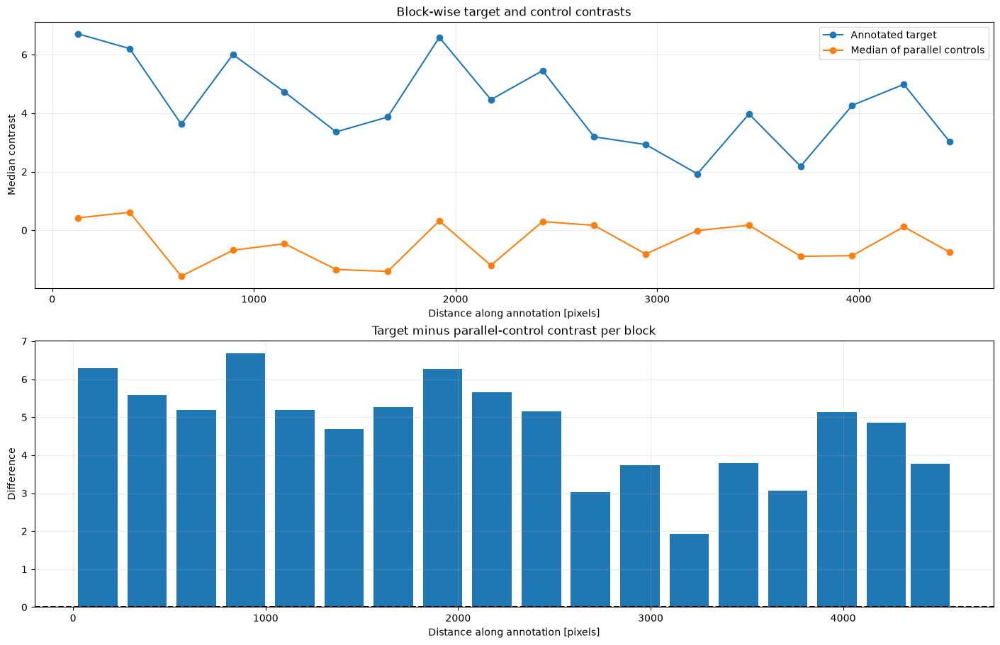


Saved: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/paired_target_control_block_analysis.png
Memory: {'process_rss_gib': 0.6, 'available_ram_gib': 6.107}


In [15]:
# ============================================================
# CELL 13 — PAIRED TARGET/CONTROL VALIDATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy import ndimage as ndi


# ------------------------------------------------------------
# 1. Warning-free row-wise median
# ------------------------------------------------------------

def finite_row_median(array):
    """
    Calculate one median per row without warnings for
    rows containing only NaNs.
    """

    array = np.asarray(array, dtype=np.float64)

    result = np.full(
        array.shape[0],
        np.nan,
        dtype=np.float64
    )

    valid_rows = np.isfinite(array).any(axis=1)

    if valid_rows.any():

        result[valid_rows] = np.nanmedian(
            array[valid_rows],
            axis=1
        )

    return result


# ------------------------------------------------------------
# 2. Recompute track sampling without all-NaN warnings
# ------------------------------------------------------------

def sample_track_checked(offset_px):

    u_shifted = u + float(offset_px)

    X = (
        visible_start[0]
        + s[:, None] * direction[0]
        + u_shifted[None, :] * normal[0]
    )

    Y = (
        visible_start[1]
        + s[:, None] * direction[1]
        + u_shifted[None, :] * normal[1]
    )

    coordinates = [
        Y.ravel(),
        X.ravel()
    ]

    samples = ndi.map_coordinates(
        image_raw,
        coordinates,
        order=1,
        mode="constant",
        cval=np.nan
    ).reshape(X.shape)

    repeated = ndi.map_coordinates(
        repeat_mask_for_validation.astype(np.uint8),
        coordinates,
        order=0,
        mode="constant",
        cval=0
    ).reshape(X.shape).astype(bool)

    core_values = samples[:, core_mask_1d]
    side_values = samples[:, sideband_mask_1d]

    core_median = finite_row_median(core_values)
    side_median = finite_row_median(side_values)

    contrast = core_median - side_median

    corrected_strip = (
        samples - side_median[:, None]
    )

    return {
        "samples": samples,
        "repeated": repeated,
        "corrected_strip": corrected_strip,
        "contrast": contrast,
        "core_median": core_median,
        "side_median": side_median,
        "X": X,
        "Y": Y
    }


# Recompute the five corridors using the corrected function.
track_results = {}

for offset in CONTROL_OFFSETS:

    track_results[offset] = sample_track_checked(
        offset
    )


# ------------------------------------------------------------
# 3. Common-valid-position comparison
# ------------------------------------------------------------

control_offsets = [
    offset
    for offset in CONTROL_OFFSETS
    if offset != 0
]

target_contrast = track_results[0.0]["contrast"]

control_contrasts = np.column_stack([
    track_results[offset]["contrast"]
    for offset in control_offsets
])

common_valid = (
    np.isfinite(target_contrast)
    & np.isfinite(control_contrasts).all(axis=1)
)

if common_valid.sum() < 0.9 * len(s):

    print(
        "WARNING: More than 10% of samples were lost "
        "from the common-valid comparison."
    )

target_valid = target_contrast[common_valid]

controls_valid = control_contrasts[common_valid]

# At every along-track position, take the median of the
# four control-corridor measurements.
control_reference = np.median(
    controls_valid,
    axis=1
)

paired_difference = (
    target_valid - control_reference
)

print("PAIRED TARGET/CONTROL COMPARISON")
print("--------------------------------")

print("Total along-track samples:", len(s))
print("Common valid samples:", int(common_valid.sum()))

print(
    "Common valid fraction:",
    float(common_valid.mean())
)

print(
    "Median target contrast:",
    float(np.median(target_valid))
)

print(
    "Median control reference:",
    float(np.median(control_reference))
)

print(
    "Median paired difference:",
    float(np.median(paired_difference))
)

print(
    "Fraction of paired samples where target > controls:",
    float(np.mean(paired_difference > 0))
)


# ------------------------------------------------------------
# 4. Block-level comparison
# ------------------------------------------------------------

BLOCK_LENGTH = 256.0

block_edges = np.arange(
    0,
    L + BLOCK_LENGTH,
    BLOCK_LENGTH
)

paired_block_records = []

for left, right in zip(
    block_edges[:-1],
    block_edges[1:]
):

    use = (
        common_valid
        & (s >= left)
        & (s < right)
    )

    if use.sum() < 20:
        continue

    target_values = target_contrast[use]
    control_values = control_contrasts[use]

    control_at_positions = np.median(
        control_values,
        axis=1
    )

    target_median = float(
        np.median(target_values)
    )

    control_median = float(
        np.median(control_at_positions)
    )

    difference = (
        target_median - control_median
    )

    paired_block_records.append({

        "s_start": float(left),

        "s_end": float(min(right, L)),

        "n_samples": int(use.sum()),

        "target_median": target_median,

        "control_median": control_median,

        "target_minus_control": float(difference),

        "target_positive_fraction": float(
            np.mean(target_values > 0)
        ),

        "fraction_target_above_control": float(
            np.mean(target_values > control_at_positions)
        )
    })


print("\nBLOCK-LEVEL PAIRED RESULTS")
print("--------------------------")

for record in paired_block_records:

    print(record)


block_differences = np.array([
    r["target_minus_control"]
    for r in paired_block_records
])

if len(block_differences) < 5:

    raise RuntimeError(
        "Too few valid blocks for a meaningful descriptive comparison."
    )


print("\nSUMMARY OF BLOCK DIFFERENCES")
print("-----------------------------")

print(
    "Positive blocks:",
    int(np.sum(block_differences > 0)),
    "/",
    len(block_differences)
)

print(
    "Median block difference:",
    float(np.median(block_differences))
)

print(
    "Minimum block difference:",
    float(np.min(block_differences))
)

print(
    "Maximum block difference:",
    float(np.max(block_differences))
)


# ------------------------------------------------------------
# 5. Descriptive block-bootstrap interval
# ------------------------------------------------------------

# This resamples whole 256-pixel blocks, not individual pixels.
# It is still an approximate diagnostic: blocks may remain
# correlated because of extended backgrounds and optical effects.

rng = np.random.default_rng(RANDOM_SEED)

N_BOOTSTRAP = 10000

bootstrap_medians = np.empty(
    N_BOOTSTRAP,
    dtype=np.float64
)

for i in range(N_BOOTSTRAP):

    sampled = rng.choice(
        block_differences,
        size=len(block_differences),
        replace=True
    )

    bootstrap_medians[i] = np.median(
        sampled
    )

bootstrap_interval = np.percentile(
    bootstrap_medians,
    [2.5, 50, 97.5]
)

print("\nDESCRIPTIVE BLOCK-BOOTSTRAP INTERVAL")
print("------------------------------------")

print("2.5%:", float(bootstrap_interval[0]))
print("Median:", float(bootstrap_interval[1]))
print("97.5%:", float(bootstrap_interval[2]))

print(
    "Interpretation: descriptive interval over the sampled "
    "blocks, not a calibrated detection significance."
)


# ------------------------------------------------------------
# 6. Estimate median cross-track FWHM without a Gaussian fit
# ------------------------------------------------------------

median_cross_profile = np.nanmedian(
    track_results[0.0]["corrected_strip"],
    axis=0
)

# Estimate baseline using the two background sidebands.
baseline_values = median_cross_profile[
    sideband_mask_1d
]

profile_baseline = float(
    np.nanmedian(baseline_values)
)

profile_excess = (
    median_cross_profile - profile_baseline
)

peak_index = int(
    np.nanargmax(profile_excess)
)

peak_offset = float(
    u[peak_index]
)

peak_excess = float(
    profile_excess[peak_index]
)

half_peak = 0.5 * peak_excess


def interpolate_crossing(x0, y0, x1, y1, level):

    if y1 == y0:
        return float(0.5 * (x0 + x1))

    return float(
        x0 + (level - y0) * (x1 - x0) / (y1 - y0)
    )


left_crossing = None
right_crossing = None

# Search to the left of the peak.
for i in range(peak_index - 1, -1, -1):

    if (
        profile_excess[i] <= half_peak
        and profile_excess[i + 1] > half_peak
    ):

        left_crossing = interpolate_crossing(
            u[i],
            profile_excess[i],
            u[i + 1],
            profile_excess[i + 1],
            half_peak
        )

        break


# Search to the right of the peak.
for i in range(peak_index, len(u) - 1):

    if (
        profile_excess[i] > half_peak
        and profile_excess[i + 1] <= half_peak
    ):

        right_crossing = interpolate_crossing(
            u[i],
            profile_excess[i],
            u[i + 1],
            profile_excess[i + 1],
            half_peak
        )

        break


if (
    left_crossing is not None
    and right_crossing is not None
):

    empirical_profile_fwhm = (
        right_crossing - left_crossing
    )

else:

    empirical_profile_fwhm = np.nan


print("\nCROSS-TRACK PROFILE")
print("-------------------")

print("Baseline:", profile_baseline)
print("Peak excess:", peak_excess)
print("Peak offset from annotation:", peak_offset)

print("Half-maximum level:", half_peak)

print("Left crossing:", left_crossing)
print("Right crossing:", right_crossing)

print(
    "Empirical profile FWHM:",
    empirical_profile_fwhm
)

print(
    "Annotation width:",
    annotation_width
)

print(
    "Header FWHM:",
    HEADER_FWHM_PIX
)


# ------------------------------------------------------------
# 7. Visualise block-level behaviour
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9),
    constrained_layout=True
)

block_centres = np.array([
    0.5 * (r["s_start"] + r["s_end"])
    for r in paired_block_records
])

target_block_values = np.array([
    r["target_median"]
    for r in paired_block_records
])

control_block_values = np.array([
    r["control_median"]
    for r in paired_block_records
])

difference_values = np.array([
    r["target_minus_control"]
    for r in paired_block_records
])


axes[0].plot(
    block_centres,
    target_block_values,
    marker="o",
    label="Annotated target"
)

axes[0].plot(
    block_centres,
    control_block_values,
    marker="o",
    label="Median of parallel controls"
)

axes[0].set_title(
    "Block-wise target and control contrasts"
)

axes[0].set_xlabel("Distance along annotation [pixels]")
axes[0].set_ylabel("Median contrast")

axes[0].legend()
axes[0].grid(alpha=0.25)


axes[1].bar(
    block_centres,
    difference_values,
    width=BLOCK_LENGTH * 0.8
)

axes[1].axhline(
    0,
    color="black",
    linestyle="--"
)

axes[1].set_title(
    "Target minus parallel-control contrast per block"
)

axes[1].set_xlabel("Distance along annotation [pixels]")
axes[1].set_ylabel("Difference")

axes[1].grid(alpha=0.25)


PAIRED_FIGURE_PATH = (
    FRAME_OUTPUT_DIR /
    "paired_target_control_block_analysis.png"
)

fig.savefig(
    PAIRED_FIGURE_PATH,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved:", PAIRED_FIGURE_PATH)
print("Memory:", memory_report())

### Background estimation and bright-source inventory


Before extracting sources, we need an estimate of the spatially varying background.

Remember the row-median result:
- Near \(y=384\), the median is approximately 189.
- Near \(y=2000\), it is close to zero.
- Near the top of the frame, it is approximately −30.
The ILMT literature also documents spatially varying illumination and background corrections in these images. OUP Academic

We should therefore use a spatial background estimator rather than a global median.

For this stage, we will use SEP, but only after understanding what it does.

**What does SEP.Background do?**

SEP divides the image into rectangular boxes, estimates the background and its RMS in each box, filters the resulting mesh and interpolates the values across the image.

The two important parameters are:
- bw, bh: background box dimensions in original pixels.
- fw, fh: filtering dimensions measured in mesh boxes.
The SEP documentation describes this as a spatially varying background and noise estimator.

For this frame we choose 3 options as:
| Box size | Mesh grid | Purpose |
|---|---:|---|
| 64 px | 64 × 64 | Detailed local-background model |
| 128 px | 32 × 32 | Intermediate-scale model |
| 256 px | 16 × 16 | Broader background model |

A small mesh can mistake extended halos for background and subtract them. A large mesh can fail to follow genuine background variation. We need evidence showing which behaviour occurs.

SEP BACKGROUND COMPARISON
-------------------------

PROCESSING BACKGROUND MESH: 64 × 64 PIXELS

RMS QUALITY REPORT
total_pixels                       : 16777216
finite_pixels                      : 16777216
positive_pixels                    : 16776468
zero_pixels                        : 0
negative_pixels                    : 748
nonfinite_pixels                   : 0
invalid_pixels                     : 748
invalid_fraction                   : 4.458427429199219e-05
median_fill_distance_pixels        : 4.0
maximum_fill_distance_pixels       : 9.486832980505138
repair_method                      : nearest_valid_positive_neighbour

ORIGINAL POSITIVE RMS STATISTICS
min                                : 0.000743865966796875
p1                                 : 16.798921585083008
p5                                 : 16.98223114013672
p10                                : 17.087615966796875
median                             : 17.58021354675293
p90                                : 22.2039260

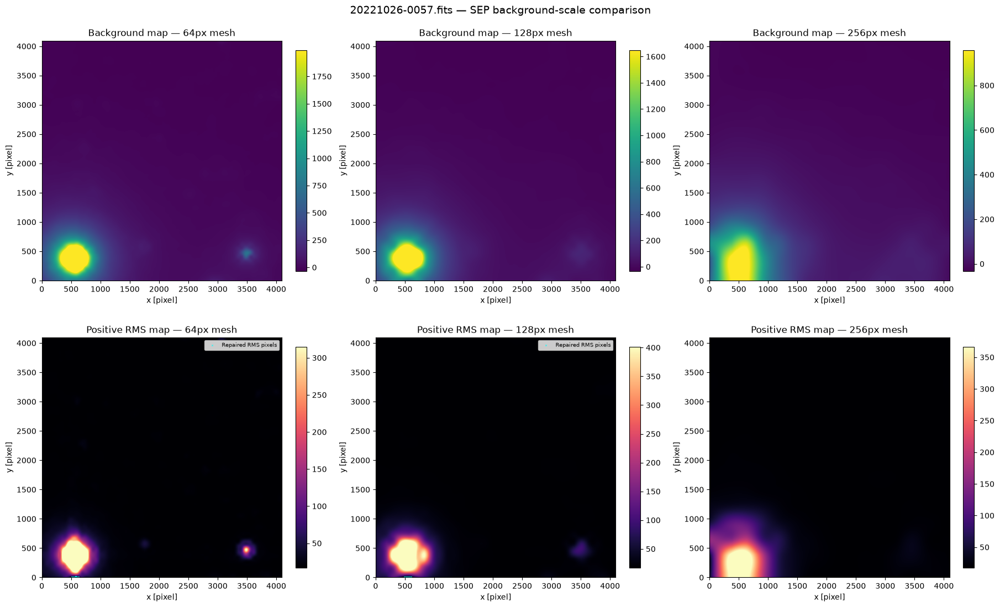


BACKGROUND MODEL COMPARISON
---------------------------
{'mesh': 64, 'background_median': -4.267338275909424, 'background_p10': -27.023691177368164, 'background_p90': 153.2621307373047, 'rms_positive_median': 17.58021354675293, 'rms_positive_p10': 17.087615966796875, 'rms_positive_p90': 22.20392608642578, 'rms_invalid_count': 748, 'target_contrast': 4.329639732837677, 'control_contrast': -0.46637885086238384, 'target_minus_control': 4.796018583700061}
{'mesh': 128, 'background_median': -4.286508798599243, 'background_p10': -26.56967830657959, 'background_p90': 138.42935943603516, 'rms_positive_median': 17.838668823242188, 'rms_positive_p10': 17.285655975341797, 'rms_positive_p90': 27.039276123046875, 'rms_invalid_count': 635, 'target_contrast': 4.394455075263977, 'control_contrast': -0.472037672996521, 'target_minus_control': 4.866492748260498}
{'mesh': 256, 'background_median': -3.985003709793091, 'background_p10': -26.71601104736328, 'background_p90': 133.07817840576172, 'rms_positi

In [16]:
# ============================================================
# CELL 14 — SEP MULTI-SCALE BACKGROUND COMPARISON
#
# Purpose:
#   1. Estimate spatial background at multiple scales.
#   2. Examine corresponding local RMS maps.
#   3. Test whether background subtraction preserves the
#      manually annotated linear excess relative to controls.
#
# IMPORTANT:
#   This is a diagnostic experiment, not final preprocessing.
#   The original image_raw is never modified.
# ============================================================

import sep
import gc
import json
import numpy as np
import matplotlib.pyplot as plt

from scipy import ndimage as ndi


# ------------------------------------------------------------
# 1. PREPARE SEP INPUT
# ------------------------------------------------------------

sep_data = np.ascontiguousarray(
    image_raw,
    dtype=np.float32
)

if sep_data.shape != image_raw.shape:

    raise RuntimeError(
        "SEP input shape differs from the raw image."
    )

if not np.isfinite(sep_data).all():

    raise RuntimeError(
        "SEP input contains non-finite pixels."
    )


# ------------------------------------------------------------
# 2. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

SEP_BACKGROUND_BOXES = [64, 128, 256]

SEP_FILTER_BOXES = 3

# Diagnostic repair is allowed only as a separate array.
# It never modifies the original SEP RMS output.
RMS_REPAIR_METHOD = "nearest_valid_positive_neighbour"

SEP_BACKGROUND_MODELS = {}

SEP_BACKGROUND_SUMMARIES = {}

# Re-run safety: discard partial results from the failed cell.
SEP_BACKGROUND_MODELS.clear()

SEP_BACKGROUND_SUMMARIES.clear()


# ------------------------------------------------------------
# 3. HELPER — SAFE ROW-WISE MEDIAN
# ------------------------------------------------------------

def finite_median_rows(array):

    array = np.asarray(
        array,
        dtype=np.float64
    )

    result = np.full(
        array.shape[0],
        np.nan,
        dtype=np.float64
    )

    valid_rows = np.isfinite(array).any(axis=1)

    if valid_rows.any():

        result[valid_rows] = np.nanmedian(
            array[valid_rows],
            axis=1
        )

    return result


# ------------------------------------------------------------
# 4. HELPER — SAMPLE TARGET/CONTROL CONTRAST
# ------------------------------------------------------------

def contrast_on_array(data, offset_px):

    u_shifted = (
        u + float(offset_px)
    )

    X = (
        visible_start[0]
        + s[:, None] * direction[0]
        + u_shifted[None, :] * normal[0]
    )

    Y = (
        visible_start[1]
        + s[:, None] * direction[1]
        + u_shifted[None, :] * normal[1]
    )

    samples = ndi.map_coordinates(
        data,
        [Y.ravel(), X.ravel()],
        order=1,
        mode="constant",
        cval=np.nan
    ).reshape(X.shape)

    core = samples[:, core_mask_1d]

    side = samples[:, sideband_mask_1d]

    core_median = finite_median_rows(core)

    side_median = finite_median_rows(side)

    contrast = (
        core_median - side_median
    )

    valid = np.isfinite(contrast)

    if not valid.any():

        return {

            "median_contrast": np.nan,

            "positive_fraction": np.nan,

            "valid_fraction": 0.0,

            "contrast": contrast

        }

    return {

        "median_contrast": float(
            np.median(contrast[valid])
        ),

        "positive_fraction": float(
            np.mean(contrast[valid] > 0)
        ),

        "valid_fraction": float(
            valid.mean()
        ),

        "contrast": contrast

    }


# ------------------------------------------------------------
# 5. HELPER — RMS MAP VALIDATION AND LOCAL REPAIR
# ------------------------------------------------------------

def validate_and_repair_rms(rms_input):

    """
    Preserve the raw SEP RMS map.

    Create a separate diagnostic RMS map in which:
        - Non-finite values are invalid.
        - Zero values are invalid.
        - Negative values are invalid.
        - Invalid values are replaced using their nearest
          finite, positive RMS neighbour.

    Returns the original map, repaired map, invalid mask,
    and detailed quality diagnostics.
    """

    rms_raw = np.asarray(
        rms_input,
        dtype=np.float32
    )

    if rms_raw.shape != image_raw.shape:

        raise RuntimeError(
            "RMS map has an unexpected image shape."
        )

    finite_mask = np.isfinite(rms_raw)

    positive_mask = (
        finite_mask
        & (rms_raw > 0)
    )

    zero_mask = (
        finite_mask
        & (rms_raw == 0)
    )

    negative_mask = (
        finite_mask
        & (rms_raw < 0)
    )

    invalid_mask = ~positive_mask

    n_total = int(rms_raw.size)

    n_finite = int(finite_mask.sum())

    n_positive = int(positive_mask.sum())

    n_zero = int(zero_mask.sum())

    n_negative = int(negative_mask.sum())

    n_nonfinite = int(
        (~finite_mask).sum()
    )

    if n_positive == 0:

        raise RuntimeError(
            "No finite positive RMS values are available."
        )

    # Separate output. Never overwrite rms_raw.
    rms_used = rms_raw.copy()

    # --------------------------------------------------------
    # Local nearest-positive repair
    # --------------------------------------------------------

    if invalid_mask.any():

        distances, indices = ndi.distance_transform_edt(
            invalid_mask,
            return_distances=True,
            return_indices=True
        )

        nearest_valid_values = rms_raw[
            tuple(indices)
        ]

        rms_used[invalid_mask] = (
            nearest_valid_values[invalid_mask]
        )

        maximum_fill_distance = float(
            distances[invalid_mask].max()
        )

        median_fill_distance = float(
            np.median(distances[invalid_mask])
        )

    else:

        maximum_fill_distance = 0.0

        median_fill_distance = 0.0

    # --------------------------------------------------------
    # Validate repaired map
    # --------------------------------------------------------

    if not np.isfinite(rms_used).all():

        raise RuntimeError(
            "Repaired RMS map still contains non-finite values."
        )

    if np.any(rms_used <= 0):

        raise RuntimeError(
            "Repaired RMS map contains non-positive values."
        )

    repair_report = {

        "total_pixels": n_total,

        "finite_pixels": n_finite,

        "positive_pixels": n_positive,

        "zero_pixels": n_zero,

        "negative_pixels": n_negative,

        "nonfinite_pixels": n_nonfinite,

        "invalid_pixels": int(invalid_mask.sum()),

        "invalid_fraction": float(
            invalid_mask.mean()
        ),

        "median_fill_distance_pixels": median_fill_distance,

        "maximum_fill_distance_pixels": maximum_fill_distance,

        "repair_method": RMS_REPAIR_METHOD

    }

    return (
        rms_raw,
        rms_used,
        invalid_mask,
        repair_report
    )


# ------------------------------------------------------------
# 6. HELPER — RMS DISTRIBUTION STATISTICS
# ------------------------------------------------------------

def positive_rms_statistics(rms):

    rms = np.asarray(
        rms,
        dtype=np.float64
    )

    positive = (
        np.isfinite(rms)
        & (rms > 0)
    )

    values = rms[positive]

    if values.size == 0:

        raise RuntimeError(
            "No positive RMS values available for statistics."
        )

    percentiles = np.percentile(
        values,
        [0, 1, 5, 10, 50, 90, 95, 99, 100]
    )

    return {

        "min": float(percentiles[0]),

        "p1": float(percentiles[1]),

        "p5": float(percentiles[2]),

        "p10": float(percentiles[3]),

        "median": float(percentiles[4]),

        "p90": float(percentiles[5]),

        "p95": float(percentiles[6]),

        "p99": float(percentiles[7]),

        "max": float(percentiles[8]),

        "positive_pixel_count": int(values.size)

    }


# ------------------------------------------------------------
# 7. HELPER — BACKGROUND DISTRIBUTION STATISTICS
# ------------------------------------------------------------

def background_statistics(background):

    background = np.asarray(
        background,
        dtype=np.float64
    )

    values = background[
        np.isfinite(background)
    ]

    percentiles = np.percentile(
        values,
        [0, 1, 10, 50, 90, 99, 100]
    )

    return {

        "min": float(percentiles[0]),

        "p1": float(percentiles[1]),

        "p10": float(percentiles[2]),

        "median": float(percentiles[3]),

        "p90": float(percentiles[4]),

        "p99": float(percentiles[5]),

        "max": float(percentiles[6])

    }


# ------------------------------------------------------------
# 8. RUN THE MULTI-SCALE SEP EXPERIMENT
# ------------------------------------------------------------

print("SEP BACKGROUND COMPARISON")
print("-------------------------")

for box in SEP_BACKGROUND_BOXES:

    print("\n" + "=" * 65)

    print(
        f"PROCESSING BACKGROUND MESH: {box} × {box} PIXELS"
    )

    print("=" * 65)

    # --------------------------------------------------------
    # A. Estimate background and RMS
    # --------------------------------------------------------

    bkg = sep.Background(
        sep_data,
        bw=box,
        bh=box,
        fw=SEP_FILTER_BOXES,
        fh=SEP_FILTER_BOXES
    )

    global_background = float(
        bkg.globalback
    )

    global_rms = float(
        bkg.globalrms
    )

    # Original interpolated maps.
    background_map = np.asarray(
        bkg.back(),
        dtype=np.float32
    )

    rms_map_raw = np.asarray(
        bkg.rms(),
        dtype=np.float32
    )

    # --------------------------------------------------------
    # B. Validate background map
    # --------------------------------------------------------

    if background_map.shape != image_raw.shape:

        raise RuntimeError(
            f"Unexpected background shape for mesh {box}."
        )

    if not np.isfinite(background_map).all():

        raise RuntimeError(
            f"Background map contains non-finite pixels "
            f"for mesh {box}."
        )

    # --------------------------------------------------------
    # C. Validate RMS and construct separate repaired map
    # --------------------------------------------------------

    (
        rms_map_raw,
        rms_map_used,
        rms_invalid_mask,
        rms_quality
    ) = validate_and_repair_rms(
        rms_map_raw
    )

    # Raw map statistics exclude invalid locations.
    rms_stats_raw = positive_rms_statistics(
        rms_map_raw
    )

    # Repaired map statistics are reported separately.
    rms_stats_used = positive_rms_statistics(
        rms_map_used
    )

    bg_stats = background_statistics(
        background_map
    )

    print("\nRMS QUALITY REPORT")

    for key, value in rms_quality.items():

        print(f"{key:35s}: {value}")

    print("\nORIGINAL POSITIVE RMS STATISTICS")

    for key, value in rms_stats_raw.items():

        print(f"{key:35s}: {value}")

    print("\nSEP GLOBAL ESTIMATES")

    print("Global background:", global_background)
    print("Global RMS:", global_rms)

    print("\nBACKGROUND MAP STATISTICS")

    for key, value in bg_stats.items():

        print(f"{key:35s}: {value}")

    # --------------------------------------------------------
    # D. Keep all versions separately
    # --------------------------------------------------------

    SEP_BACKGROUND_MODELS[box] = {

        "background": background_map,

        "rms_raw": rms_map_raw,

        "rms": rms_map_used,

        "rms_invalid_mask": rms_invalid_mask,

        "rms_quality": rms_quality,

        "global_background": global_background,

        "global_rms": global_rms,

        "box_size": box,

        "filter_size": SEP_FILTER_BOXES

    }

    # --------------------------------------------------------
    # E. Subtract background for this diagnostic only
    # --------------------------------------------------------

    residual = np.subtract(
        sep_data,
        background_map,
        dtype=np.float32
    )

    if not np.isfinite(residual).all():

        raise RuntimeError(
            f"Residual contains non-finite pixels "
            f"for mesh {box}."
        )

    # --------------------------------------------------------
    # F. Compare target corridor
    # --------------------------------------------------------

    target_result = contrast_on_array(
        residual,
        0
    )

    control_results = {

        offset: contrast_on_array(
            residual,
            offset
        )

        for offset in CONTROL_OFFSETS
        if offset != 0

    }

    control_values = np.array([

        result["median_contrast"]

        for result in control_results.values()

    ], dtype=np.float64)

    control_values = control_values[
        np.isfinite(control_values)
    ]

    if control_values.size == 0:

        raise RuntimeError(
            "No valid control corridor results."
        )

    control_median = float(
        np.median(control_values)
    )

    target_control_difference = float(
        target_result["median_contrast"]
        - control_median
    )

    # --------------------------------------------------------
    # G. Store summary
    # --------------------------------------------------------

    summary = {

        "box_size": box,

        "filter_size_mesh_boxes": SEP_FILTER_BOXES,

        "global_background": global_background,

        "global_rms": global_rms,

        "background_stats": bg_stats,

        "rms_quality": rms_quality,

        "rms_stats_raw": rms_stats_raw,

        "rms_stats_used": rms_stats_used,

        "target_contrast":
            target_result["median_contrast"],

        "target_positive_fraction":
            target_result["positive_fraction"],

        "target_valid_fraction":
            target_result["valid_fraction"],

        "control_median_contrast":
            control_median,

        "target_minus_control":
            target_control_difference

    }

    SEP_BACKGROUND_SUMMARIES[box] = summary

    print("\nTARGET/CONTROL COMPARISON")

    print(
        "Target median contrast:",
        target_result["median_contrast"]
    )

    print(
        "Target positive fraction:",
        target_result["positive_fraction"]
    )

    print(
        "Control median contrast:",
        control_median
    )

    print(
        "Target minus control:",
        target_control_difference
    )

    # --------------------------------------------------------
    # H. Release temporary objects
    # --------------------------------------------------------

    del residual
    del bkg

    gc.collect()

    print("\nMemory:", memory_report())


# ------------------------------------------------------------
# 9. PLOT BACKGROUND AND RMS MAPS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 11),
    constrained_layout=True
)

for col, box in enumerate(SEP_BACKGROUND_BOXES):

    model = SEP_BACKGROUND_MODELS[box]

    background_map = model["background"]

    # Use the separate positive-valued map.
    rms_map_used = model["rms"]

    invalid_mask = model["rms_invalid_mask"]

    # --------------------------------------------------------
    # A. Background display limits
    # --------------------------------------------------------

    bg_low, bg_high = np.percentile(
        background_map,
        [1, 99]
    )

    if bg_high <= bg_low:
        bg_high = bg_low + 1.0

    # --------------------------------------------------------
    # B. Positive RMS display limits
    # --------------------------------------------------------

    valid_rms_values = rms_map_used[
        np.isfinite(rms_map_used)
        & (rms_map_used > 0)
    ]

    rms_low, rms_high = np.percentile(
        valid_rms_values,
        [1, 99]
    )

    if rms_high <= rms_low:
        rms_high = rms_low + 1.0

    # --------------------------------------------------------
    # C. Plot background
    # --------------------------------------------------------

    im0 = axes[0, col].imshow(
        background_map,
        origin="lower",
        cmap="viridis",
        vmin=bg_low,
        vmax=bg_high,
        interpolation="nearest"
    )

    axes[0, col].set_title(
        f"Background map — {box}px mesh"
    )

    axes[0, col].set_xlabel("x [pixel]")
    axes[0, col].set_ylabel("y [pixel]")

    fig.colorbar(
        im0,
        ax=axes[0, col],
        fraction=0.046,
        pad=0.04
    )

    # --------------------------------------------------------
    # D. Plot repaired positive RMS map
    # --------------------------------------------------------

    im1 = axes[1, col].imshow(
        rms_map_used,
        origin="lower",
        cmap="magma",
        vmin=rms_low,
        vmax=rms_high,
        interpolation="nearest"
    )

    # Overlay locations repaired from non-positive/non-finite
    # raw SEP RMS values.
    iy, ix = np.nonzero(invalid_mask)

    if len(ix):

        step = max(
            len(ix) // 1000,
            1
        )

        axes[1, col].scatter(
            ix[::step],
            iy[::step],
            s=3,
            marker="x",
            color="cyan",
            linewidths=0.5,
            label="Repaired RMS pixels"
        )

        axes[1, col].legend(
            loc="upper right",
            fontsize=7
        )

    axes[1, col].set_title(
        f"Positive RMS map — {box}px mesh"
    )

    axes[1, col].set_xlabel("x [pixel]")
    axes[1, col].set_ylabel("y [pixel]")

    fig.colorbar(
        im1,
        ax=axes[1, col],
        fraction=0.046,
        pad=0.04
    )


fig.suptitle(
    f"{FRAME_FILENAME} — SEP background-scale comparison",
    fontsize=14
)

SEP_BACKGROUND_FIGURE = (
    FRAME_OUTPUT_DIR /
    "sep_background_scale_comparison.png"
)

fig.savefig(
    SEP_BACKGROUND_FIGURE,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 10. COMPACT MODEL COMPARISON
# ------------------------------------------------------------

print("\nBACKGROUND MODEL COMPARISON")
print("---------------------------")

for box in SEP_BACKGROUND_BOXES:

    result = SEP_BACKGROUND_SUMMARIES[box]

    report = {

        "mesh": box,

        "background_median":
            result["background_stats"]["median"],

        "background_p10":
            result["background_stats"]["p10"],

        "background_p90":
            result["background_stats"]["p90"],

        "rms_positive_median":
            result["rms_stats_raw"]["median"],

        "rms_positive_p10":
            result["rms_stats_raw"]["p10"],

        "rms_positive_p90":
            result["rms_stats_raw"]["p90"],

        "rms_invalid_count":
            result["rms_quality"]["invalid_pixels"],

        "target_contrast":
            result["target_contrast"],

        "control_contrast":
            result["control_median_contrast"],

        "target_minus_control":
            result["target_minus_control"]

    }

    print(report)


# ------------------------------------------------------------
# 11. SAVE REPRODUCIBLE SUMMARY
# ------------------------------------------------------------

summary_json = {

    "frame": FRAME_FILENAME,

    "fits_sha256": FITS_SHA256,

    "method": "SEP spatial background estimation",

    "mask_used": False,

    "mesh_sizes": SEP_BACKGROUND_BOXES,

    "filter_size_mesh_boxes": SEP_FILTER_BOXES,

    "rms_repair_method": RMS_REPAIR_METHOD,

    "rms_repair_is_measurement": False,

    "variance_calibration_status":
        "Not calibrated total detector variance",

    "models": {

        str(box): summary

        for box, summary in SEP_BACKGROUND_SUMMARIES.items()

    }

}

SEP_BACKGROUND_SUMMARY_PATH = (
    FRAME_OUTPUT_DIR /
    "sep_background_scale_summary.json"
)

SEP_BACKGROUND_SUMMARY_PATH.write_text(
    json.dumps(
        summary_json,
        indent=2
    ),
    encoding="utf-8"
)


print("\nSTAGE 5 OUTPUTS")
print("---------------")

print("Background figure:", SEP_BACKGROUND_FIGURE)

print("Summary JSON:", SEP_BACKGROUND_SUMMARY_PATH)

print("Models generated:", list(SEP_BACKGROUND_MODELS.keys()))

print("\nMemory:", memory_report())

print("\nPASS: SEP multi-scale diagnostic completed.")

**1. What the maps convey?**

* 64 px: The map responds strongly to the bright-source structures. Its maximum estimated background is over 3,280. It follows smaller-scale structure, but risks treating portions of extended source profiles as background.

* 128 px: It retains the broad spatial gradient while producing a less extreme source response than the 64 px model. This is a reasonable compromise for an initial, unmasked source inventory.

* 256 px: It produces a smoother model and eliminates the non-positive RMS interpolation problem in this particular run. However, its background map is broader and less spatially detailed. Zero invalid RMS pixels do not make it automatically superior.

The three RMS maps should also not be interpreted as calibrated detector-noise maps. SEP estimates background fluctuations; that is not the same as a complete variance model containing all detector and source-photon contributions. sep.readthedocs.io

**2. What do we select?**

For the next experiment: PROVISIONAL_BACKGROUND_MESH = 128


But we will retain all three background models.

The selection is provisional because the models were estimated without source masks. The very obvious bright-source structures in the upper row of your figure are a warning that source contamination is influencing the background estimate.

The next objective is to create a preliminary source inventory, identify those structures, and then repeat background estimation with appropriate source masks.

We will not permanently subtract the background yet.

### Test whether background subtraction absorbs the annotated signal

We will calculate three quantities:
1. Contrast in the original image.
2. Contrast in the estimated background map.
3. Contrast in the background-subtracted residual.

If the background model contains a narrow ridge aligned with the target, subtracting it could weaken the signal.

In [20]:
# ============================================================
# CELL 15 — BUILD BACKGROUND-PRESERVATION TRACK RESULTS
#
# Samples the original image, each SEP background map, and each
# background-subtracted residual along the target and controls.
# ============================================================

import numpy as np

EXPECTED_CONTROL_OFFSETS = (-80.0, -40.0, 40.0, 80.0)
PRESERVATION_OFFSETS = (0.0, *EXPECTED_CONTROL_OFFSETS)
PRESERVATION_QUANTITIES = ("raw", "background", "residual")

required_names = (
    "SEP_BACKGROUND_MODELS",
    "SEP_BACKGROUND_BOXES",
    "contrast_on_array",
    "image_raw",
    "s",
    "FRAME_FILENAME",
)
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError(f"Run the preceding setup cells first; missing: {missing_names}")

if not set(PRESERVATION_OFFSETS).issubset(set(CONTROL_OFFSETS)):
    raise RuntimeError(
        f"CONTROL_OFFSETS must include {PRESERVATION_OFFSETS}; got {CONTROL_OFFSETS}."
    )

# Compute the raw-image tracks once, then retain them for cross-checks.
raw_track_results = {
    offset: contrast_on_array(image_raw, offset)
    for offset in PRESERVATION_OFFSETS
}

BACKGROUND_PRESERVATION_RESULTS = {}

for box in SEP_BACKGROUND_BOXES:
    if box not in SEP_BACKGROUND_MODELS:
        raise KeyError(f"SEP background model for {box}px is missing.")

    model = SEP_BACKGROUND_MODELS[box]
    background = np.asarray(model["background"], dtype=np.float32)
    if background.shape != image_raw.shape:
        raise ValueError(
            f"Background shape for {box}px is {background.shape}; "
            f"expected {image_raw.shape}."
        )

    residual = np.subtract(image_raw, background, dtype=np.float32)
    model_results = {}

    for offset in PRESERVATION_OFFSETS:
        raw_result = raw_track_results[offset]
        background_result = contrast_on_array(background, offset)
        residual_result = contrast_on_array(residual, offset)

        expected_shape = np.asarray(s).shape
        for label, sample_result in (
            ("raw", raw_result),
            ("background", background_result),
            ("residual", residual_result),
        ):
            contrast = np.asarray(sample_result["contrast"], dtype=np.float64)
            if contrast.ndim != 1 or contrast.shape != expected_shape:
                raise ValueError(
                    f"{label} track at offset {offset} for {box}px has "
                    f"shape {contrast.shape}; expected {expected_shape}."
                )

        model_results[offset] = {
            "raw_along_track": np.asarray(raw_result["contrast"], dtype=np.float64),
            "background_along_track": np.asarray(
                background_result["contrast"], dtype=np.float64
            ),
            "residual_along_track": np.asarray(
                residual_result["contrast"], dtype=np.float64
            ),
        }

    BACKGROUND_PRESERVATION_RESULTS[box] = model_results

print("BACKGROUND-PRESERVATION TRACKS READY")
print("-------------------------------------")
print("Meshes:", sorted(BACKGROUND_PRESERVATION_RESULTS))
print("Offsets [px]:", PRESERVATION_OFFSETS)
print("Quantities:", PRESERVATION_QUANTITIES)
print("Samples per track:", len(s))

BACKGROUND-PRESERVATION TRACKS READY
-------------------------------------
Meshes: [64, 128, 256]
Offsets [px]: (0.0, -80.0, -40.0, 40.0, 80.0)
Quantities: ('raw', 'background', 'residual')
Samples per track: 2277



BACKGROUND MESH: 64px
  raw       : target=4.3723, control=-0.4207, paired=4.6915, target>control=73.3%
  background: target=0.0025, control=-0.0070, paired=0.0100, target>control=56.8%
  residual  : target=4.2920, control=-0.3943, paired=4.5648, target>control=72.7%

BACKGROUND MESH: 128px
  raw       : target=4.3723, control=-0.4207, paired=4.6915, target>control=73.3%
  background: target=-0.0032, control=-0.0035, paired=-0.0006, target>control=46.4%
  residual  : target=4.3511, control=-0.4222, paired=4.6802, target>control=73.0%

BACKGROUND MESH: 256px
  raw       : target=4.3723, control=-0.4207, paired=4.6915, target>control=73.3%
  background: target=0.0007, control=0.0005, paired=-0.0001, target>control=40.7%
  residual  : target=4.3139, control=-0.4281, paired=4.6460, target>control=73.1%
Mesh 64px residual: positive blocks = 18/18
Mesh 128px residual: positive blocks = 18/18
Mesh 256px residual: positive blocks = 18/18


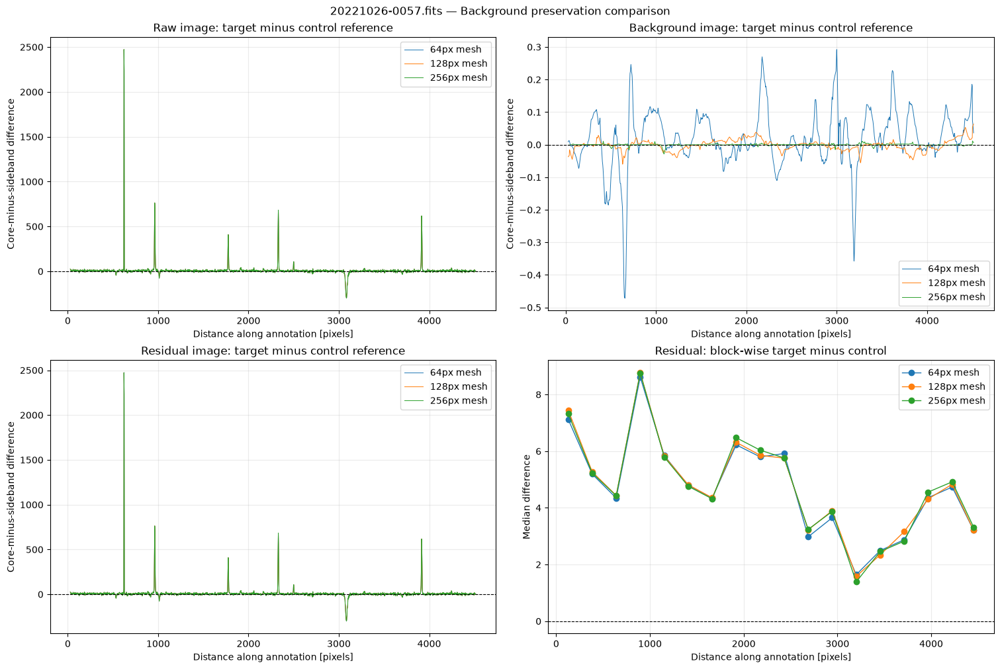


Saved figure: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/corrected_background_preservation_comparison.png
Saved JSON: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/corrected_background_preservation.json
Memory: {'process_rss_gib': 1.749, 'available_ram_gib': 4.604}


In [21]:
# ============================================================
# CELL 15.1 — CORRECTED TARGET/CONTROL COMPARISON
# ============================================================

import json
import numpy as np
import matplotlib.pyplot as plt

EXPECTED_CONTROL_OFFSETS = (-80.0, -40.0, 40.0, 80.0)
PRESERVATION_QUANTITIES = ("raw", "background", "residual")

if "BACKGROUND_PRESERVATION_RESULTS" not in globals():
    raise RuntimeError(
        "Background-preservation tracks are missing. Run Cell 15 first."
    )
if not BACKGROUND_PRESERVATION_RESULTS:
    raise RuntimeError("Cell 15 produced no background-preservation results.")
if "raw_track_results" not in globals():
    raise RuntimeError("Raw track cross-checks are missing. Run Cell 15 first.")
if np.asarray(s).ndim != 1:
    raise ValueError(f"Along-track coordinate must be 1-D; got {np.asarray(s).shape}.")


def get_control_stack(model_results, quantity):
    """Return target and four control tracks for one sampled quantity."""
    if 0.0 not in model_results:
        raise KeyError("Target offset 0.0 is missing from preservation results.")

    key = f"{quantity}_along_track"
    target = np.asarray(model_results[0.0][key], dtype=np.float64)
    if target.ndim != 1 or target.shape != np.asarray(s).shape:
        raise ValueError(
            f"Target {quantity} track has shape {target.shape}; expected {np.asarray(s).shape}."
        )

    control_arrays = []
    for offset in EXPECTED_CONTROL_OFFSETS:
        if offset not in model_results:
            raise KeyError(f"Control offset {offset} is missing from preservation results.")
        values = np.asarray(model_results[offset][key], dtype=np.float64)
        if values.ndim != 1 or values.shape != target.shape:
            raise ValueError(
                f"Control {quantity} track at {offset}px has shape {values.shape}; "
                f"expected {target.shape}."
            )
        control_arrays.append(values)

    return target, np.stack(control_arrays, axis=0)


# Paired target-minus-control measurements for raw, background, and residual tracks.
PRESERVATION_COMPARISON = {}

for box in SEP_BACKGROUND_BOXES:
    if box not in BACKGROUND_PRESERVATION_RESULTS:
        raise KeyError(f"Preservation results for the {box}px mesh are missing.")

    model_results = BACKGROUND_PRESERVATION_RESULTS[box]
    PRESERVATION_COMPARISON[box] = {}

    print(f"\nBACKGROUND MESH: {box}px")
    for quantity in PRESERVATION_QUANTITIES:
        target, controls = get_control_stack(model_results, quantity)
        common_valid = np.isfinite(target) & np.isfinite(controls).all(axis=0)
        if not common_valid.any():
            raise RuntimeError(f"No common valid positions for {box}px {quantity} tracks.")

        control_reference = np.median(controls[:, common_valid], axis=0)
        paired_difference = target[common_valid] - control_reference
        PRESERVATION_COMPARISON[box][quantity] = {
            "target": target,
            "controls": controls,
            "common_valid": common_valid,
            "control_reference": control_reference,
            "paired_difference": paired_difference,
            "median_target": float(np.median(target[common_valid])),
            "median_control_reference": float(np.median(control_reference)),
            "median_paired_difference": float(np.median(paired_difference)),
            "fraction_target_above_controls": float(np.mean(paired_difference > 0)),
            "common_valid_fraction": float(np.mean(common_valid)),
        }
        print(
            f"  {quantity:10s}: target={PRESERVATION_COMPARISON[box][quantity]['median_target']:.4f}, "
            f"control={PRESERVATION_COMPARISON[box][quantity]['median_control_reference']:.4f}, "
            f"paired={PRESERVATION_COMPARISON[box][quantity]['median_paired_difference']:.4f}, "
            f"target>control={PRESERVATION_COMPARISON[box][quantity]['fraction_target_above_controls']:.1%}"
        )


# Block-wise paired comparison of the background-subtracted residual.
BLOCK_LENGTH = 256.0
block_edges = np.arange(0.0, float(L) + BLOCK_LENGTH, BLOCK_LENGTH)
PRESERVATION_BLOCKS = {}

for box in SEP_BACKGROUND_BOXES:
    result = PRESERVATION_COMPARISON[box]["residual"]
    target = result["target"]
    controls = result["controls"]
    valid = result["common_valid"]
    records = []

    for left, right in zip(block_edges[:-1], block_edges[1:]):
        use = valid & (s >= left) & (s < right)
        if int(use.sum()) < 20:
            continue

        control_reference = np.median(controls[:, use], axis=0)
        difference = target[use] - control_reference
        records.append({
            "s_start": float(left),
            "s_end": float(min(right, L)),
            "n_samples": int(use.sum()),
            "target_median": float(np.median(target[use])),
            "control_median": float(np.median(control_reference)),
            "target_minus_control": float(np.median(difference)),
            "fraction_target_above_control": float(np.mean(difference > 0)),
        })

    PRESERVATION_BLOCKS[box] = records
    print(
        f"Mesh {box}px residual: positive blocks = "
        f"{sum(r['target_minus_control'] > 0 for r in records)}/{len(records)}"
    )


# Visualise paired target/control differences for all three quantities.
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
quantity_axes = {
    "raw": axes[0, 0],
    "background": axes[0, 1],
    "residual": axes[1, 0],
}

for quantity, ax in quantity_axes.items():
    for box in SEP_BACKGROUND_BOXES:
        result = PRESERVATION_COMPARISON[box][quantity]
        valid = result["common_valid"]
        paired = result["target"][valid] - result["control_reference"]
        ax.plot(s[valid], paired, linewidth=0.7, label=f"{box}px mesh")
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(f"{quantity.capitalize()} image: target minus control reference")
    ax.set_xlabel("Distance along annotation [pixels]")
    ax.set_ylabel("Core-minus-sideband difference")
    ax.legend()
    ax.grid(alpha=0.25)

for box in SEP_BACKGROUND_BOXES:
    records = PRESERVATION_BLOCKS[box]
    centres = [0.5 * (r["s_start"] + r["s_end"]) for r in records]
    differences = [r["target_minus_control"] for r in records]
    axes[1, 1].plot(centres, differences, marker="o", linewidth=1, label=f"{box}px mesh")

axes[1, 1].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[1, 1].set_title("Residual: block-wise target minus control")
axes[1, 1].set_xlabel("Distance along annotation [pixels]")
axes[1, 1].set_ylabel("Median difference")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.25)

fig.suptitle(f"{FRAME_FILENAME} — Background preservation comparison")
CORRECTED_PRESERVATION_FIGURE = (
    FRAME_OUTPUT_DIR / "corrected_background_preservation_comparison.png"
)
fig.savefig(CORRECTED_PRESERVATION_FIGURE, dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)


# Save JSON-safe summaries; large per-sample arrays remain in memory only.
comparison_json = {
    "frame": FRAME_FILENAME,
    "fits_sha256": FITS_SHA256,
    "method": "Paired annotated corridor vs four parallel controls",
    "control_offsets_px": list(EXPECTED_CONTROL_OFFSETS),
    "block_length_px": BLOCK_LENGTH,
    "results": {
        str(box): {
            quantity: {
                key: value
                for key, value in PRESERVATION_COMPARISON[box][quantity].items()
                if key not in {"target", "controls", "common_valid", "control_reference", "paired_difference"}
            }
            for quantity in PRESERVATION_QUANTITIES
        }
        for box in SEP_BACKGROUND_BOXES
    },
    "residual_blocks": {
        str(box): PRESERVATION_BLOCKS[box]
        for box in SEP_BACKGROUND_BOXES
    },
}

CORRECTED_PRESERVATION_JSON = (
    FRAME_OUTPUT_DIR / "corrected_background_preservation.json"
)
CORRECTED_PRESERVATION_JSON.write_text(
    json.dumps(comparison_json, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("\nSaved figure:", CORRECTED_PRESERVATION_FIGURE)
print("Saved JSON:", CORRECTED_PRESERVATION_JSON)
print("Memory:", memory_report())

### Interpretation of  our results

| Metric | 64 px | 128 px | 256 px |
|---|---:|---:|---:|
| Target contrast | 4.292 | 4.351 | 4.314 |
| Control reference | −0.394 | −0.422 | −0.428 |
| Target minus control | 4.565 | 4.680 | 4.646 |
| Target above controls | 72.68% | 73.04% | 73.08% |
| Positive blocks | 18/18 | 18/18 | 18/18 |

The three models produce very similar results. The 128-pixel mesh gives the largest median target-control difference, although the difference from the 256-pixel model is small.

We therefore retain 128px as our choice for bg_mesh

### Build the first source catalogue

**What are we doing?**

SEP identifies groups of connected pixels whose signal exceeds a specified detection threshold. It measures their centroids, fluxes, approximate shapes and other properties.

We will use:
- Background model: provisional 128 px mesh.
- Error map: corresponding positive SEP RMS map.
- Detection threshold: 5 times the local empirical RMS.
- Minimum connected area: 5 pixels.
- Deblending: enabled.
- Segmentation map: enabled.

When an error map is supplied, SEP interprets the threshold relative to the error at each pixel. Its default matched filtering also accounts for spatially varying noise. sep.readthedocs.io

**One qualification:** 

Our RMS map is an empirical background-noise estimate, not a fully calibrated detector-noise model. Consequently, this is a 5 × local empirical RMS detection threshold, not a calibrated 5σ astronomical significance.

**Why are we not masking stars yet?**

Because we first need to know where they are.

We will produce a catalogue and segmentation map, then inspect the results. We will not remove or modify any sources in this experiment.

SEP EXTRACTION INPUT
--------------------
Frame: 20221026-0057.fits
Background mesh: 128
Threshold: 5.0
Minimum area: 5
Residual shape: (4096, 4096)
Residual dtype: float32
Error map median: 17.838634490966797
Masked invalid-RMS pixels: 635
Repeated-value pixels: 72427
Note: repeated-value pixels are NOT masked in this initial inventory experiment.

RUNNING SEP SOURCE EXTRACTION
-----------------------------
Memory before: {'process_rss_gib': 1.829, 'available_ram_gib': 4.527}

SEP SOURCE EXTRACTION RESULTS
-----------------------------
Detected objects: 1412
Segmented pixels: 753401
Segmented image fraction: 0.04490619897842407
Maximum segmentation ID: 1412
Median detected-source area: 173.0
Maximum detected-source area: 44594
Median moment major axis: 3.1293872594833374
Median moment minor axis: 2.855157732963562
Memory after extraction: {'process_rss_gib': 1.892, 'available_ram_gib': 4.474}

20 LARGEST DETECTED OBJECTS
---------------------------
 object_id           x           y  

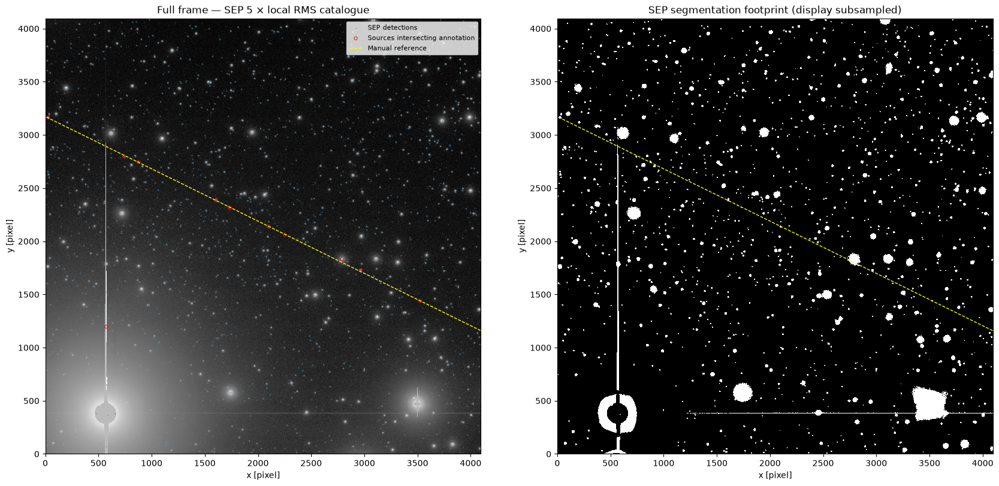

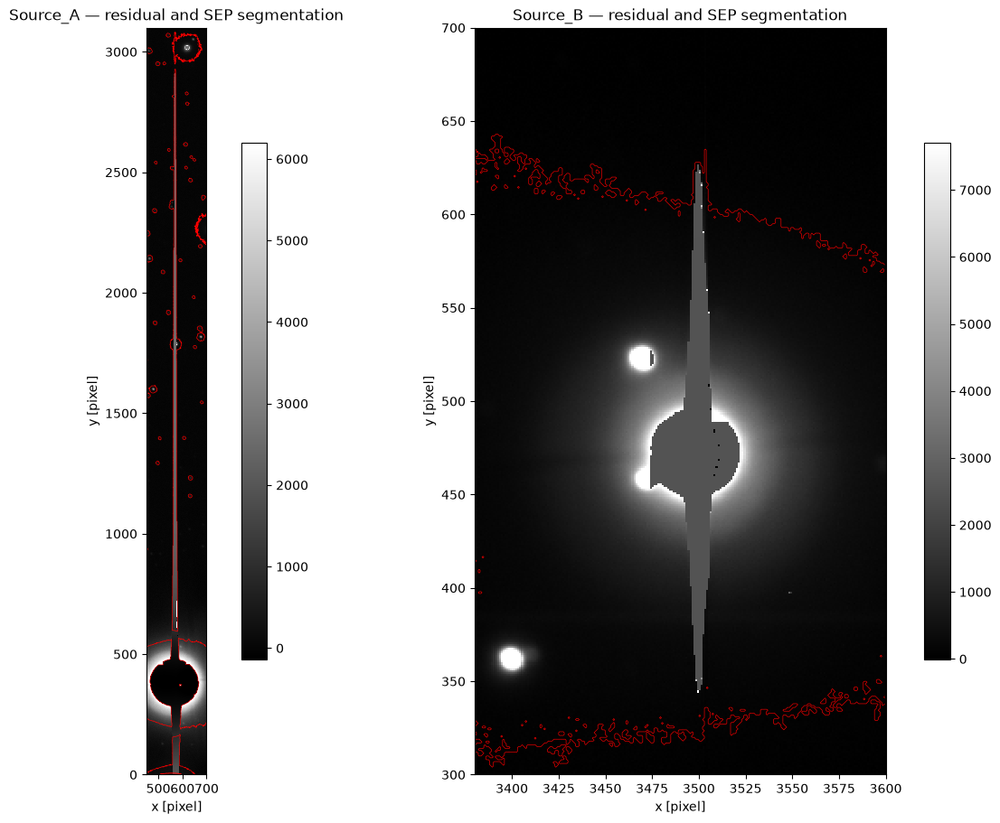


STAGE 6 COMPLETE
----------------
Catalogue: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/sep_source_catalogue_5sigma.csv
Segmentation map: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/sep_segmentation_map_5sigma.npy
Target intersections: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/sep_target_corridor_intersections.csv
Source figure: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/sep_source_catalogue_5sigma.png
Source zooms: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/sep_bright_source_segmentation_zooms.png
Summary: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/sep_source_extraction_summary.json

Memory: {'process_rss_gib': 1.908, 'available_ram_gib': 4.337}


In [22]:
# ============================================================
# CELL 16 — INITIAL SEP SOURCE EXTRACTION
#
# Purpose:
#   Build an inventory of compact and extended sources.
#   Generate a segmentation map.
#   Identify sources crossing the annotated corridor.
#
# No source subtraction or masking is performed here.
# ============================================================

import sep
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import gc

from scipy import ndimage as ndi


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

PROVISIONAL_BACKGROUND_MESH = 128

SEP_DETECTION_THRESHOLD = 5.0
SEP_MIN_AREA = 5

SEP_DEBLEND_NTHRESH = 32
SEP_DEBLEND_CONT = 0.005

SEP_CLEAN = True

# ------------------------------------------------------------
# 2. Retrieve the selected background model
# ------------------------------------------------------------

if PROVISIONAL_BACKGROUND_MESH not in SEP_BACKGROUND_MODELS:

    raise RuntimeError(
        "Provisional background model is unavailable."
    )

selected_model = SEP_BACKGROUND_MODELS[
    PROVISIONAL_BACKGROUND_MESH
]

selected_background = selected_model["background"]

selected_rms = selected_model["rms"]

selected_invalid_mask = selected_model["rms_invalid_mask"]


# ------------------------------------------------------------
# 3. Construct the background-subtracted image
# ------------------------------------------------------------

residual_128 = np.subtract(
    sep_data,
    selected_background,
    dtype=np.float32
)

if not np.isfinite(residual_128).all():

    raise RuntimeError(
        "Residual image contains non-finite pixels."
    )


# ------------------------------------------------------------
# 4. Validate the error map and mask
# ------------------------------------------------------------

sep_error_map = np.ascontiguousarray(
    selected_rms,
    dtype=np.float32
)

sep_extraction_mask = np.ascontiguousarray(
    selected_invalid_mask,
    dtype=bool
)

if sep_error_map.shape != residual_128.shape:

    raise RuntimeError(
        "Error map and residual image have different shapes."
    )

if not np.isfinite(sep_error_map).all():

    raise RuntimeError(
        "Error map contains non-finite values."
    )

if np.any(sep_error_map <= 0):

    raise RuntimeError(
        "Error map contains non-positive values."
    )

print("SEP EXTRACTION INPUT")
print("--------------------")

print("Frame:", FRAME_FILENAME)

print("Background mesh:", PROVISIONAL_BACKGROUND_MESH)

print("Threshold:", SEP_DETECTION_THRESHOLD)

print("Minimum area:", SEP_MIN_AREA)

print("Residual shape:", residual_128.shape)

print("Residual dtype:", residual_128.dtype)

print(
    "Error map median:",
    float(np.median(sep_error_map))
)

print(
    "Masked invalid-RMS pixels:",
    int(sep_extraction_mask.sum())
)

print(
    "Repeated-value pixels:",
    int(repeat_mask.sum())
)

print(
    "Note: repeated-value pixels are NOT masked in this "
    "initial inventory experiment."
)


# ------------------------------------------------------------
# 5. Execute SEP extraction
# ------------------------------------------------------------

print("\nRUNNING SEP SOURCE EXTRACTION")
print("-----------------------------")

memory_before_extraction = memory_report()

print("Memory before:", memory_before_extraction)

objects_5sigma, segmentation_map = sep.extract(

    residual_128,

    thresh=SEP_DETECTION_THRESHOLD,

    err=sep_error_map,

    mask=sep_extraction_mask,

    minarea=SEP_MIN_AREA,

    filter_type="matched",

    deblend_nthresh=SEP_DEBLEND_NTHRESH,

    deblend_cont=SEP_DEBLEND_CONT,

    clean=SEP_CLEAN,

    segmentation_map=True
)


# ------------------------------------------------------------
# 6. Validate extraction products
# ------------------------------------------------------------

segmentation_map = np.asarray(
    segmentation_map,
    dtype=np.int32
)

if segmentation_map.shape != image_raw.shape:

    raise RuntimeError(
        "Unexpected SEP segmentation-map shape."
    )

if len(objects_5sigma) == 0:

    raise RuntimeError(
        "SEP returned zero detected objects. "
        "Inspect threshold and background model."
    )

if segmentation_map.max() > len(objects_5sigma):

    raise RuntimeError(
        "Segmentation labels exceed the number of objects."
    )

if np.any(segmentation_map < 0):

    raise RuntimeError(
        "Unexpected negative segmentation labels."
    )


# ------------------------------------------------------------
# 7. Convert the structured catalogue to a DataFrame
# ------------------------------------------------------------

source_catalogue = pd.DataFrame.from_records(
    objects_5sigma
)

# SEP segmentation IDs start at one.
# Background pixels have segmentation ID zero.
source_catalogue.insert(
    0,
    "object_id",
    np.arange(
        1,
        len(source_catalogue) + 1,
        dtype=np.int32
    )
)


# ------------------------------------------------------------
# 8. Add shape and detection diagnostics
# ------------------------------------------------------------

required_fields = [
    "x",
    "y",
    "a",
    "b",
    "theta",
    "npix",
    "flux",
    "peak"
]

missing_fields = [
    field
    for field in required_fields
    if field not in source_catalogue.columns
]

if missing_fields:

    raise RuntimeError(
        f"SEP catalogue missing expected fields: {missing_fields}"
    )


# Axis ratio.
source_catalogue["axis_ratio"] = np.divide(
    source_catalogue["b"],
    source_catalogue["a"],
    out=np.full(
        len(source_catalogue),
        np.nan,
        dtype=np.float64
    ),
    where=source_catalogue["a"].to_numpy() > 0
)

# Ellipticity based on second moments.
source_catalogue["ellipticity"] = (
    1.0 - source_catalogue["axis_ratio"]
)

# Moment-equivalent FWHM proxies.
# These are not final PSF measurements.
source_catalogue["moment_fwhm_major"] = (
    2.354820045 * source_catalogue["a"]
)

source_catalogue["moment_fwhm_minor"] = (
    2.354820045 * source_catalogue["b"]
)

# Approximate peak/local-RMS diagnostic.
# It is not integrated-source significance.
xpeak = np.clip(
    source_catalogue["xpeak"].to_numpy(dtype=int),
    0,
    image_raw.shape[1] - 1
)

ypeak = np.clip(
    source_catalogue["ypeak"].to_numpy(dtype=int),
    0,
    image_raw.shape[0] - 1
)

local_peak_rms = sep_error_map[
    ypeak,
    xpeak
]

source_catalogue["peak_over_local_rms"] = (
    source_catalogue["peak"].to_numpy()
    / local_peak_rms
)


# ------------------------------------------------------------
# 9. General catalogue statistics
# ------------------------------------------------------------

n_objects = len(source_catalogue)

segmented_pixels = int(
    np.count_nonzero(segmentation_map)
)

segmented_fraction = (
    segmented_pixels / segmentation_map.size
)

print("\nSEP SOURCE EXTRACTION RESULTS")
print("-----------------------------")

print("Detected objects:", n_objects)

print("Segmented pixels:", segmented_pixels)

print("Segmented image fraction:", segmented_fraction)

print(
    "Maximum segmentation ID:",
    int(segmentation_map.max())
)

print(
    "Median detected-source area:",
    float(source_catalogue["npix"].median())
)

print(
    "Maximum detected-source area:",
    int(source_catalogue["npix"].max())
)

print(
    "Median moment major axis:",
    float(source_catalogue["a"].median())
)

print(
    "Median moment minor axis:",
    float(source_catalogue["b"].median())
)

print(
    "Memory after extraction:",
    memory_report()
)


# ------------------------------------------------------------
# 10. Inspect the largest and brightest detections
# ------------------------------------------------------------

print("\n20 LARGEST DETECTED OBJECTS")
print("---------------------------")

largest_objects = source_catalogue.nlargest(
    20,
    "npix"
)

print(
    largest_objects[
        [
            "object_id",
            "x",
            "y",
            "npix",
            "a",
            "b",
            "ellipticity",
            "flux",
            "peak",
            "flag"
        ]
    ].to_string(index=False)
)


print("\n20 BRIGHTEST PEAK DETECTIONS")
print("----------------------------")

brightest_objects = source_catalogue.nlargest(
    20,
    "peak"
)

print(
    brightest_objects[
        [
            "object_id",
            "x",
            "y",
            "npix",
            "a",
            "b",
            "flux",
            "peak",
            "peak_over_local_rms",
            "flag"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 11. Identify sources intersecting the manual corridor
# ------------------------------------------------------------

# This is an evaluation diagnostic.
# It is NOT supplied to SEP as a detection prior.

u_core = u[core_mask_1d]

X_target = (
    visible_start[0]
    + s[:, None] * direction[0]
    + u_core[None, :] * normal[0]
)

Y_target = (
    visible_start[1]
    + s[:, None] * direction[1]
    + u_core[None, :] * normal[1]
)

target_segmentation_ids = ndi.map_coordinates(

    segmentation_map,

    [
        Y_target.ravel(),
        X_target.ravel()
    ],

    order=0,

    mode="constant",

    cval=0
).astype(np.int32)

valid_target_ids = (
    target_segmentation_ids > 0
)

unique_target_ids, target_id_counts = np.unique(

    target_segmentation_ids[valid_target_ids],

    return_counts=True
)

target_intersections = []

samples_per_cross_section = len(u_core)

for object_id, sample_count in zip(
    unique_target_ids,
    target_id_counts
):

    sample_indices = np.flatnonzero(
        target_segmentation_ids == object_id
    )

    along_track_indices = (
        sample_indices // samples_per_cross_section
    )

    target_intersections.append({

        "object_id": int(object_id),

        "target_samples_intersected": int(sample_count),

        "along_track_start_px": float(
            s[along_track_indices.min()]
        ),

        "along_track_end_px": float(
            s[along_track_indices.max()]
        )

    })


target_intersection_df = pd.DataFrame(
    target_intersections
)

if not target_intersection_df.empty:

    target_intersection_df = target_intersection_df.merge(

        source_catalogue,

        on="object_id",

        how="left"

    )

    target_intersection_df = (
        target_intersection_df.sort_values(
            "target_samples_intersected",
            ascending=False
        )
    )


print("\nSOURCES INTERSECTING THE MANUAL CORRIDOR")
print("-----------------------------------------")

if target_intersection_df.empty:

    print("No SEP segmentation components intersect the corridor.")

else:

    display_columns = [

        "object_id",

        "target_samples_intersected",

        "along_track_start_px",

        "along_track_end_px",

        "x",

        "y",

        "npix",

        "a",

        "b",

        "ellipticity",

        "flux",

        "peak",

        "peak_over_local_rms"

    ]

    print(
        target_intersection_df[
            display_columns
        ].to_string(index=False)
    )


# ------------------------------------------------------------
# 12. Save catalogue and segmentation products
# ------------------------------------------------------------

SOURCE_CATALOGUE_PATH = (
    FRAME_OUTPUT_DIR /
    "sep_source_catalogue_5sigma.csv"
)

source_catalogue.to_csv(
    SOURCE_CATALOGUE_PATH,
    index=False
)

SEGMENTATION_MAP_PATH = (
    FRAME_OUTPUT_DIR /
    "sep_segmentation_map_5sigma.npy"
)

np.save(
    SEGMENTATION_MAP_PATH,
    segmentation_map,
    allow_pickle=False
)

TARGET_INTERSECTIONS_PATH = (
    FRAME_OUTPUT_DIR /
    "sep_target_corridor_intersections.csv"
)

target_intersection_df.to_csv(
    TARGET_INTERSECTIONS_PATH,
    index=False
)


# ------------------------------------------------------------
# 13. Full-frame source catalogue visualisation
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 8),
    constrained_layout=True
)

# Full-frame display.
axes[0].imshow(
    display_image,
    origin="lower",
    extent=(0, image_raw.shape[1], 0, image_raw.shape[0]),
    cmap="gray",
    norm=display_norm,
    interpolation="nearest"
)

axes[0].scatter(
    source_catalogue["x"],
    source_catalogue["y"],
    s=2,
    alpha=0.5,
    linewidths=0,
    label="SEP detections"
)

# Highlight sources intersecting the manual corridor.
if not target_intersection_df.empty:

    axes[0].scatter(
        target_intersection_df["x"],
        target_intersection_df["y"],
        s=15,
        facecolors="none",
        edgecolors="red",
        linewidths=0.7,
        label="Sources intersecting annotation"
    )


axes[0].plot(
    [visible_start[0], visible_end[0]],
    [visible_start[1], visible_end[1]],
    color="yellow",
    linestyle="--",
    linewidth=1,
    label="Manual reference"
)

axes[0].set_title(
    "Full frame — SEP 5 × local RMS catalogue"
)

axes[0].set_xlabel("x [pixel]")
axes[0].set_ylabel("y [pixel]")

axes[0].legend(
    loc="upper right",
    fontsize=8
)


# Segmentation map display.
seg_display = segmentation_map[::2, ::2]

axes[1].imshow(
    seg_display > 0,
    origin="lower",
    extent=(0, image_raw.shape[1], 0, image_raw.shape[0]),
    cmap="gray",
    interpolation="nearest"
)

axes[1].plot(
    [visible_start[0], visible_end[0]],
    [visible_start[1], visible_end[1]],
    color="yellow",
    linestyle="--",
    linewidth=1
)

axes[1].set_title(
    "SEP segmentation footprint (display subsampled)"
)

axes[1].set_xlabel("x [pixel]")
axes[1].set_ylabel("y [pixel]")


SOURCE_FIGURE_PATH = (
    FRAME_OUTPUT_DIR /
    "sep_source_catalogue_5sigma.png"
)

fig.savefig(
    SOURCE_FIGURE_PATH,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 14. Inspect source-associated regions
# ------------------------------------------------------------

SOURCE_ZOOM_REGIONS = {

    "Source_A": {
        "x0": 450,
        "x1": 700,
        "y0": 0,
        "y1": 3100
    },

    "Source_B": {
        "x0": 3380,
        "x1": 3600,
        "y0": 300,
        "y1": 700
    }

}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 9),
    constrained_layout=True
)

for ax, (name, bounds) in zip(
    axes,
    SOURCE_ZOOM_REGIONS.items()
):

    x0, x1 = bounds["x0"], bounds["x1"]

    y0, y1 = bounds["y0"], bounds["y1"]

    residual_crop = residual_128[y0:y1, x0:x1]

    seg_crop = segmentation_map[y0:y1, x0:x1]

    low, high = np.percentile(
        residual_crop,
        [1, 99.5]
    )

    im = ax.imshow(
        residual_crop,
        origin="lower",
        cmap="gray",
        vmin=low,
        vmax=high,
        extent=(x0, x1, y0, y1),
        interpolation="nearest"
    )

    # Outline SEP segmentation regions.
    if np.any(seg_crop > 0):

        ax.contour(
            seg_crop > 0,
            levels=[0.5],
            colors="red",
            linewidths=0.45,
            origin="lower",
            extent=(x0, x1, y0, y1)
        )

    ax.set_title(
        f"{name} — residual and SEP segmentation"
    )

    ax.set_xlabel("x [pixel]")
    ax.set_ylabel("y [pixel]")

    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )


SOURCE_ZOOM_PATH = (
    FRAME_OUTPUT_DIR /
    "sep_bright_source_segmentation_zooms.png"
)

fig.savefig(
    SOURCE_ZOOM_PATH,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 15. Save extraction provenance
# ------------------------------------------------------------

source_summary = {

    "frame": FRAME_FILENAME,

    "fits_sha256": FITS_SHA256,

    "background_mesh_px":
        PROVISIONAL_BACKGROUND_MESH,

    "threshold_relative_to_empirical_local_rms":
        SEP_DETECTION_THRESHOLD,

    "minimum_area_px":
        SEP_MIN_AREA,

    "filter_type":
        "matched",

    "deblend_nthresh":
        SEP_DEBLEND_NTHRESH,

    "deblend_cont":
        SEP_DEBLEND_CONT,

    "clean":
        SEP_CLEAN,

    "invalid_rms_mask_pixels":
        int(sep_extraction_mask.sum()),

    "repeated_value_mask_applied":
        False,

    "source_count":
        int(n_objects),

    "segmented_pixels":
        segmented_pixels,

    "target_corridor_intersecting_objects":
        int(len(target_intersection_df)),

    "flux_unit":
        "Uncalibrated image units; FITS BUNIT missing",

    "variance_status":
        "Empirical local SEP background RMS; not calibrated total variance"

}

SOURCE_SUMMARY_PATH = (
    FRAME_OUTPUT_DIR /
    "sep_source_extraction_summary.json"
)

SOURCE_SUMMARY_PATH.write_text(
    json.dumps(
        source_summary,
        indent=2
    ),
    encoding="utf-8"
)


print("\nSTAGE 6 COMPLETE")
print("----------------")

print("Catalogue:", SOURCE_CATALOGUE_PATH)

print("Segmentation map:", SEGMENTATION_MAP_PATH)

print("Target intersections:", TARGET_INTERSECTIONS_PATH)

print("Source figure:", SOURCE_FIGURE_PATH)

print("Source zooms:", SOURCE_ZOOM_PATH)

print("Summary:", SOURCE_SUMMARY_PATH)

print("\nMemory:", memory_report())

**Outputs:**

| Output | Purpose |
|---|---|
| `sep_source_catalogue_5sigma.csv` | Measurements of every detected source |
| `sep_segmentation_map_5sigma.npy` | Pixel-to-object assignments |
| `sep_target_corridor_intersections.csv` | Objects intersecting the annotated trail |
| `sep_source_catalogue_5sigma.png` | Full-frame source inventory |
| `sep_bright_source_segmentation_zooms.png` | Detailed inspection of the two contaminated sources |


**Note: How to Interpret the catalogue**

The a and b columns are source moment-based ellipse parameters. They help describe the shape of a detection.

The ellipticity column is:
$$
e=1-\frac{b}{a}
$$
An approximately circular point source should tend to have a lower ellipticity than an elongated detection, although blends and saturated sources can complicate this.

The flux field is a sum of detected pixels in the background-subtracted image. Since the FITS BUNIT is missing and the extraction can include extended or contaminated structures, these values are not yet submission-ready physical flux measurements.

The segmentation map is equally important. It identifies which pixels SEP assigns to each detected object. That lets us investigate whether the bright structures around sources A and B are compact detections, extended components or elongated structures.

SEP has exposed the structures that will interfere with FRT. Our first source-extraction experiment completed successfully. It has identified 1,412 connected detections and, more importantly, several extended linear structures that are not ordinary point sources.

This is a valuable result. First we should classify the detected structures and understand which are stars, which are instrumental artefacts, and which may be extended background features.

| Measurement | Result | Assessment |
|---|---:|---|
| Objects detected | 1,412 | Plausible initial inventory |
| Segmented pixels | 753,401 | 4.49% of the image |
| Median object area | 173 px | Includes both compact and extended detections |
| Median major moment axis | 3.129 px | |
| Median minor moment axis | 2.855 px | Bulk population is approximately round |
| Invalid-RMS pixels excluded | 635 | Correctly excluded from this extraction |
| Memory after extraction | 1.836 GiB RSS | Good; this stage is computationally manageable |

### Build a source morphology and artefact inventory

Before masking anything, let's give every detected object a more useful description.

The next cell will calculate bounding-box dimensions and shape ratios, decode the SEP flags, and identify objects that deserve manual inspection.

It will produce three preliminary groups:
- Compact-source candidates.
- Extended-source candidates.
- Linear-structure candidates.

These are morphological labels for investigation, not final astrophysical classifications.

MORPHOLOGY CLASS COUNTS
-----------------------
Compact candidates: 1125
Extended candidates: 100
Linear candidates: 5

TOP LINEAR-STRUCTURE CANDIDATES
--------------------------------
 object_id           x           y  xmin  xmax  ymin  ymax  bbox_width_px  bbox_height_px  bbox_aspect_ratio          a         b  moment_aspect_ratio  theta_deg  npix         peak     raw_peak  flag flag_description
       926  574.000000 1525.782108   574   574  1341  1716              1             376         376.000000 108.144508  0.288675           374.623650  90.000003   376 54700.585938 54824.488281     9  MERGED|SINGULAR
       925  574.501379 1196.266328   544   596   597  2927             53            2331          43.981132 601.524170  4.098145           146.779604 -89.718121 27410 64241.589844 64366.152344     1           MERGED
       120 2457.985179  390.556486  1279  2812   358   417           1534              60          25.566667 274.158539  5.831439            47.013874   0.425407 12

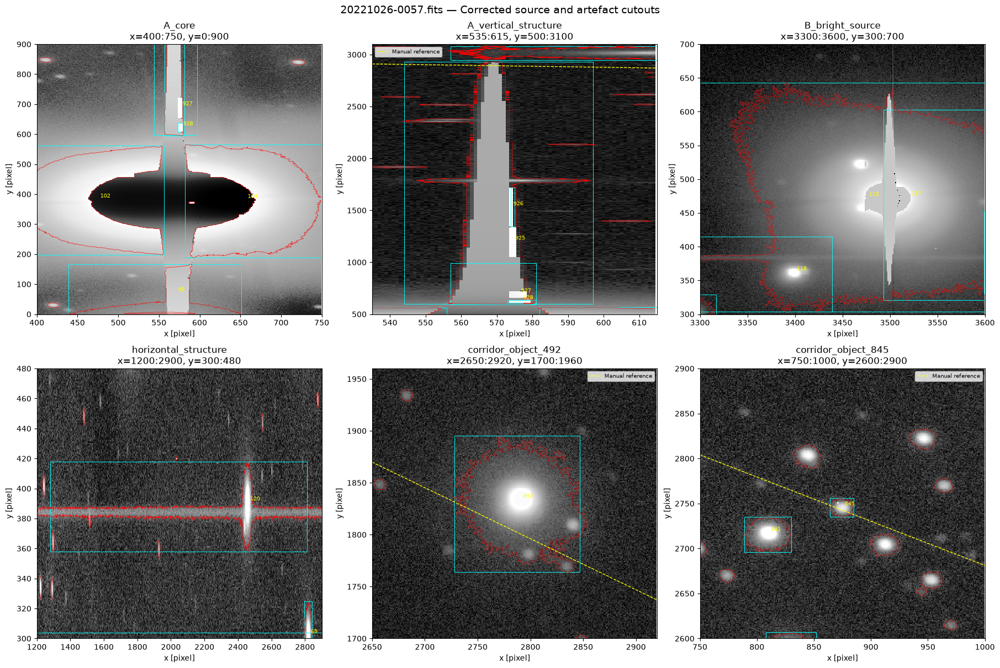

Saved: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/source_morphology_artefact_inventory_corrected.png
Memory: {'process_rss_gib': 1.935, 'available_ram_gib': 4.002}

STAGE 6.1 COMPLETE
------------------
Morphology catalogue: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/sep_source_morphology_inventory.csv
Linear candidates: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/sep_linear_structure_candidates.csv
Target intersections: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/sep_target_intersection_morphology.csv
Inspection figure: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/source_morphology_artefact_inventory_corrected.png

Memory: {'process_rss_gib': 1.935, 'available_ram_gib': 3.987}


In [23]:
# ============================================================
# CELL 17 — SOURCE MORPHOLOGY AND ARTEFACT INVENTORY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from matplotlib.colors import AsinhNorm
from matplotlib.patches import Rectangle

# ------------------------------------------------------------
# 1. Validate inputs
# ------------------------------------------------------------

required_columns = [
    "object_id", "x", "y", "a", "b", "theta",
    "npix", "xmin", "xmax", "ymin", "ymax",
    "peak", "flux", "flag"
]

missing = [
    c for c in required_columns
    if c not in source_catalogue.columns
]

if missing:
    raise RuntimeError(
        f"Source catalogue is missing columns: {missing}"
    )

if segmentation_map.shape != image_raw.shape:
    raise RuntimeError("Segmentation map shape mismatch.")


# ------------------------------------------------------------
# 2. Create morphology diagnostics
# ------------------------------------------------------------

morphology_catalogue = source_catalogue.copy()

morphology_catalogue["bbox_width_px"] = (
    morphology_catalogue["xmax"]
    - morphology_catalogue["xmin"] + 1
)

morphology_catalogue["bbox_height_px"] = (
    morphology_catalogue["ymax"]
    - morphology_catalogue["ymin"] + 1
)

bw = morphology_catalogue["bbox_width_px"].to_numpy(
    dtype=np.float64
)

bh = morphology_catalogue["bbox_height_px"].to_numpy(
    dtype=np.float64
)

a = morphology_catalogue["a"].to_numpy(
    dtype=np.float64
)

b = morphology_catalogue["b"].to_numpy(
    dtype=np.float64
)

morphology_catalogue["bbox_major_extent_px"] = np.maximum(
    bw, bh
)

morphology_catalogue["bbox_minor_extent_px"] = np.minimum(
    bw, bh
)

morphology_catalogue["bbox_aspect_ratio"] = (
    morphology_catalogue["bbox_major_extent_px"]
    / np.maximum(
        morphology_catalogue["bbox_minor_extent_px"],
        1
    )
)

morphology_catalogue["moment_aspect_ratio"] = (
    np.maximum(a, b) / np.maximum(np.minimum(a, b), 1e-6)
)

morphology_catalogue["theta_deg"] = (
    np.degrees(morphology_catalogue["theta"])
)


# ------------------------------------------------------------
# 3. Decode SEP extraction flags
# ------------------------------------------------------------

flag_values = morphology_catalogue["flag"].to_numpy(
    dtype=np.int32
)

merged_bit = int(sep.OBJ_MERGED)
truncated_bit = int(sep.OBJ_TRUNC)
overflow_bit = int(sep.OBJ_DOVERFLOW)
singular_bit = int(sep.OBJ_SINGU)

morphology_catalogue["flag_merged"] = (
    (flag_values & merged_bit) != 0
)

morphology_catalogue["flag_truncated"] = (
    (flag_values & truncated_bit) != 0
)

morphology_catalogue["flag_overflow"] = (
    (flag_values & overflow_bit) != 0
)

morphology_catalogue["flag_singular"] = (
    (flag_values & singular_bit) != 0
)


def decode_sep_flag(value):

    labels = []

    if int(value) & merged_bit:
        labels.append("MERGED")

    if int(value) & truncated_bit:
        labels.append("TRUNCATED")

    if int(value) & overflow_bit:
        labels.append("DEBLEND_OVERFLOW")

    if int(value) & singular_bit:
        labels.append("SINGULAR")

    return (
        "|".join(labels)
        if labels
        else "NONE"
    )


morphology_catalogue["flag_description"] = (
    morphology_catalogue["flag"].apply(decode_sep_flag)
)


# ------------------------------------------------------------
# 4. Preliminary morphology classes
# ------------------------------------------------------------

# These thresholds are deliberately broad screening criteria.
# They are not final physical classifications.

morphology_catalogue["compact_candidate"] = (

    morphology_catalogue["a"].between(1.5, 8.0)

    & morphology_catalogue["b"].between(1.5, 8.0)

    & (morphology_catalogue["moment_aspect_ratio"] < 2.0)

    & (morphology_catalogue["npix"].between(10, 1500))

    & (morphology_catalogue["flag"] == 0)
)


morphology_catalogue["extended_candidate"] = (

    (morphology_catalogue["npix"] >= 1000)

    | (morphology_catalogue["a"].clip(
        lower=morphology_catalogue["b"]
    ) >= 20)

)


morphology_catalogue["linear_candidate"] = (

    (
        (morphology_catalogue["bbox_aspect_ratio"] >= 8)
        & (morphology_catalogue["bbox_major_extent_px"] >= 50)
    )

    | (
        (morphology_catalogue["moment_aspect_ratio"] >= 10)
        & (morphology_catalogue["bbox_major_extent_px"] >= 30)
    )

)


print("MORPHOLOGY CLASS COUNTS")
print("-----------------------")

print(
    "Compact candidates:",
    int(morphology_catalogue["compact_candidate"].sum())
)

print(
    "Extended candidates:",
    int(morphology_catalogue["extended_candidate"].sum())
)

print(
    "Linear candidates:",
    int(morphology_catalogue["linear_candidate"].sum())
)


# ------------------------------------------------------------
# 5. Identify high-value and repeated-value pixels within
#    each segmentation component
# ------------------------------------------------------------

# These are diagnostic flags only. The >60000 threshold is
# NOT an established detector saturation threshold.

HIGH_PIXEL_THRESHOLD = 60000.0

object_pixel_diagnostics = []

for row in morphology_catalogue.itertuples():

    object_id = int(row.object_id)

    x0 = int(row.xmin)
    x1 = int(row.xmax) + 1

    y0 = int(row.ymin)
    y1 = int(row.ymax) + 1

    local_labels = segmentation_map[y0:y1, x0:x1]

    member_mask = (
        local_labels == object_id
    )

    local_image = image_raw[y0:y1, x0:x1]

    values = local_image[member_mask]

    if values.size == 0:
        continue

    n_high = int(
        np.count_nonzero(
            values >= HIGH_PIXEL_THRESHOLD
        )
    )

    n_repeated = int(
        np.count_nonzero(
            values == np.float32(SUSPECT_CONSTANT_VALUE)
        )
    )

    object_pixel_diagnostics.append({

        "object_id": object_id,

        "raw_peak": float(np.max(values)),

        "raw_minimum": float(np.min(values)),

        "pixels_ge_60000": n_high,

        "fraction_ge_60000": (
            n_high / values.size
        ),

        "repeated_value_pixels": n_repeated,

        "fraction_repeated_value": (
            n_repeated / values.size
        )

    })


object_pixel_diagnostics = pd.DataFrame(
    object_pixel_diagnostics
)

morphology_catalogue = morphology_catalogue.merge(
    object_pixel_diagnostics,
    on="object_id",
    how="left"
)


# ------------------------------------------------------------
# 6. Print the most elongated objects
# ------------------------------------------------------------

line_candidates = morphology_catalogue.loc[
    morphology_catalogue["linear_candidate"]
].copy()

line_candidates = line_candidates.sort_values(
    "moment_aspect_ratio",
    ascending=False
)

line_columns = [

    "object_id",

    "x", "y",

    "xmin", "xmax",

    "ymin", "ymax",

    "bbox_width_px",

    "bbox_height_px",

    "bbox_aspect_ratio",

    "a", "b",

    "moment_aspect_ratio",

    "theta_deg",

    "npix",

    "peak",

    "raw_peak",

    "flag",

    "flag_description"

]

print("\nTOP LINEAR-STRUCTURE CANDIDATES")
print("--------------------------------")

if line_candidates.empty:
    print("No candidates met the screening criteria.")

else:

    print(
        line_candidates[
            line_columns
        ].head(30).to_string(index=False)
    )


# ------------------------------------------------------------
# 7. Inspect extended sources
# ------------------------------------------------------------

extended_candidates = morphology_catalogue.loc[
    morphology_catalogue["extended_candidate"]
].sort_values(
    "npix",
    ascending=False
)

print("\nTOP EXTENDED OBJECTS")
print("--------------------")

print(
    extended_candidates[
        [
            "object_id",
            "x", "y",
            "npix",
            "a", "b",
            "moment_aspect_ratio",
            "flux",
            "peak",
            "raw_peak",
            "flag_description"
        ]
    ].head(25).to_string(index=False)
)


# ------------------------------------------------------------
# 8. Augment manual-corridor intersection catalogue
# ------------------------------------------------------------

target_morphology = target_intersection_df[
    [
        "object_id",
        "target_samples_intersected",
        "along_track_start_px",
        "along_track_end_px"
    ]
].merge(

    morphology_catalogue,

    on="object_id",

    how="left"

).sort_values(
    "target_samples_intersected",
    ascending=False
)

print("\nANNOTATION-INTERSECTING OBJECTS — MORPHOLOGY")
print("--------------------------------------------")

intersection_columns = [

    "object_id",

    "target_samples_intersected",

    "along_track_start_px",

    "along_track_end_px",

    "x", "y",

    "npix",

    "a", "b",

    "bbox_aspect_ratio",

    "moment_aspect_ratio",

    "theta_deg",

    "linear_candidate",

    "compact_candidate",

    "extended_candidate",

    "flag_description"

]

print(
    target_morphology[
        intersection_columns
    ].to_string(index=False)
)


# ============================================================
# 9 — CORRECTED NATIVE-REGION MORPHOLOGY INSPECTION
# ============================================================


INSPECTION_REGIONS = {

    "A_core": (400, 750, 0, 900),

    "A_vertical_structure": (535, 615, 500, 3100),

    "B_bright_source": (3300, 3600, 300, 700),

    "horizontal_structure": (1200, 2900, 300, 480),

    "corridor_object_492": (2650, 2920, 1700, 1960),

    "corridor_object_845": (750, 1000, 2600, 2900)

}


def clip_segment_to_rectangle(p0, p1, bounds):
    """
    Clip a line segment to a rectangular crop.

    bounds = (x0, x1, y0, y1)
    Returns clipped endpoints or None.
    """

    x0, x1, y0, y1 = bounds

    start = np.asarray(p0, dtype=float)
    end = np.asarray(p1, dtype=float)

    dx, dy = end - start

    t0, t1 = 0.0, 1.0

    tests = [
        (-dx, start[0] - x0),
        ( dx, x1 - start[0]),
        (-dy, start[1] - y0),
        ( dy, y1 - start[1])
    ]

    for p, q in tests:

        if abs(p) < 1e-12:

            if q < 0:
                return None

            continue

        r = q / p

        if p < 0:
            t0 = max(t0, r)
        else:
            t1 = min(t1, r)

        if t0 > t1:
            return None

    return (
        start + t0 * (end - start),
        start + t1 * (end - start)
    )


fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 12),
    constrained_layout=True
)

# Objects worth displaying as bounding boxes.
important_ids = {
    925, 926, 927, 928,
    115, 117, 118, 119,
    120, 492, 845
}

for ax, (name, bounds) in zip(
    axes.flat,
    INSPECTION_REGIONS.items()
):

    x0, x1, y0, y1 = bounds

    crop = residual_128[y0:y1, x0:x1]

    seg_crop = segmentation_map[y0:y1, x0:x1]

    # --------------------------------------------------------
    # Display stretch: robust asinh scaling
    # --------------------------------------------------------

    finite_values = crop[np.isfinite(crop)]

    vmin = float(np.percentile(finite_values, 1))
    vmax = float(np.percentile(finite_values, 99.8))

    if vmax <= vmin:
        vmax = vmin + 1.0

    norm = AsinhNorm(
        linear_width=max(raw_robust_sigma, 1.0),
        vmin=vmin,
        vmax=vmax
    )

    ax.imshow(
        crop,
        origin="lower",
        cmap="gray",
        norm=norm,
        extent=(x0 - 0.5, x1 - 0.5, y0 - 0.5, y1 - 0.5),
        interpolation="nearest",
        aspect="auto"
    )

    # --------------------------------------------------------
    # SEGMENTATION BOUNDARIES
    # --------------------------------------------------------

    if np.any(seg_crop > 0):

        ax.contour(
            seg_crop > 0,
            levels=[0.5],
            colors="red",
            linewidths=0.45,
            origin="lower",
            extent=(x0 - 0.5, x1 - 0.5, y0 - 0.5, y1 - 0.5)
        )

    # --------------------------------------------------------
    # RELEVANT OBJECT BOUNDING BOXES AND LABELS
    # --------------------------------------------------------

    region_objects = morphology_catalogue.loc[

        (morphology_catalogue["xmax"] >= x0)
        & (morphology_catalogue["xmin"] <= x1)
        & (morphology_catalogue["ymax"] >= y0)
        & (morphology_catalogue["ymin"] <= y1)

    ].copy()

    region_objects = region_objects.loc[
        region_objects["object_id"].isin(important_ids)
        | (region_objects["npix"] >= 1000)
        | region_objects["linear_candidate"]
    ]

    region_objects = region_objects.head(25)

    for row in region_objects.itertuples():

        # Bounding box, clipped visually to the crop.
        bx0 = max(float(row.xmin), x0)
        bx1 = min(float(row.xmax + 1), x1)

        by0 = max(float(row.ymin), y0)
        by1 = min(float(row.ymax + 1), y1)

        if bx1 <= bx0 or by1 <= by0:
            continue

        rect = Rectangle(
            (bx0, by0),
            bx1 - bx0,
            by1 - by0,
            fill=False,
            edgecolor="cyan",
            linewidth=0.7
        )

        ax.add_patch(rect)

        # Label only when the centroid lies inside the crop.
        if (
            x0 <= row.x <= x1
            and y0 <= row.y <= y1
        ):

            ax.annotate(
                str(int(row.object_id)),
                (row.x, row.y),
                xytext=(3, 3),
                textcoords="offset points",
                fontsize=7,
                color="yellow"
            )

    # --------------------------------------------------------
    # MANUAL LINE — DRAW ONLY IF IT INTERSECTS THIS CROP
    # --------------------------------------------------------

    clipped_line = clip_segment_to_rectangle(
        visible_start,
        visible_end,
        bounds
    )

    if clipped_line is not None:

        p0, p1 = clipped_line

        ax.plot(
            [p0[0], p1[0]],
            [p0[1], p1[1]],
            color="yellow",
            linestyle="--",
            linewidth=1.0,
            label="Manual reference"
        )

        ax.legend(
            loc="best",
            fontsize=7
        )

    # --------------------------------------------------------
    # CRITICAL FIX: enforce the actual crop limits last
    # --------------------------------------------------------

    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)

    ax.set_title(
        f"{name}\nx={x0}:{x1}, y={y0}:{y1}"
    )

    ax.set_xlabel("x [pixel]")
    ax.set_ylabel("y [pixel]")


fig.suptitle(
    f"{FRAME_FILENAME} — Corrected source and artefact cutouts",
    fontsize=14
)

CORRECTED_MORPHOLOGY_FIGURE = (
    FRAME_OUTPUT_DIR /
    "source_morphology_artefact_inventory_corrected.png"
)

fig.savefig(
    CORRECTED_MORPHOLOGY_FIGURE,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", CORRECTED_MORPHOLOGY_FIGURE)
print("Memory:", memory_report())


# ------------------------------------------------------------
# 10. Save all morphology diagnostics
# ------------------------------------------------------------

MORPHOLOGY_CATALOGUE_PATH = (
    FRAME_OUTPUT_DIR /
    "sep_source_morphology_inventory.csv"
)

morphology_catalogue.to_csv(
    MORPHOLOGY_CATALOGUE_PATH,
    index=False
)

LINEAR_CANDIDATES_PATH = (
    FRAME_OUTPUT_DIR /
    "sep_linear_structure_candidates.csv"
)

line_candidates.to_csv(
    LINEAR_CANDIDATES_PATH,
    index=False
)

TARGET_MORPHOLOGY_PATH = (
    FRAME_OUTPUT_DIR /
    "sep_target_intersection_morphology.csv"
)

target_morphology.to_csv(
    TARGET_MORPHOLOGY_PATH,
    index=False
)


print("\nSTAGE 6.1 COMPLETE")
print("------------------")

print("Morphology catalogue:", MORPHOLOGY_CATALOGUE_PATH)

print("Linear candidates:", LINEAR_CANDIDATES_PATH)

print("Target intersections:", TARGET_MORPHOLOGY_PATH)

print("Inspection figure:", CORRECTED_MORPHOLOGY_FIGURE)

print("\nMemory:", memory_report())

**What the six panels reveal**

* A. Source A: a complex bright-source region
The first panel shows a bright extended halo surrounding a dark central region, with a narrow vertical structure running through it. This is not a normal isolated stellar profile. It is a complicated mixture of bright-source signal and instrumental-looking structure. The vertical component continues far beyond the immediate source. The second panel makes this particularly clear.

Our preliminary classification: source-associated vertical artefact candidate, with possible bright-core and halo contamination. Its physical origin is still unverified.

* B. The vertical structure near (x=approx 574)
The second panel shows the components identified as objects 925–928. They occupy different vertical intervals, but are aligned around approximately the same x-coordinate. We should investigate them as a possible common structure rather than treating every SEP object as an independent star.

One important geometric fact:

The manually annotated diagonal intersects the upper end of object 925 near s=a pprox620 pixels. The rest of the vertical feature does not lie along the target; it is approximately perpendicular to it.

This is a local contamination problem near the target's endpoint, not evidence that the entire annotated diagonal is contaminated.

* C. Source B: a bright, complicated structure
The third panel shows a broad halo, a bright central region and a very narrow vertical feature. Object 115 has a particularly large bounding box, reaching the right image boundary. Its moment aspect ratio is only about 2.04, however.

That discrepancy matters: its large bounding-box aspect ratio does not mean that the underlying object is one thin, straight feature. It is likely a complex, extended segmentation component, potentially connected through other structures.

* D. The horizontal feature: our next major investigation

The fourth panel is particularly interesting.

Object 120 occupies:
- x = 1279–2812
- y = 358–417
- 12,452 segmented pixels
- Moment major axis = 274.16 px
- Moment minor axis = 5.83 px
- Major/minor ratio ≈ 47

The narrow horizontal structure is visible across the crop, with several bright vertical intersections.This is an important potential false-positive source for FRT. However, we cannot yet call it a defective CCD row. It is a 1,534-pixel-wide connected component in this detection, not a demonstrated full-frame row defect.

It needs a profile and continuity analysis.

* E. Objects intersecting the diagonal

The last two panels show why source removal must be conservative. Object 492 is a bright extended source whose halo overlaps the manual corridor. Object 845 is much more compact and resembles an ordinary stellar detection.

Both can contaminate the target measurement, but they require different treatments.

### Detailed segmentation geometry

SEGMENTATION INVESTIGATION
--------------------------
{'group': 'horizontal_object_120', 'available_ids': [120], 'missing_ids': []}
{'group': 'source_A_vertical_family', 'available_ids': [925, 926, 927, 928], 'missing_ids': []}
{'group': 'source_B_complex', 'available_ids': [115, 117, 118, 119], 'missing_ids': []}
{'group': 'target_source_492', 'available_ids': [492], 'missing_ids': []}
{'group': 'target_source_845', 'available_ids': [845], 'missing_ids': []}

DETAILED SEGMENTATION GEOMETRY
------------------------------

 horizontal_object_120
group                                           : horizontal_object_120
object_ids                                      : [120]
major_axis                                      : x
pixel_count                                     : 12452
bbox_xmin                                       : 1279
bbox_xmax                                       : 2812
bbox_ymin                                       : 358
bbox_ymax                                       :

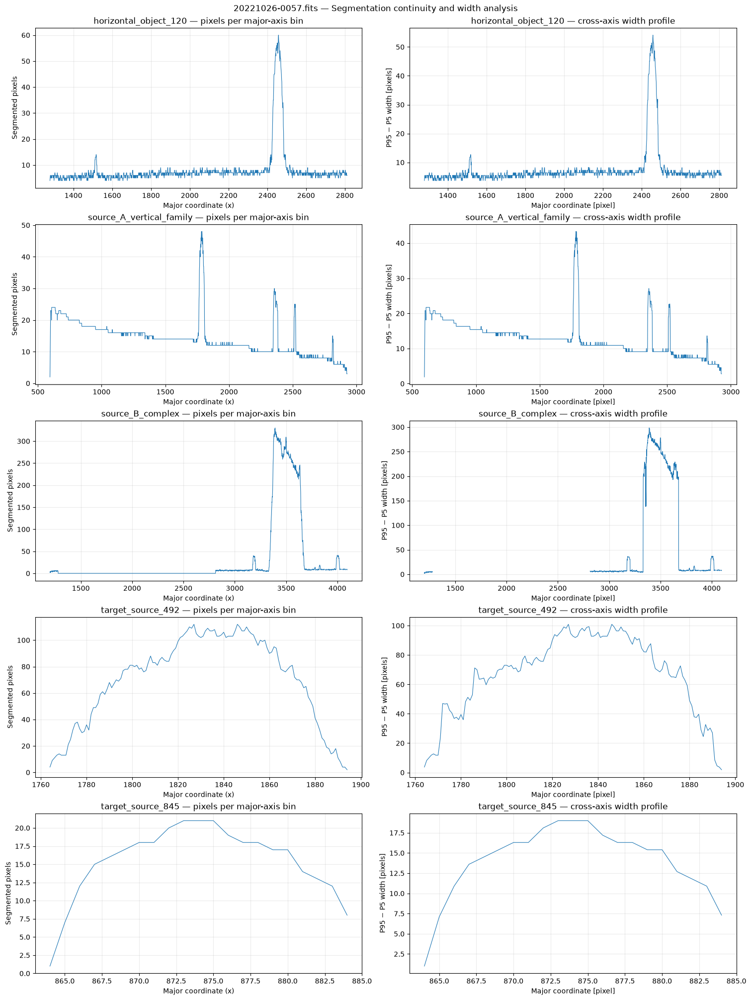

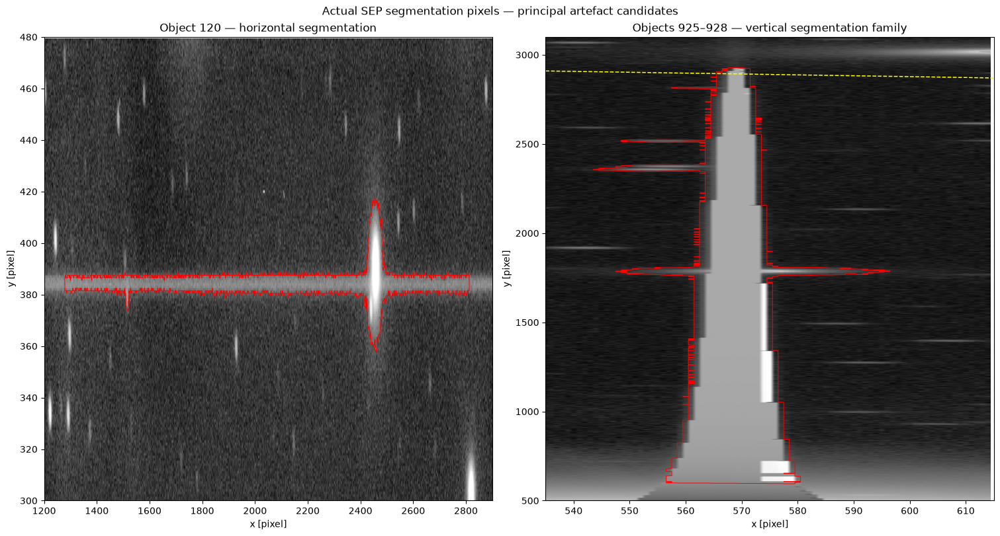


STAGE 6.2 COMPLETE
------------------
Geometry CSV: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/segmentation_geometry_inventory.csv
Geometry JSON: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/segmentation_geometry_inventory.json
Profiles: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/segmentation_geometry_profiles.png
Principal masks: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/principal_linear_component_masks.png

Memory: {'process_rss_gib': 2.001, 'available_ram_gib': 4.13}


In [24]:
# ============================================================
# CELL 18 — DETAILED GEOMETRY OF SOURCE/ARTEFACT CANDIDATES
#
# No image modification.
# No masking.
# No source subtraction.
#
# Measurements are based on actual SEP segmentation pixels.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from matplotlib.colors import AsinhNorm
from scipy import ndimage as ndi


# ------------------------------------------------------------
# 1. Objects and groups to investigate
# ------------------------------------------------------------

INVESTIGATION_GROUPS = {

    "horizontal_object_120": [120],

    "source_A_vertical_family": [925, 926, 927, 928],

    "source_B_complex": [115, 117, 118, 119],

    "target_source_492": [492],

    "target_source_845": [845]

}

available_ids = set(
    morphology_catalogue["object_id"].astype(int)
)

print("SEGMENTATION INVESTIGATION")
print("--------------------------")

for name, object_ids in INVESTIGATION_GROUPS.items():

    present = [
        oid for oid in object_ids
        if oid in available_ids
    ]

    missing = [
        oid for oid in object_ids
        if oid not in available_ids
    ]

    print({
        "group": name,
        "available_ids": present,
        "missing_ids": missing
    })


# ------------------------------------------------------------
# 2. Create a target-corridor sampling grid
# ------------------------------------------------------------

u_core_18 = u[core_mask_1d]

X_target_18 = (
    visible_start[0]
    + s[:, None] * direction[0]
    + u_core_18[None, :] * normal[0]
)

Y_target_18 = (
    visible_start[1]
    + s[:, None] * direction[1]
    + u_core_18[None, :] * normal[1]
)

target_labels_18 = ndi.map_coordinates(
    segmentation_map,
    [
        Y_target_18.ravel(),
        X_target_18.ravel()
    ],
    order=0,
    mode="constant",
    cval=0
).astype(np.int32).reshape(X_target_18.shape)


# ------------------------------------------------------------
# 3. Geometry measurement helper
# ------------------------------------------------------------

def measure_segmentation_geometry(
    object_ids,
    group_name
):

    object_ids = [
        int(oid)
        for oid in object_ids
        if oid in available_ids
    ]

    if not object_ids:
        return None, None

    # SEP segmentation labels correspond to object catalogue
    # indices + 1. The source object_id values are those IDs.
    mask = np.isin(
        segmentation_map,
        object_ids
    )

    yy, xx = np.nonzero(mask)

    if len(xx) == 0:
        return None, None

    # Actual pixel boundaries.
    xmin = int(xx.min())
    xmax = int(xx.max())

    ymin = int(yy.min())
    ymax = int(yy.max())

    bbox_width = xmax - xmin + 1
    bbox_height = ymax - ymin + 1

    # Determine the dominant direction from actual pixels.
    major_axis = (
        "x"
        if bbox_width >= bbox_height
        else "y"
    )

    if major_axis == "x":

        major_coordinates = xx
        minor_coordinates = yy

        major_min = xmin
        major_max = xmax

    else:

        major_coordinates = yy
        minor_coordinates = xx

        major_min = ymin
        major_max = ymax

    # --------------------------------------------------------
    # Profile along the major direction
    # --------------------------------------------------------

    major_bins = np.arange(
        major_min,
        major_max + 1
    )

    occupancy = np.zeros(
        len(major_bins),
        dtype=np.int32
    )

    minor_center = np.full(
        len(major_bins),
        np.nan
    )

    minor_width = np.full(
        len(major_bins),
        np.nan
    )

    for i, coordinate in enumerate(major_bins):

        values = minor_coordinates[
            major_coordinates == coordinate
        ]

        if values.size == 0:
            continue

        occupancy[i] = len(values)

        minor_center[i] = float(
            np.median(values)
        )

        minor_width[i] = float(
            np.percentile(values, 95)
            - np.percentile(values, 5)
            + 1
        )

    occupied_bins = occupancy > 0

    coverage = float(
        occupied_bins.mean()
    )

    valid_major = major_bins[occupied_bins]

    valid_centres = minor_center[occupied_bins]

    # --------------------------------------------------------
    # Linear-fit diagnostic
    # --------------------------------------------------------

    if len(valid_major) >= 2:

        coefficients = np.polyfit(
            valid_major,
            valid_centres,
            deg=1
        )

        fitted_centres = np.polyval(
            coefficients,
            valid_major
        )

        fit_residuals = (
            valid_centres - fitted_centres
        )

        fit_rms = float(
            np.sqrt(np.mean(fit_residuals**2))
        )

        fit_mad = float(
            1.4826022185
            * np.median(
                np.abs(
                    fit_residuals
                    - np.median(fit_residuals)
                )
            )
        )

        slope = float(coefficients[0])

        angle_deg = float(
            np.degrees(
                np.arctan2(
                    slope,
                    1.0
                )
            )
        )

    else:

        slope = np.nan
        angle_deg = np.nan
        fit_rms = np.nan
        fit_mad = np.nan

    valid_widths = minor_width[
        np.isfinite(minor_width)
    ]

    # --------------------------------------------------------
    # Pixel-value diagnostics
    # --------------------------------------------------------

    raw_values = image_raw[mask]

    n_pixels = int(len(raw_values))

    repeated_count = int(
        np.count_nonzero(
            raw_values == np.float32(SUSPECT_CONSTANT_VALUE)
        )
    )

    high_count = int(
        np.count_nonzero(
            raw_values >= HIGH_PIXEL_THRESHOLD
        )
    )

    # --------------------------------------------------------
    # Annotation intersection
    # --------------------------------------------------------

    target_intersections = np.isin(
        target_labels_18,
        object_ids
    )

    intersection_count = int(
        target_intersections.sum()
    )

    # Number of along-track positions where at least one
    # sample intersects the object's segmentation.
    intersected_positions = int(
        target_intersections.any(axis=1).sum()
    )

    total_along_track = len(s)

    # --------------------------------------------------------
    # Summary
    # --------------------------------------------------------

    summary = {

        "group": group_name,

        "object_ids": object_ids,

        "major_axis": major_axis,

        "pixel_count": n_pixels,

        "bbox_xmin": xmin,

        "bbox_xmax": xmax,

        "bbox_ymin": ymin,

        "bbox_ymax": ymax,

        "bbox_width": bbox_width,

        "bbox_height": bbox_height,

        "bbox_area": bbox_width * bbox_height,

        "bbox_fill_fraction": float(
            n_pixels / (bbox_width * bbox_height)
        ),

        "major_axis_coverage": coverage,

        "occupied_major_bins": int(
            occupied_bins.sum()
        ),

        "total_major_bins": int(
            len(major_bins)
        ),

        "median_pixels_per_occupied_bin": float(
            np.median(occupancy[occupied_bins])
        ),

        "maximum_pixels_per_bin": int(
            occupancy.max()
        ),

        "median_cross_axis_width_px": (
            float(np.nanmedian(valid_widths))
            if valid_widths.size else np.nan
        ),

        "p90_cross_axis_width_px": (
            float(np.nanpercentile(valid_widths, 90))
            if valid_widths.size else np.nan
        ),

        "fitted_slope": slope,

        "fitted_angle_deg": angle_deg,

        "centreline_fit_rms_px": fit_rms,

        "centreline_fit_robust_sigma_px": fit_mad,

        "raw_peak": float(raw_values.max()),

        "raw_median": float(np.median(raw_values)),

        "pixels_ge_60000": high_count,

        "fraction_ge_60000": float(
            high_count / n_pixels
        ),

        "repeated_value_pixels": repeated_count,

        "fraction_repeated_value": float(
            repeated_count / n_pixels
        ),

        "target_corridor_intersection_samples": intersection_count,

        "target_corridor_intersected_positions": intersected_positions,

        "fraction_of_along_track_positions_intersected": float(
            intersected_positions / total_along_track
        )

    }

    profiles = {

        "major_bins": major_bins,

        "occupancy": occupancy,

        "minor_center": minor_center,

        "minor_width": minor_width,

        "mask": mask

    }

    return summary, profiles


# ------------------------------------------------------------
# 4. Analyse all groups
# ------------------------------------------------------------

GEOMETRY_SUMMARIES = {}

GEOMETRY_PROFILES = {}

for name, object_ids in INVESTIGATION_GROUPS.items():

    summary, profiles = measure_segmentation_geometry(
        object_ids,
        name
    )

    if summary is None:

        print(
            f"WARNING: No segmentation pixels found for {name}"
        )

        continue

    GEOMETRY_SUMMARIES[name] = summary

    GEOMETRY_PROFILES[name] = profiles


# ------------------------------------------------------------
# 5. Print results
# ------------------------------------------------------------

print("\nDETAILED SEGMENTATION GEOMETRY")
print("------------------------------")

for name, summary in GEOMETRY_SUMMARIES.items():

    print("\n", name)

    for key, value in summary.items():

        print(f"{key:48s}: {value}")


# ------------------------------------------------------------
# 6. Create a compact results table
# ------------------------------------------------------------

geometry_df = pd.DataFrame.from_dict(
    GEOMETRY_SUMMARIES,
    orient="index"
)

geometry_df.index.name = "group"

display_columns = [

    "object_ids",

    "major_axis",

    "pixel_count",

    "bbox_width",

    "bbox_height",

    "bbox_fill_fraction",

    "major_axis_coverage",

    "median_cross_axis_width_px",

    "centreline_fit_rms_px",

    "fraction_repeated_value",

    "fraction_ge_60000",

    "target_corridor_intersection_samples",

    "fraction_of_along_track_positions_intersected"

]

print("\nCOMPARISON TABLE")
print("----------------")

print(
    geometry_df[
        display_columns
    ].to_string()
)


# ------------------------------------------------------------
# 7. Plot occupancy profiles
# ------------------------------------------------------------

profile_names = [
    name
    for name in GEOMETRY_PROFILES
]

fig, axes = plt.subplots(
    len(profile_names),
    2,
    figsize=(15, 4 * len(profile_names)),
    squeeze=False,
    constrained_layout=True
)

for row_index, name in enumerate(profile_names):

    profile = GEOMETRY_PROFILES[name]

    bins = profile["major_bins"]

    occupancy = profile["occupancy"]

    width = profile["minor_width"]

    axes[row_index, 0].plot(
        bins,
        occupancy,
        linewidth=0.8
    )

    axes[row_index, 0].set_title(
        f"{name} — pixels per major-axis bin"
    )

    axes[row_index, 0].set_xlabel(
        f"Major coordinate ({'x' if profile_names else 'axis'})"
    )

    axes[row_index, 0].set_ylabel(
        "Segmented pixels"
    )

    axes[row_index, 0].grid(alpha=0.25)


    axes[row_index, 1].plot(
        bins,
        width,
        linewidth=0.8
    )

    axes[row_index, 1].set_title(
        f"{name} — cross-axis width profile"
    )

    axes[row_index, 1].set_xlabel(
        "Major coordinate [pixel]"
    )

    axes[row_index, 1].set_ylabel(
        "P95 − P5 width [pixels]"
    )

    axes[row_index, 1].grid(alpha=0.25)


fig.suptitle(
    f"{FRAME_FILENAME} — Segmentation continuity and width analysis"
)

GEOMETRY_PROFILE_FIGURE = (
    FRAME_OUTPUT_DIR /
    "segmentation_geometry_profiles.png"
)

fig.savefig(
    GEOMETRY_PROFILE_FIGURE,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 8. Plot actual segmentation masks for the principal
#    horizontal and vertical structures
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 8),
    constrained_layout=True
)

# Horizontal region.
horizontal_bounds = (
    1200, 2900,
    300, 480
)

x0, x1, y0, y1 = horizontal_bounds

crop = residual_128[y0:y1, x0:x1]

horizontal_mask = GEOMETRY_PROFILES[
    "horizontal_object_120"
]["mask"][y0:y1, x0:x1]

values = crop[np.isfinite(crop)]

norm = AsinhNorm(
    linear_width=max(raw_robust_sigma, 1.0),
    vmin=float(np.percentile(values, 1)),
    vmax=float(np.percentile(values, 99.8))
)

axes[0].imshow(
    crop,
    origin="lower",
    cmap="gray",
    norm=norm,
    extent=(x0 - 0.5, x1 - 0.5, y0 - 0.5, y1 - 0.5),
    aspect="auto"
)

axes[0].contour(
    horizontal_mask,
    levels=[0.5],
    colors="red",
    linewidths=0.7,
    origin="lower",
    extent=(x0 - 0.5, x1 - 0.5, y0 - 0.5, y1 - 0.5)
)

axes[0].set_xlim(x0, x1)
axes[0].set_ylim(y0, y1)

axes[0].set_title(
    "Object 120 — horizontal segmentation"
)

axes[0].set_xlabel("x [pixel]")
axes[0].set_ylabel("y [pixel]")


# Vertical family.
vertical_bounds = (
    535, 615,
    500, 3100
)

x0, x1, y0, y1 = vertical_bounds

crop = residual_128[y0:y1, x0:x1]

vertical_mask = GEOMETRY_PROFILES[
    "source_A_vertical_family"
]["mask"][y0:y1, x0:x1]

values = crop[np.isfinite(crop)]

norm = AsinhNorm(
    linear_width=max(raw_robust_sigma, 1.0),
    vmin=float(np.percentile(values, 1)),
    vmax=float(np.percentile(values, 99.8))
)

axes[1].imshow(
    crop,
    origin="lower",
    cmap="gray",
    norm=norm,
    extent=(x0 - 0.5, x1 - 0.5, y0 - 0.5, y1 - 0.5),
    aspect="auto"
)

axes[1].contour(
    vertical_mask,
    levels=[0.5],
    colors="red",
    linewidths=0.7,
    origin="lower",
    extent=(x0 - 0.5, x1 - 0.5, y0 - 0.5, y1 - 0.5)
)

# Manual centreline, clipped only for the displayed region.
clipped_vertical = clip_segment_to_rectangle(
    visible_start,
    visible_end,
    vertical_bounds
)

if clipped_vertical is not None:

    p0, p1 = clipped_vertical

    axes[1].plot(
        [p0[0], p1[0]],
        [p0[1], p1[1]],
        color="yellow",
        linestyle="--",
        linewidth=1.1
    )

axes[1].set_xlim(x0, x1)
axes[1].set_ylim(y0, y1)

axes[1].set_title(
    "Objects 925–928 — vertical segmentation family"
)

axes[1].set_xlabel("x [pixel]")
axes[1].set_ylabel("y [pixel]")


fig.suptitle(
    "Actual SEP segmentation pixels — principal artefact candidates"
)

GEOMETRY_MASK_FIGURE = (
    FRAME_OUTPUT_DIR /
    "principal_linear_component_masks.png"
)

fig.savefig(
    GEOMETRY_MASK_FIGURE,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 9. Save the geometry report
# ------------------------------------------------------------

GEOMETRY_CATALOGUE_PATH = (
    FRAME_OUTPUT_DIR /
    "segmentation_geometry_inventory.csv"
)

geometry_df.to_csv(
    GEOMETRY_CATALOGUE_PATH
)

GEOMETRY_JSON_PATH = (
    FRAME_OUTPUT_DIR /
    "segmentation_geometry_inventory.json"
)

GEOMETRY_JSON_PATH.write_text(
    json.dumps(
        GEOMETRY_SUMMARIES,
        indent=2
    ),
    encoding="utf-8"
)

print("\nSTAGE 6.2 COMPLETE")
print("------------------")

print("Geometry CSV:", GEOMETRY_CATALOGUE_PATH)

print("Geometry JSON:", GEOMETRY_JSON_PATH)

print("Profiles:", GEOMETRY_PROFILE_FIGURE)

print("Principal masks:", GEOMETRY_MASK_FIGURE)

print("\nMemory:", memory_report())

**How to interpret the output**

Three measurements will be especially important.

* Major-axis coverage: What fraction of positions along the object's longest dimension contain at least one segmented pixel? A high value suggests continuity, but does not prove that the structure is an instrumental defect.

* Cross-axis width: How does the perpendicular width change along the structure? A genuinely narrow, consistent linear feature should generally have a more stable width than a diffuse, complicated source region.

* Centreline-fit residual: How closely does the measured centre of the structure follow a straight line? A small residual indicates geometric straightness, not physical origin.

We also measure the fraction of repeated-value pixels and the overlap with the target corridor.

**After this review — we have identified two strong linear-contamination candidates
These measurements are useful. They help distinguish actual elongated structures from ordinary bright sources, and they tell us where the manual trail is at risk of contamination.**

1. Object 120 — the horizontal structure: The profile plot is particularly informative. The structure is present across all 1,534 columns, with a relatively stable width. The sharp peak around x=2450–2500 is likely caused by a bright source intersecting the feature, rather than a sudden intrinsic increase in the width of the entire horizontal structure. This is consistent with a narrow horizontal linear feature.

2. Source A — the vertical structure is strongly associated with the repeated-value region: Nearly 70% of the pixels assigned to this vertical family have exactly the suspicious value 2650.0813. This makes the structure very different from an ordinary stellar trail. It is strongly consistent with a digitally uniform or clipped/replaced region associated with source A, although we still cannot determine the processing history or physical cause.The manual annotation intersects this group at only five along-track positions. That means the vertical feature is an important local contamination issue, but it does not explain the positive target signal over the full 4,552-pixel length

...and many more

### Test whether these structures are genuine linear excesses: Horizontal and vertical artefact profile validation

Before we move to PSF calibration, I want one more controlled experiment.

We need to answer two questions:
1. Is object 120 a coherent horizontal signal above its neighbouring rows?
2. Is the source-A vertical family a coherent vertical signal, or is its apparent continuity largely produced by the repeated-value plateau?
We should also correct the way we describe segmentation width. The 6.4 px and 12.7 px measurements are widths of threshold-selected segmentation pixels, not FWHM measurements. They depend on SEP's detection threshold, local RMS and deblending. They cannot be compared directly with the telescope PSF FWHM.


HORIZONTAL_120
name                                      : horizontal_120
object_ids                                : [120]
major_axis                                : x
pixels                                    : 12452
major_axis_coverage                       : 1.0
median_segmented_width_px                 : 6.399999999999977
p90_segmented_width_px                    : 7.2999999999999545
centreline_fit_rms_px                     : 0.8839643925655799
fitted_angle_deg                          : 0.006330005159462967
target_median_residual_contrast           : 62.33733654022217
median_parallel_control_contrast          : -1.0177183151245117
median_target_minus_control               : 63.412964820861816
fraction_target_above_control             : 1.0

CONTROL PROFILES
-80.0 {'median_residual_contrast': -0.3366727828979492, 'p10_residual_contrast': -11.557924079895018, 'p90_residual_contrast': 12.257274436950684, 'positive_fraction': 0.4830508474576271, 'valid_fraction': 1.0}
-40.0 {'medi

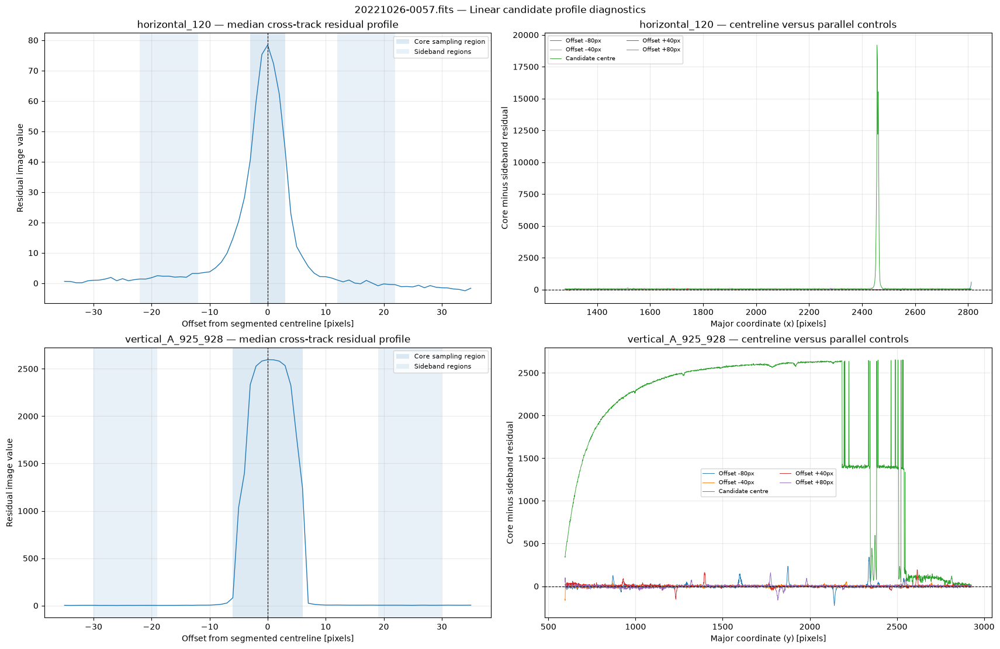


STAGE 6.3 DIAGNOSTIC COMPLETE
-----------------------------
Profile figure: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/linear_candidate_profile_validation.png
Profile summary: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/linear_candidate_profile_summary.json
Source-B individual components: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/source_B_individual_component_geometry.csv

Memory: {'process_rss_gib': 2.031, 'available_ram_gib': 3.98}


32477

In [25]:
# ============================================================
# CELL 19 — LINEAR CANDIDATE INTENSITY PROFILE VALIDATION
#
# Horizontal candidate: object 120
# Vertical candidate: objects 925–928
#
# Includes:
#   - Individual geometry for source-B components
#   - Centreline and width from segmentation pixels
#   - Raw and residual cross-track profiles
#   - Parallel control strips
#   - Along-axis continuity diagnostics
#
# No masking or image modification.
# This cell uses the actual segmentation pixels to estimate a centreline, samples the original and background-subtracted images around it
# Compares the candidate against parallel control strips.

# For object 115, 117, 118 and 119, it calculates individual geometry rather than combining them into one artificial structure.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import gc

from scipy import ndimage as ndi


# ------------------------------------------------------------
# 1. Validate inputs
# ------------------------------------------------------------

required_variables = [
    "image_raw",
    "residual_128",
    "segmentation_map",
    "morphology_catalogue",
    "FRAME_OUTPUT_DIR"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Missing notebook variables: {missing_variables}"
    )

if not (
    image_raw.shape
    == residual_128.shape
    == segmentation_map.shape
):
    raise RuntimeError("Image and segmentation dimensions differ.")


# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

LINEAR_CANDIDATES = {

    "horizontal_120": {
        "object_ids": [120],
        "major_axis": "x",
        "core_halfwidth": 3.0,
        "sideband_inner": 12.0,
        "sideband_outer": 22.0
    },

    "vertical_A_925_928": {
        "object_ids": [925, 926, 927, 928],
        "major_axis": "y",
        "core_halfwidth": 6.0,
        "sideband_inner": 19.0,
        "sideband_outer": 30.0
    }

}

PARALLEL_CONTROL_OFFSETS = [
    -80.0,
    -40.0,
    0.0,
    40.0,
    80.0
]

CROSS_SAMPLE_STEP = 1.0

# Do not change these values to force a desired result.
# They are diagnostic sampling settings, not final apertures.


# ------------------------------------------------------------
# 3. Helper — retrieve segmentation pixels
# ------------------------------------------------------------

def retrieve_component_pixels(object_ids):

    object_ids = np.asarray(
        object_ids,
        dtype=np.int32
    )

    mask = np.isin(
        segmentation_map,
        object_ids
    )

    yy, xx = np.nonzero(mask)

    if xx.size == 0:
        raise RuntimeError(
            f"No segmentation pixels found for IDs {object_ids.tolist()}."
        )

    return mask, xx, yy


# ------------------------------------------------------------
# 4. Helper — derive the segmented centreline
# ------------------------------------------------------------

def derive_component_centreline(
    xx,
    yy,
    major_axis
):

    if major_axis == "x":

        major = xx
        minor = yy

    elif major_axis == "y":

        major = yy
        minor = xx

    else:
        raise ValueError("major_axis must be 'x' or 'y'.")

    major_min = int(major.min())
    major_max = int(major.max())

    bins = np.arange(
        major_min,
        major_max + 1,
        dtype=np.int32
    )

    centre = np.full(
        bins.size,
        np.nan,
        dtype=np.float64
    )

    width = np.full(
        bins.size,
        np.nan,
        dtype=np.float64
    )

    occupancy = np.zeros(
        bins.size,
        dtype=np.int32
    )

    # Sort once, then process each major-axis coordinate.
    order = np.argsort(major)

    major_sorted = major[order]
    minor_sorted = minor[order]

    unique_major, starts, counts = np.unique(
        major_sorted,
        return_index=True,
        return_counts=True
    )

    for coordinate, start, count in zip(
        unique_major,
        starts,
        counts
    ):

        values = minor_sorted[
            start:start + count
        ]

        idx = int(coordinate - major_min)

        centre[idx] = float(
            np.median(values)
        )

        width[idx] = float(
            np.percentile(values, 95)
            - np.percentile(values, 5)
            + 1.0
        )

        occupancy[idx] = int(count)

    valid = np.isfinite(centre)

    # Interpolate only missing positions between observed
    # segmented positions. Do not extrapolate beyond them.
    if valid.sum() < 2:
        raise RuntimeError("Insufficient centreline samples.")

    centre_interpolated = np.interp(
        bins,
        bins[valid],
        centre[valid]
    )

    # Line fit is a geometric diagnostic, not a classification.
    coefficients = np.polyfit(
        bins[valid],
        centre[valid],
        deg=1
    )

    fitted = np.polyval(
        coefficients,
        bins[valid]
    )

    fit_residual = (
        centre[valid] - fitted
    )

    fit_rms = float(
        np.sqrt(
            np.mean(fit_residual**2)
        )
    )

    angle_deg = float(
        np.degrees(
            np.arctan2(
                coefficients[0],
                1.0
            )
        )
    )

    return {

        "major": bins,

        "centre": centre_interpolated,

        "observed_centre": centre,

        "width": width,

        "occupancy": occupancy,

        "valid": valid,

        "coverage": float(valid.mean()),

        "median_width": float(
            np.nanmedian(width)
        ),

        "p90_width": float(
            np.nanpercentile(width, 90)
        ),

        "fit_rms": fit_rms,

        "slope": float(coefficients[0]),

        "angle_deg": angle_deg

    }


# ------------------------------------------------------------
# 5. Helper — sample raw and residual cross-track strips
# ------------------------------------------------------------

def safe_median_axis1(values):

    values = np.asarray(
        values,
        dtype=np.float64
    )

    result = np.full(
        values.shape[0],
        np.nan,
        dtype=np.float64
    )

    valid = np.isfinite(values).any(axis=1)

    if valid.any():

        result[valid] = np.nanmedian(
            values[valid],
            axis=1
        )

    return result


def sample_candidate_profiles(
    centreline,
    major_axis,
    core_halfwidth,
    sideband_inner,
    sideband_outer
):

    major = centreline["major"]

    centre = centreline["centre"]

    cross_offsets = np.arange(
        -35.0,
        35.01,
        CROSS_SAMPLE_STEP
    )

    core = (
        np.abs(cross_offsets)
        <= core_halfwidth
    )

    sideband = (
        (np.abs(cross_offsets) >= sideband_inner)
        & (np.abs(cross_offsets) <= sideband_outer)
    )

    if core.sum() < 3:
        raise RuntimeError("Core aperture is too narrow.")

    if sideband.sum() < 4:
        raise RuntimeError("Sidebands contain too few samples.")

    output = {}

    for shift in PARALLEL_CONTROL_OFFSETS:

        minor_coordinates = (
            centre[:, None]
            + float(shift)
            + cross_offsets[None, :]
        )

        major_coordinates = np.broadcast_to(
            major[:, None],
            minor_coordinates.shape
        )

        if major_axis == "x":

            X = major_coordinates
            Y = minor_coordinates

        else:

            X = minor_coordinates
            Y = major_coordinates

        coords = [
            Y.ravel(),
            X.ravel()
        ]

        raw_strip = ndi.map_coordinates(
            image_raw,
            coords,
            order=1,
            mode="constant",
            cval=np.nan
        ).reshape(X.shape)

        residual_strip = ndi.map_coordinates(
            residual_128,
            coords,
            order=1,
            mode="constant",
            cval=np.nan
        ).reshape(X.shape)

        raw_core = safe_median_axis1(
            raw_strip[:, core]
        )

        raw_side = safe_median_axis1(
            raw_strip[:, sideband]
        )

        residual_core = safe_median_axis1(
            residual_strip[:, core]
        )

        residual_side = safe_median_axis1(
            residual_strip[:, sideband]
        )

        output[float(shift)] = {

            "raw_strip": raw_strip,

            "residual_strip": residual_strip,

            "raw_contrast": raw_core - raw_side,

            "residual_contrast":
                residual_core - residual_side

        }

    # Cross-track profile at zero offset, aggregated over the
    # complete major-axis range.
    target_residual = output[0.0]["residual_strip"]

    median_cross_profile = np.nanmedian(
        target_residual,
        axis=0
    )

    return {

        "cross_offsets": cross_offsets,

        "core_mask": core,

        "sideband_mask": sideband,

        "profiles": output,

        "median_cross_profile": median_cross_profile

    }


# ------------------------------------------------------------
# 6. Analyse horizontal and vertical structures
# ------------------------------------------------------------

LINEAR_PROFILE_RESULTS = {}

LINEAR_PROFILE_SUMMARIES = []

for name, config in LINEAR_CANDIDATES.items():

    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    mask, xx, yy = retrieve_component_pixels(
        config["object_ids"]
    )

    centreline = derive_component_centreline(
        xx,
        yy,
        config["major_axis"]
    )

    sampled = sample_candidate_profiles(
        centreline,
        config["major_axis"],
        config["core_halfwidth"],
        config["sideband_inner"],
        config["sideband_outer"]
    )

    # --------------------------------------------------------
    # Summarise target and parallel controls
    # --------------------------------------------------------

    control_summaries = {}

    for offset, profile in sampled["profiles"].items():

        contrast = profile["residual_contrast"]

        valid = np.isfinite(contrast)

        values = contrast[valid]

        if values.size == 0:
            continue

        control_summaries[str(offset)] = {

            "median_residual_contrast": float(
                np.median(values)
            ),

            "p10_residual_contrast": float(
                np.percentile(values, 10)
            ),

            "p90_residual_contrast": float(
                np.percentile(values, 90)
            ),

            "positive_fraction": float(
                np.mean(values > 0)
            ),

            "valid_fraction": float(
                valid.mean()
            )

        }

    target_values = (
        sampled["profiles"][0.0]["residual_contrast"]
    )

    control_matrix = np.stack(
        [
            sampled["profiles"][offset]["residual_contrast"]
            for offset in PARALLEL_CONTROL_OFFSETS
            if offset != 0
        ],
        axis=0
    )

    common = (
        np.isfinite(target_values)
        & np.isfinite(control_matrix).all(axis=0)
    )

    control_reference = np.median(
        control_matrix[:, common],
        axis=0
    )

    paired = (
        target_values[common]
        - control_reference
    )

    result_summary = {

        "name": name,

        "object_ids": config["object_ids"],

        "major_axis": config["major_axis"],

        "pixels": int(len(xx)),

        "major_axis_coverage": centreline["coverage"],

        "median_segmented_width_px":
            centreline["median_width"],

        "p90_segmented_width_px":
            centreline["p90_width"],

        "centreline_fit_rms_px":
            centreline["fit_rms"],

        "fitted_angle_deg":
            centreline["angle_deg"],

        "target_median_residual_contrast": float(
            np.median(target_values[np.isfinite(target_values)])
        ),

        "median_parallel_control_contrast": float(
            np.median(control_reference)
        ),

        "median_target_minus_control": float(
            np.median(paired)
        ),

        "fraction_target_above_control": float(
            np.mean(paired > 0)
        ),

        "control_summaries": control_summaries

    }

    LINEAR_PROFILE_SUMMARIES.append(
        result_summary
    )

    LINEAR_PROFILE_RESULTS[name] = {

        "mask": mask,

        "coordinates": {
            "x": xx,
            "y": yy
        },

        "centreline": centreline,

        "sampled": sampled,

        "summary": result_summary

    }

    for key, value in result_summary.items():

        if key != "control_summaries":
            print(f"{key:42s}: {value}")

    print("\nCONTROL PROFILES")

    for offset, values in control_summaries.items():

        print(offset, values)


# ------------------------------------------------------------
# 7. Analyse the four source-B objects separately
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SOURCE B — INDIVIDUAL COMPONENTS")
print("=" * 70)

SOURCE_B_INDIVIDUAL_RESULTS = []

for object_id in [115, 117, 118, 119]:

    row = morphology_catalogue.loc[
        morphology_catalogue["object_id"] == object_id
    ]

    if row.empty:
        continue

    row = row.iloc[0]

    mask = (
        segmentation_map == int(object_id)
    )

    yy_b, xx_b = np.nonzero(mask)

    if len(xx_b) == 0:
        continue

    width = int(xx_b.max() - xx_b.min() + 1)
    height = int(yy_b.max() - yy_b.min() + 1)

    component_summary = {

        "object_id": int(object_id),

        "pixel_count": int(len(xx_b)),

        "xmin": int(xx_b.min()),

        "xmax": int(xx_b.max()),

        "ymin": int(yy_b.min()),

        "ymax": int(yy_b.max()),

        "bbox_width": width,

        "bbox_height": height,

        "bbox_aspect_ratio": float(
            max(width, height) / max(min(width, height), 1)
        ),

        "catalogue_a": float(row["a"]),

        "catalogue_b": float(row["b"]),

        "catalogue_moment_ratio": float(
            row["moment_aspect_ratio"]
        ),

        "flag": int(row["flag"]),

        "flag_description": str(row["flag_description"])

    }

    SOURCE_B_INDIVIDUAL_RESULTS.append(
        component_summary
    )

    print(component_summary)


# ------------------------------------------------------------
# 8. Plot candidate strips and along-axis contrast
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 11),
    constrained_layout=True
)

for row_index, (name, result) in enumerate(
    LINEAR_PROFILE_RESULTS.items()
):

    centreline = result["centreline"]

    sampled = result["sampled"]

    major = centreline["major"]

    cross_offsets = sampled["cross_offsets"]

    target = sampled["profiles"][0.0]

    # --------------------------------------------------------
    # A. Cross-track profile
    # --------------------------------------------------------

    ax = axes[row_index, 0]

    ax.plot(
        cross_offsets,
        sampled["median_cross_profile"],
        linewidth=1
    )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    cfg = LINEAR_CANDIDATES[name]

    ax.axvspan(
        -cfg["core_halfwidth"],
        cfg["core_halfwidth"],
        alpha=0.15,
        label="Core sampling region"
    )

    ax.axvspan(
        -cfg["sideband_outer"],
        -cfg["sideband_inner"],
        alpha=0.10,
        label="Sideband regions"
    )

    ax.axvspan(
        cfg["sideband_inner"],
        cfg["sideband_outer"],
        alpha=0.10
    )

    ax.set_title(
        f"{name} — median cross-track residual profile"
    )

    ax.set_xlabel("Offset from segmented centreline [pixels]")
    ax.set_ylabel("Residual image value")

    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

    # --------------------------------------------------------
    # B. Along-axis target and controls
    # --------------------------------------------------------

    ax = axes[row_index, 1]

    for offset in PARALLEL_CONTROL_OFFSETS:

        values = sampled["profiles"][offset]["residual_contrast"]

        label = (
            "Candidate centre"
            if offset == 0
            else f"Offset {offset:+.0f}px"
        )

        ax.plot(
            major,
            values,
            linewidth=0.65,
            label=label
        )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    ax.set_title(
        f"{name} — centreline versus parallel controls"
    )

    ax.set_xlabel(
        f"Major coordinate ({cfg['major_axis']}) [pixels]"
    )

    ax.set_ylabel("Core minus sideband residual")

    ax.legend(fontsize=7, ncol=2)
    ax.grid(alpha=0.25)


fig.suptitle(
    f"{FRAME_FILENAME} — Linear candidate profile diagnostics"
)

LINEAR_PROFILE_FIGURE = (
    FRAME_OUTPUT_DIR /
    "linear_candidate_profile_validation.png"
)

fig.savefig(
    LINEAR_PROFILE_FIGURE,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 9. Save diagnostics
# ------------------------------------------------------------

LINEAR_PROFILE_SUMMARY_PATH = (
    FRAME_OUTPUT_DIR /
    "linear_candidate_profile_summary.json"
)

LINEAR_PROFILE_SUMMARY_PATH.write_text(
    json.dumps(
        LINEAR_PROFILE_SUMMARIES,
        indent=2
    ),
    encoding="utf-8"
)

SOURCE_B_INDIVIDUAL_PATH = (
    FRAME_OUTPUT_DIR /
    "source_B_individual_component_geometry.csv"
)

pd.DataFrame(
    SOURCE_B_INDIVIDUAL_RESULTS
).to_csv(
    SOURCE_B_INDIVIDUAL_PATH,
    index=False
)


print("\nSTAGE 6.3 DIAGNOSTIC COMPLETE")
print("-----------------------------")

print("Profile figure:", LINEAR_PROFILE_FIGURE)

print("Profile summary:", LINEAR_PROFILE_SUMMARY_PATH)

print("Source-B individual components:", SOURCE_B_INDIVIDUAL_PATH)

print("\nMemory:", memory_report())

gc.collect()

Two very different linear structures have emerged: These results are important. We can now distinguish a relatively narrow, coherent horizontal feature from a much brighter vertical structure associated with suspicious repeated-value pixels.

Our main assumption from review: The horizontal feature is an unresolved linear candidate that must be preserved for further classification. The vertical source-A feature is a strong instrumental/data-processing artefact candidate that needs special handling.

**What this means for our FRT preparation**

| Feature | Current classification | Initial FRT policy |
|---|---|---|
| Object 120, horizontal | Unresolved linear candidate | Preserve and catalogue; do not mask yet |
| Objects 925–928, vertical | Repeated-value/source-A artefact candidate | Develop a separate exclusion mask, with its target overlap documented |
| Objects 115, 117–119 | Extended/merged source-B structure | Investigate as a source complex, not a single line |
| Object 492 | Extended source intersecting target | Model its stellar contribution; quantify residual contamination |
| Object 845 | Compact-source candidate intersecting target | Consider PSF subtraction after calibration |

This distinction is essential. The streak-detection paper by Nir, Zackay and Ofek explicitly treats both astronomical streaks and unwanted linear features—such as diffraction spikes, pixel bleeding and bad-pixel structures—as objects that a line detector may respond to. A Radon peak alone cannot tell us which physical class produced it.



### Separate the horizontal feature from its bright-source intersection

This cell will identify the part of object 120 whose width expands because of a source crossing. It will then compare the remaining line against the four parallel controls.

It also measures the repeated-value fraction row by row in the source-A vertical family.

HORIZONTAL FEATURE — WIDTH DIAGNOSTIC
--------------------------------------
Median segmented width: 6.399999999999977
Robust width spread: 1.3343419966499663
Broadening threshold: 13.071709983249809
Broadened major-axis samples: 63
Broadened fraction: 0.04106910039113429

POTENTIALLY SOURCE-BROADENED INTERVALS
--------------------------------------
{'start': 2422, 'end': 2422, 'number_of_bins': 1}
{'start': 2424, 'end': 2485, 'number_of_bins': 62}

HORIZONTAL FEATURE — COMPLETE INTERVAL
--------------------------------------
number_of_positions                       : 1534
fraction_retained                         : 1.0
target_median                             : 62.33733654022217
target_p10                                : 48.321318531036376
target_p90                                : 76.49262866973876
control_reference_median                  : -1.0177183151245117
paired_difference_median                  : 63.412964820861816
paired_difference_p10                     : 47.4294315338

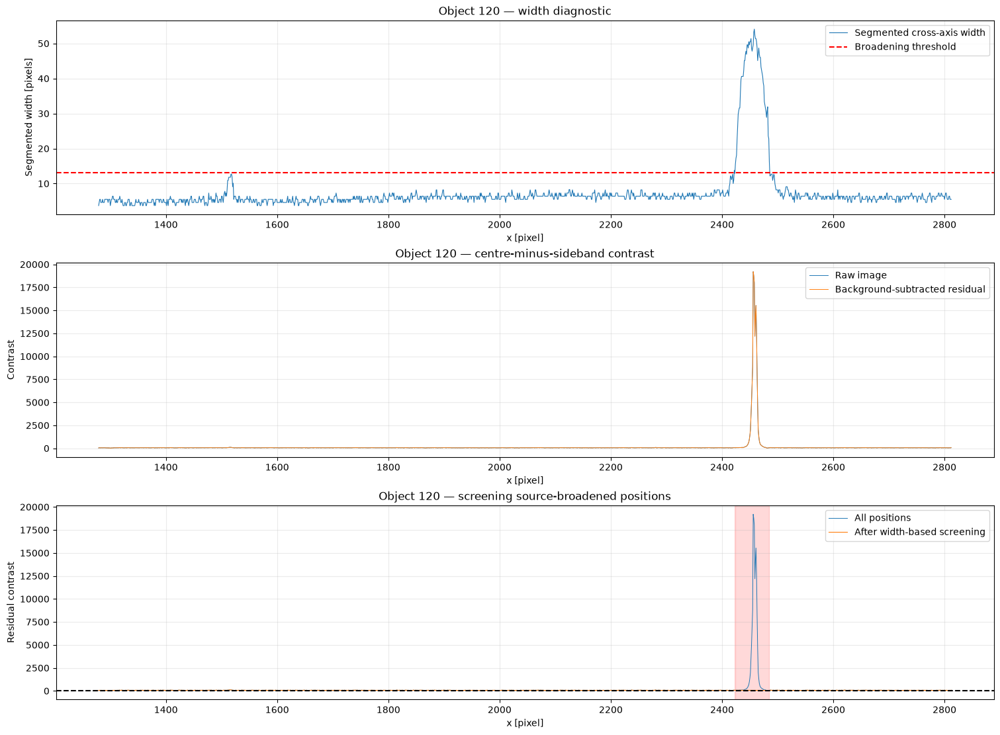


SOURCE-A VERTICAL FAMILY — REPEATED-VALUE AUDIT
------------------------------------------------
Family pixels: 33061
Repeated-value family pixels: 23066
Repeated-value fraction: 0.6976800459756208
Median row-wise repeated fraction: 0.7142857142857143
Rows with repeated fraction >= 50%: 2195
Rows with repeated fraction >= 90%: 134

VERTICAL INTERVALS WITH >=50% REPEATED VALUES
---------------------------------------------
{'start': 595, 'end': 1762, 'number_of_bins': 1168}
{'start': 1809, 'end': 2347, 'number_of_bins': 539}
{'start': 2384, 'end': 2509, 'number_of_bins': 126}
{'start': 2524, 'end': 2809, 'number_of_bins': 286}
{'start': 2821, 'end': 2822, 'number_of_bins': 2}
{'start': 2824, 'end': 2852, 'number_of_bins': 29}
{'start': 2854, 'end': 2873, 'number_of_bins': 20}
{'start': 2876, 'end': 2897, 'number_of_bins': 22}
{'start': 2911, 'end': 2913, 'number_of_bins': 3}


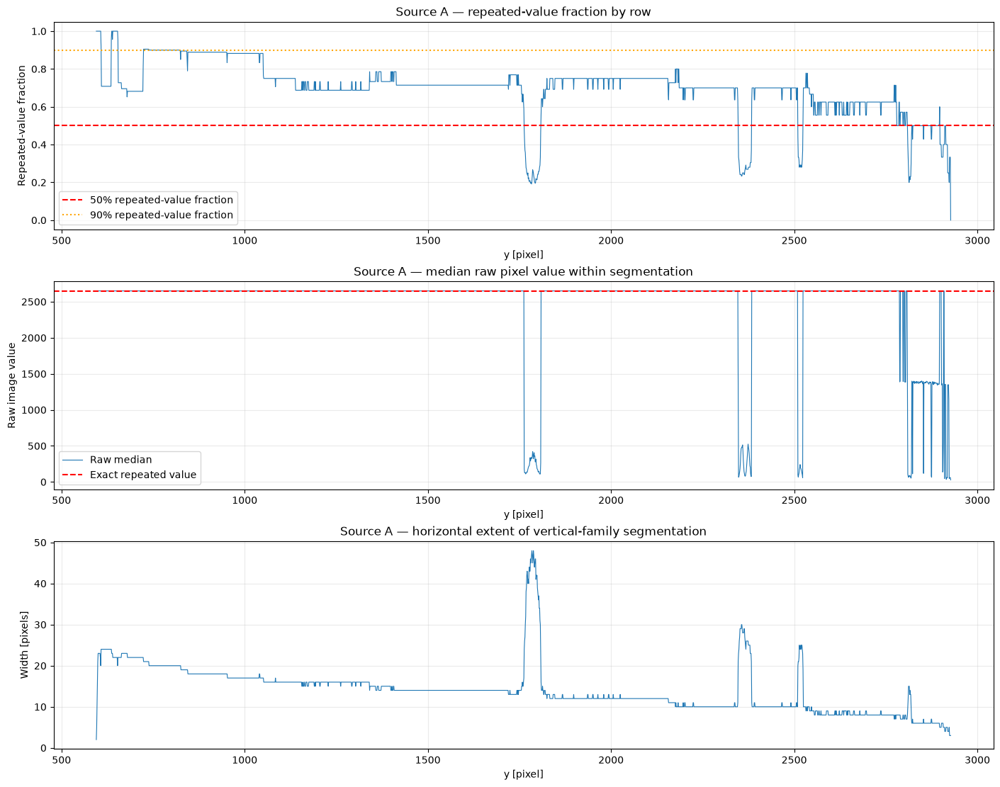


STAGE 6.4 DIAGNOSTICS COMPLETE
------------------------------
Horizontal figure: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/horizontal_120_width_screening.png
Vertical figure: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/source_A_vertical_repeated_value_profiles.png
Vertical row table: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/source_A_vertical_row_diagnostics.csv
JSON report: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/linear_candidate_cleaning_diagnostics.json

Memory: {'process_rss_gib': 2.064, 'available_ram_gib': 4.206}


In [26]:
# ============================================================
# CELL 20 — CLEAN LINEAR-CANDIDATE AND REPEATED-VALUE ANALYSIS
#
# A. Object 120: separate the narrow linear component from
#    locally broadened/source-contaminated positions.
#
# B. Objects 925–928: quantify the repeated-value structure
#    row by row.
#
# No masking, subtraction or image modification.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

# ------------------------------------------------------------
# 1. Validate dependencies
# ------------------------------------------------------------

if "LINEAR_PROFILE_RESULTS" not in globals():
    raise RuntimeError("Run Cell 19 first.")

if "horizontal_120" not in LINEAR_PROFILE_RESULTS:
    raise RuntimeError("Horizontal object 120 results unavailable.")

if "segmentation_map" not in globals():
    raise RuntimeError("SEP segmentation map unavailable.")


# ============================================================
# PART A — HORIZONTAL FEATURE, OBJECT 120
# ============================================================

horizontal = LINEAR_PROFILE_RESULTS["horizontal_120"]

centreline = horizontal["centreline"]
sampled = horizontal["sampled"]

major = centreline["major"]
segmented_width = centreline["width"]

core_mask = sampled["core_mask"]
sideband_mask = sampled["sideband_mask"]

# ------------------------------------------------------------
# 2. Find source-broadened positions using the width profile
# ------------------------------------------------------------

valid_width = (
    np.isfinite(segmented_width)
    & (segmented_width > 0)
)

width_values = segmented_width[valid_width]

if width_values.size == 0:
    raise RuntimeError("No valid horizontal width measurements.")

width_median = float(np.median(width_values))

width_mad = float(
    1.4826022185
    * np.median(np.abs(width_values - width_median))
)

# Conservative outlier threshold.
# We require BOTH a doubling of the typical width and
# a five-robust-sigma deviation.
width_threshold = max(
    2.0 * width_median,
    width_median + 5.0 * width_mad
)

broadened_mask = (
    valid_width
    & (segmented_width > width_threshold)
)

print("HORIZONTAL FEATURE — WIDTH DIAGNOSTIC")
print("--------------------------------------")

print("Median segmented width:", width_median)
print("Robust width spread:", width_mad)
print("Broadening threshold:", width_threshold)

print(
    "Broadened major-axis samples:",
    int(broadened_mask.sum())
)

print(
    "Broadened fraction:",
    float(broadened_mask.mean())
)


# ------------------------------------------------------------
# 3. Convert broadened positions into coordinate intervals
# ------------------------------------------------------------

def boolean_intervals(values, coordinate_values):

    values = np.asarray(values, dtype=bool)
    coordinates = np.asarray(coordinate_values)

    if len(values) != len(coordinates):
        raise ValueError("Interval arrays have different lengths.")

    edges = np.diff(
        np.r_[False, values, False].astype(np.int8)
    )

    starts = np.where(edges == 1)[0]
    stops = np.where(edges == -1)[0]

    intervals = []

    for start, stop in zip(starts, stops):

        intervals.append({
            "start": int(coordinates[start]),
            "end": int(coordinates[stop - 1]),
            "number_of_bins": int(stop - start)
        })

    return intervals


broadened_intervals = boolean_intervals(
    broadened_mask,
    major
)

print("\nPOTENTIALLY SOURCE-BROADENED INTERVALS")
print("--------------------------------------")

for interval in broadened_intervals:
    print(interval)


# ------------------------------------------------------------
# 4. Recalculate contrast from saved strips
# ------------------------------------------------------------

def safe_median_rows_20(array):

    array = np.asarray(array, dtype=np.float64)

    result = np.full(
        array.shape[0],
        np.nan,
        dtype=np.float64
    )

    valid = np.isfinite(array).any(axis=1)

    if valid.any():

        result[valid] = np.nanmedian(
            array[valid],
            axis=1
        )

    return result


def contrast_from_strip(strip):

    core = strip[:, core_mask]
    side = strip[:, sideband_mask]

    return (
        safe_median_rows_20(core)
        - safe_median_rows_20(side)
    )


horizontal_contrasts = {}

for offset, data in sampled["profiles"].items():

    horizontal_contrasts[offset] = {

        "raw": contrast_from_strip(
            data["raw_strip"]
        ),

        "residual": contrast_from_strip(
            data["residual_strip"]
        )

    }


# ------------------------------------------------------------
# 5. Compare complete feature and width-screened feature
# ------------------------------------------------------------

target_residual = horizontal_contrasts[0.0]["residual"]
target_raw = horizontal_contrasts[0.0]["raw"]

control_offsets = [
    offset
    for offset in PARALLEL_CONTROL_OFFSETS
    if offset != 0
]

control_matrix = np.stack(
    [
        horizontal_contrasts[offset]["residual"]
        for offset in control_offsets
    ],
    axis=0
)

control_common = (
    np.isfinite(target_residual)
    & np.isfinite(control_matrix).all(axis=0)
)

# All-position diagnostic.
# Width-screened comparison excludes positions where the
# segmented structure expands beyond its normal width.
clean_mask = (
    control_common
    & ~broadened_mask
)


def summarize_target_controls(
    target_values,
    controls,
    valid
):

    values = target_values[valid]

    control_values = controls[:, valid]

    control_reference = np.median(
        control_values,
        axis=0
    )

    paired_difference = (
        values - control_reference
    )

    return {

        "number_of_positions": int(valid.sum()),

        "fraction_retained": float(valid.mean()),

        "target_median": float(np.median(values)),

        "target_p10": float(np.percentile(values, 10)),

        "target_p90": float(np.percentile(values, 90)),

        "control_reference_median": float(
            np.median(control_reference)
        ),

        "paired_difference_median": float(
            np.median(paired_difference)
        ),

        "paired_difference_p10": float(
            np.percentile(paired_difference, 10)
        ),

        "paired_difference_p90": float(
            np.percentile(paired_difference, 90)
        ),

        "fraction_target_above_control": float(
            np.mean(paired_difference > 0)
        ),

        "fraction_positive_target": float(
            np.mean(values > 0)
        )

    }


horizontal_full_summary = summarize_target_controls(
    target_residual,
    control_matrix,
    control_common
)

horizontal_clean_summary = summarize_target_controls(
    target_residual,
    control_matrix,
    clean_mask
)

print("\nHORIZONTAL FEATURE — COMPLETE INTERVAL")
print("--------------------------------------")

for key, value in horizontal_full_summary.items():
    print(f"{key:42s}: {value}")


print("\nHORIZONTAL FEATURE — WIDTH-SCREENED INTERVAL")
print("--------------------------------------------")

for key, value in horizontal_clean_summary.items():
    print(f"{key:42s}: {value}")


# ------------------------------------------------------------
# 6. Along-axis block statistics after width screening
# ------------------------------------------------------------

HORIZONTAL_BLOCK_SIZE = 128

block_edges = np.arange(
    major.min(),
    major.max() + HORIZONTAL_BLOCK_SIZE,
    HORIZONTAL_BLOCK_SIZE
)

horizontal_blocks = []

for left, right in zip(
    block_edges[:-1],
    block_edges[1:]
):

    use = (
        clean_mask
        & (major >= left)
        & (major < right)
    )

    if use.sum() < 10:
        continue

    values = target_residual[use]

    local_controls = control_matrix[:, use]

    local_reference = np.median(
        local_controls,
        axis=0
    )

    difference = (
        values - local_reference
    )

    horizontal_blocks.append({

        "x_start": int(left),

        "x_end": int(min(right, major.max() + 1)),

        "valid_samples": int(use.sum()),

        "target_median": float(np.median(values)),

        "control_median": float(
            np.median(local_reference)
        ),

        "target_minus_control": float(
            np.median(difference)
        ),

        "positive_difference_fraction": float(
            np.mean(difference > 0)
        )

    })


print("\nWIDTH-SCREENED HORIZONTAL BLOCKS")
print("--------------------------------")

for record in horizontal_blocks:
    print(record)


# ------------------------------------------------------------
# 7. Plot object 120 after excluding broadened positions
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 11),
    constrained_layout=True
)

axes[0].plot(
    major,
    segmented_width,
    linewidth=0.8,
    label="Segmented cross-axis width"
)

axes[0].axhline(
    width_threshold,
    color="red",
    linestyle="--",
    label="Broadening threshold"
)

axes[0].set_title(
    "Object 120 — width diagnostic"
)

axes[0].set_xlabel("x [pixel]")
axes[0].set_ylabel("Segmented width [pixels]")

axes[0].legend()
axes[0].grid(alpha=0.25)


axes[1].plot(
    major,
    target_raw,
    linewidth=0.7,
    label="Raw image"
)

axes[1].plot(
    major,
    target_residual,
    linewidth=0.7,
    label="Background-subtracted residual"
)

axes[1].set_title(
    "Object 120 — centre-minus-sideband contrast"
)

axes[1].set_xlabel("x [pixel]")
axes[1].set_ylabel("Contrast")

axes[1].legend()
axes[1].grid(alpha=0.25)


axes[2].plot(
    major,
    target_residual,
    linewidth=0.7,
    label="All positions"
)

axes[2].plot(
    major[clean_mask],
    target_residual[clean_mask],
    linewidth=0.8,
    label="After width-based screening"
)

axes[2].axhline(
    0,
    color="black",
    linestyle="--"
)

for interval in broadened_intervals:

    axes[2].axvspan(
        interval["start"],
        interval["end"],
        alpha=0.15,
        color="red"
    )

axes[2].set_title(
    "Object 120 — screening source-broadened positions"
)

axes[2].set_xlabel("x [pixel]")
axes[2].set_ylabel("Residual contrast")

axes[2].legend()
axes[2].grid(alpha=0.25)


HORIZONTAL_CLEAN_FIGURE = (
    FRAME_OUTPUT_DIR /
    "horizontal_120_width_screening.png"
)

fig.savefig(
    HORIZONTAL_CLEAN_FIGURE,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# PART B — SOURCE A VERTICAL FAMILY
# ============================================================

VERTICAL_OBJECT_IDS = [925, 926, 927, 928]

vertical_family_mask = np.isin(
    segmentation_map,
    VERTICAL_OBJECT_IDS
)

yy, xx = np.nonzero(
    vertical_family_mask
)

if len(xx) == 0:
    raise RuntimeError("Vertical family segmentation is empty.")

y_min = int(yy.min())
y_max = int(yy.max())

rows = np.arange(
    y_min,
    y_max + 1,
    dtype=np.int32
)

repeat_value = np.float32(
    SUSPECT_CONSTANT_VALUE
)

repeated_value_mask = (
    image_raw == repeat_value
)

# ------------------------------------------------------------
# 8. Quantify row-by-row component structure
# ------------------------------------------------------------

vertical_records = []

for y in rows:

    row_component = vertical_family_mask[y, :]

    row_x = np.flatnonzero(row_component)

    if row_x.size == 0:
        continue

    row_values = image_raw[y, row_x]

    n_component = int(row_x.size)

    n_repeated = int(
        np.count_nonzero(
            row_values == repeat_value
        )
    )

    record = {

        "y": int(y),

        "component_pixels": n_component,

        "repeated_value_pixels": n_repeated,

        "repeated_fraction": float(
            n_repeated / n_component
        ),

        "median_raw_value": float(
            np.median(row_values)
        ),

        "median_residual_value": float(
            np.median(residual_128[y, row_x])
        ),

        "x_median": float(
            np.median(row_x)
        ),

        "x_width": int(
            row_x.max() - row_x.min() + 1
        )

    }

    vertical_records.append(record)


vertical_df = pd.DataFrame(
    vertical_records
)

if vertical_df.empty:
    raise RuntimeError("No vertical family row records were generated.")

# ------------------------------------------------------------
# 9. Quantify exact repeated-value dominance
# ------------------------------------------------------------

total_family_pixels = int(
    vertical_family_mask.sum()
)

family_repeated_pixels = int(
    np.count_nonzero(
        vertical_family_mask & repeated_value_mask
    )
)

overall_repeated_fraction = (
    family_repeated_pixels / total_family_pixels
)

print("\nSOURCE-A VERTICAL FAMILY — REPEATED-VALUE AUDIT")
print("------------------------------------------------")

print("Family pixels:", total_family_pixels)

print("Repeated-value family pixels:", family_repeated_pixels)

print("Repeated-value fraction:", overall_repeated_fraction)

print(
    "Median row-wise repeated fraction:",
    float(vertical_df["repeated_fraction"].median())
)

print(
    "Rows with repeated fraction >= 50%:",
    int(
        np.sum(
            vertical_df["repeated_fraction"] >= 0.5
        )
    )
)

print(
    "Rows with repeated fraction >= 90%:",
    int(
        np.sum(
            vertical_df["repeated_fraction"] >= 0.9
        )
    )
)


# ------------------------------------------------------------
# 10. Identify intervals with high repeated-value dominance
# ------------------------------------------------------------

high_repeat = (
    vertical_df["repeated_fraction"].to_numpy() >= 0.5
)

high_repeat_intervals = boolean_intervals(
    high_repeat,
    vertical_df["y"].to_numpy()
)

print("\nVERTICAL INTERVALS WITH >=50% REPEATED VALUES")
print("---------------------------------------------")

for interval in high_repeat_intervals:
    print(interval)


# ------------------------------------------------------------
# 11. Plot row-wise diagnostic profiles
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 11),
    constrained_layout=True
)

axes[0].plot(
    vertical_df["y"],
    vertical_df["repeated_fraction"],
    linewidth=0.8
)

axes[0].axhline(
    0.5,
    color="red",
    linestyle="--",
    label="50% repeated-value fraction"
)

axes[0].axhline(
    0.9,
    color="orange",
    linestyle=":",
    label="90% repeated-value fraction"
)

axes[0].set_title(
    "Source A — repeated-value fraction by row"
)

axes[0].set_xlabel("y [pixel]")
axes[0].set_ylabel("Repeated-value fraction")

axes[0].set_ylim(-0.05, 1.05)
axes[0].legend()
axes[0].grid(alpha=0.25)


axes[1].plot(
    vertical_df["y"],
    vertical_df["median_raw_value"],
    linewidth=0.8,
    label="Raw median"
)

axes[1].axhline(
    float(repeat_value),
    color="red",
    linestyle="--",
    label="Exact repeated value"
)

axes[1].set_title(
    "Source A — median raw pixel value within segmentation"
)

axes[1].set_xlabel("y [pixel]")
axes[1].set_ylabel("Raw image value")

axes[1].legend()
axes[1].grid(alpha=0.25)


axes[2].plot(
    vertical_df["y"],
    vertical_df["x_width"],
    linewidth=0.8
)

axes[2].set_title(
    "Source A — horizontal extent of vertical-family segmentation"
)

axes[2].set_xlabel("y [pixel]")
axes[2].set_ylabel("Width [pixels]")

axes[2].grid(alpha=0.25)


VERTICAL_REPEAT_FIGURE = (
    FRAME_OUTPUT_DIR /
    "source_A_vertical_repeated_value_profiles.png"
)

fig.savefig(
    VERTICAL_REPEAT_FIGURE,
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 12. Save diagnostic report
# ------------------------------------------------------------

CELL20_REPORT = {

    "frame": FRAME_FILENAME,

    "horizontal_candidate": {

        "object_id": 120,

        "width_median_px": width_median,

        "width_robust_spread_px": width_mad,

        "width_screen_threshold_px": width_threshold,

        "broadened_intervals": broadened_intervals,

        "full_interval_summary": horizontal_full_summary,

        "width_screened_summary": horizontal_clean_summary,

        "block_records": horizontal_blocks,

        "interpretation":
            "Unresolved horizontal linear candidate; "
            "width-screened comparison is diagnostic only."

    },

    "source_A_vertical_family": {

        "object_ids": VERTICAL_OBJECT_IDS,

        "total_component_pixels": total_family_pixels,

        "repeated_value_pixels": family_repeated_pixels,

        "repeated_fraction": overall_repeated_fraction,

        "high_repeat_intervals": high_repeat_intervals,

        "interpretation":
            "Strong repeated-value/source-associated data artefact candidate; "
            "physical origin remains unconfirmed."

    }

}

CELL20_JSON_PATH = (
    FRAME_OUTPUT_DIR /
    "linear_candidate_cleaning_diagnostics.json"
)

CELL20_JSON_PATH.write_text(
    json.dumps(
        CELL20_REPORT,
        indent=2
    ),
    encoding="utf-8"
)

VERTICAL_PROFILE_CSV = (
    FRAME_OUTPUT_DIR /
    "source_A_vertical_row_diagnostics.csv"
)

vertical_df.to_csv(
    VERTICAL_PROFILE_CSV,
    index=False
)


print("\nSTAGE 6.4 DIAGNOSTICS COMPLETE")
print("------------------------------")

print("Horizontal figure:", HORIZONTAL_CLEAN_FIGURE)

print("Vertical figure:", VERTICAL_REPEAT_FIGURE)

print("Vertical row table:", VERTICAL_PROFILE_CSV)

print("JSON report:", CELL20_JSON_PATH)

print("\nMemory:", memory_report())

<span style="color:red">**The horizontal feature has survived the contamination test. This is a significant result. Object 120 should now be treated as a second high-priority linear detection candidate, not as a feature to remove during preprocessing.**</span>

The bright source around \(x=2450\) was a major concern. Your width-based screening has shown that it does not explain the rest of the line.

**What these results mean scientifically**

We now have at least two distinct long linear structures in the same image:
- The diagonal manually annotated feature, approximately 4,552.85 pixels long.
- The horizontal object-120 feature, approximately 1,534 pixels long.

They have different orientations and different local environments.

The fact that both are detected as extended structures makes it important not to use the manual diagonal as the only evaluation target.

### Empirical PSF calibration


**Why do we need a PSF?**

The Point Spread Function (PSF) describes how a telescope and its detector distribute the light from an ideal point source across neighbouring pixels.

Imagine a star with no apparent physical size. It does not appear as one bright pixel in the image. Its light is distributed over several pixels, forming a profile.

What we must avoid when selecting calibration stars
Our catalogue contains several unsuitable candidates:
- Objects near the source-A vertical structure.
- Objects close to the horizontal feature.
- Objects around the complicated source-B region.
- Sources intersecting the manually annotated diagonal.
- Blended or elongated detections.
- Sources containing unusually high pixel values.
We should not use every compact-looking detection as a PSF star.

Our first task is to construct a reliable sample of isolated, moderately bright, approximately circular detections.

PSF CALIBRATION REFERENCES
---------------------------
Header FWHM [arcsec]: 2.5201002281347624
Pixel scale [arcsec/px]: 0.3276
Reference FWHM [px]: 7.6926136389950015
Reference Gaussian sigma [px]: 3.266752232438637

INITIAL SOURCE INVENTORY
------------------------
Total detections: 1412
After basic morphology/intensity screening: 154
After target-buffer exclusion: 147

ARTIFACT EXCLUSION MASK
Seed pixels: 218727
Dilated exclusion pixels: 535703
After centroid isolation screening: 130

PSF CANDIDATE SELECTION REPORT
------------------------------
Basic candidates: 154
After target exclusion: 147
After isolation: 130
Cutouts examined: 130
Other-source contamination: 1
Known artefact overlap: 1
Repeated-value contamination: 0
High-value pixels: 0
Final PSF candidates: 128

SELECTED PSF CALIBRATION CANDIDATES
-----------------------------------
 object_id           x           y        a        b  moment_aspect_ratio  npix     raw_peak  peak_over_local_rms  nearest_source_distance_px  d

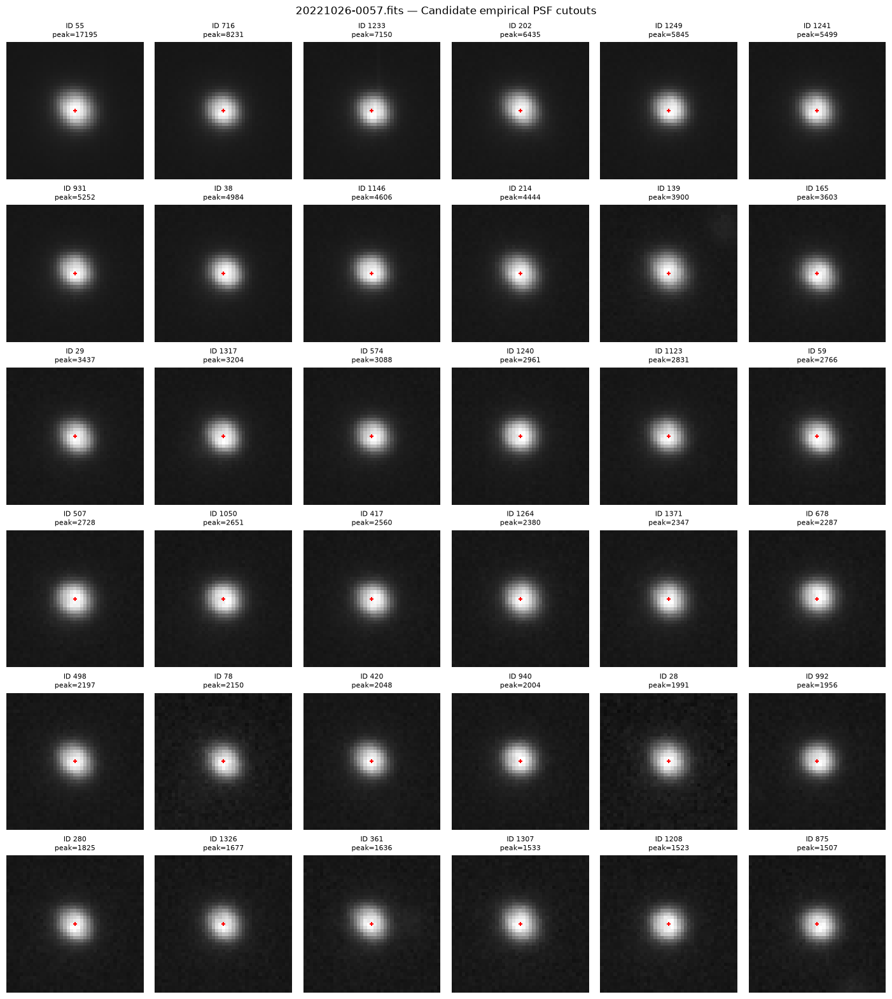


STAGE 7.1 COMPLETE
------------------
Candidate table: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_calibration_candidates.csv
Candidate audit: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_calibration_candidate_audit.csv
Cutout preview: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_calibration_candidate_cutouts.png
Selection report: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_calibration_selection_report.json

Memory: {'process_rss_gib': 2.129, 'available_ram_gib': 4.292}


In [27]:
# ============================================================
# CELL 21 — PSF CALIBRATION CANDIDATE SELECTION
#
# Purpose:
#   Identify isolated, compact, unsaturated-by-screening,
#   unblended source candidates for empirical PSF measurement.
#
# No PSF fitting yet.
# No image subtraction.
# No masking of original data.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from scipy import ndimage as ndi
from scipy.spatial import cKDTree


# ------------------------------------------------------------
# 1. Validate dependencies
# ------------------------------------------------------------

required = [
    "morphology_catalogue",
    "segmentation_map",
    "image_raw",
    "residual_128",
    "visible_start",
    "visible_end",
    "FRAME_OUTPUT_DIR"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing dependencies: {missing}"
    )


# ------------------------------------------------------------
# 2. PSF reference and candidate configuration
# ------------------------------------------------------------

header_fwhm_arcsec = float(raw_header["FWHM"])

header_pixel_scale_arcsec = float(raw_header["IMSCALE"])

PSF_REFERENCE_FWHM_PIX = (
    header_fwhm_arcsec / header_pixel_scale_arcsec
)

PSF_REFERENCE_SIGMA_PIX = (
    PSF_REFERENCE_FWHM_PIX / 2.354820045
)

PSF_CANDIDATE_HALF_SIZE = 20

PSF_CANDIDATE_CUTOUT_SIZE = (
    2 * PSF_CANDIDATE_HALF_SIZE + 1
)

# Conservative screening criteria.
# These are not calibration results.
PSF_MIN_A = 2.0
PSF_MAX_A = 5.0

PSF_MIN_B = 2.0
PSF_MAX_B = 4.8

PSF_MAX_MOMENT_RATIO = 1.5

PSF_MIN_AREA = 20
PSF_MAX_AREA = 1500

PSF_MIN_RAW_PEAK = 1500.0
PSF_MAX_RAW_PEAK = 25000.0

PSF_MIN_PEAK_RMS = 15.0

PSF_MIN_NEIGHBOUR_DISTANCE = 35.0

PSF_MIN_TARGET_DISTANCE = 60.0

PSF_ARTIFACT_DILATION_RADIUS = 22


print("PSF CALIBRATION REFERENCES")
print("---------------------------")

print("Header FWHM [arcsec]:", header_fwhm_arcsec)

print("Pixel scale [arcsec/px]:", header_pixel_scale_arcsec)

print("Reference FWHM [px]:", PSF_REFERENCE_FWHM_PIX)

print("Reference Gaussian sigma [px]:", PSF_REFERENCE_SIGMA_PIX)


# ------------------------------------------------------------
# 3. Obtain the source candidate table
# ------------------------------------------------------------

psf_pool = morphology_catalogue.copy()

required_columns = [
    "object_id",
    "x", "y",
    "a", "b",
    "npix",
    "flag",
    "moment_aspect_ratio",
    "raw_peak",
    "peak_over_local_rms",
    "pixels_ge_60000"
]

missing_columns = [
    col for col in required_columns
    if col not in psf_pool.columns
]

if missing_columns:
    raise RuntimeError(
        f"Missing catalogue columns: {missing_columns}"
    )

print("\nINITIAL SOURCE INVENTORY")
print("------------------------")

print("Total detections:", len(psf_pool))


# ------------------------------------------------------------
# 4. Basic compact-source and quality screening
# ------------------------------------------------------------

basic_mask = (

    (psf_pool["flag"] == 0)

    & psf_pool["a"].between(
        PSF_MIN_A,
        PSF_MAX_A
    )

    & psf_pool["b"].between(
        PSF_MIN_B,
        PSF_MAX_B
    )

    & (
        psf_pool["moment_aspect_ratio"]
        <= PSF_MAX_MOMENT_RATIO
    )

    & psf_pool["npix"].between(
        PSF_MIN_AREA,
        PSF_MAX_AREA
    )

    & psf_pool["raw_peak"].between(
        PSF_MIN_RAW_PEAK,
        PSF_MAX_RAW_PEAK
    )

    & (
        psf_pool["peak_over_local_rms"]
        >= PSF_MIN_PEAK_RMS
    )

    & (
        psf_pool["pixels_ge_60000"] == 0
    )

)

psf_basic = psf_pool.loc[
    basic_mask
].copy()

print("After basic morphology/intensity screening:", len(psf_basic))


# ------------------------------------------------------------
# 5. Distance from the manually annotated target
# ------------------------------------------------------------

p0 = np.asarray(
    visible_start,
    dtype=np.float64
)

p1 = np.asarray(
    visible_end,
    dtype=np.float64
)

segment_vector = (
    p1 - p0
)

segment_length_squared = float(
    np.dot(segment_vector, segment_vector)
)

points = psf_basic[
    ["x", "y"]
].to_numpy(dtype=np.float64)

relative = points - p0

projection = (
    relative @ segment_vector
) / segment_length_squared

projection = np.clip(
    projection,
    0.0,
    1.0
)

nearest_points = (
    p0
    + projection[:, None] * segment_vector
)

distance_to_target = np.linalg.norm(
    points - nearest_points,
    axis=1
)

psf_basic["distance_to_manual_target_px"] = (
    distance_to_target
)

target_distance_mask = (
    psf_basic["distance_to_manual_target_px"]
    >= PSF_MIN_TARGET_DISTANCE
)

psf_basic = psf_basic.loc[
    target_distance_mask
].copy()

print("After target-buffer exclusion:", len(psf_basic))


# ------------------------------------------------------------
# 6. Exclude known complex and linear structures
# ------------------------------------------------------------

ARTIFACT_OBJECT_IDS = [

    # Source A bright-source components.
    45, 102, 104,

    # Source A vertical family.
    925, 926, 927, 928,

    # Source B complex.
    115, 117, 118, 119,

    # Horizontal linear feature.
    120

]

artifact_seed_mask = np.isin(
    segmentation_map,
    ARTIFACT_OBJECT_IDS
)

# Circular dilation structure.
radius = PSF_ARTIFACT_DILATION_RADIUS

yy, xx = np.ogrid[
    -radius:radius + 1,
    -radius:radius + 1
]

dilation_footprint = (
    xx**2 + yy**2 <= radius**2
)

artifact_exclusion_mask = ndi.binary_dilation(
    artifact_seed_mask,
    structure=dilation_footprint
)

print("\nARTIFACT EXCLUSION MASK")

print(
    "Seed pixels:",
    int(artifact_seed_mask.sum())
)

print(
    "Dilated exclusion pixels:",
    int(artifact_exclusion_mask.sum())
)


# ------------------------------------------------------------
# 7. Apply nearest-neighbour isolation screening
# ------------------------------------------------------------

all_centroids = morphology_catalogue[
    ["x", "y"]
].to_numpy(dtype=np.float64)

catalogue_tree = cKDTree(
    all_centroids
)

candidate_points = psf_basic[
    ["x", "y"]
].to_numpy(dtype=np.float64)

nearest_distances, nearest_indices = (
    catalogue_tree.query(
        candidate_points,
        k=2
    )
)

# The first neighbour is the candidate itself.
nearest_other_distance = nearest_distances[:, 1]

psf_basic["nearest_source_distance_px"] = (
    nearest_other_distance
)

isolated_mask = (
    psf_basic["nearest_source_distance_px"]
    >= PSF_MIN_NEIGHBOUR_DISTANCE
)

psf_basic = psf_basic.loc[
    isolated_mask
].copy()

print("After centroid isolation screening:", len(psf_basic))


# ------------------------------------------------------------
# 8. Inspect every cutout for segmentation contamination,
#    repeated values and known artefact masks
# ------------------------------------------------------------

candidate_results = []

for row in psf_basic.itertuples():

    object_id = int(row.object_id)

    x0 = int(round(row.x))
    y0 = int(round(row.y))

    r = PSF_CANDIDATE_HALF_SIZE

    xmin = x0 - r
    xmax = x0 + r + 1

    ymin = y0 - r
    ymax = y0 + r + 1

    # Border rejection.
    if (
        xmin < 0
        or ymin < 0
        or xmax > image_raw.shape[1]
        or ymax > image_raw.shape[0]
    ):
        continue

    segmentation_cutout = segmentation_map[
        ymin:ymax,
        xmin:xmax
    ]

    raw_cutout = image_raw[
        ymin:ymax,
        xmin:xmax
    ]

    # Must have the expected fixed size.
    if (
        segmentation_cutout.shape
        != (
            PSF_CANDIDATE_CUTOUT_SIZE,
            PSF_CANDIDATE_CUTOUT_SIZE
        )
    ):
        continue

    # Reject any other detected source inside the cutout.
    other_source_pixels = (

        (segmentation_cutout > 0)

        & (segmentation_cutout != object_id)

    )

    has_other_sources = bool(
        other_source_pixels.any()
    )

    # Reject neighbourhoods intersecting known artefact regions.
    touches_artifact = bool(
        artifact_exclusion_mask[
            ymin:ymax,
            xmin:xmax
        ].any()
    )

    # Exact repeated-value contamination.
    contains_repeated_value = bool(
        np.any(
            raw_cutout == np.float32(SUSPECT_CONSTANT_VALUE)
        )
    )

    # Conservative high-value screen.
    # This is NOT a verified detector saturation threshold.
    high_pixel_present = bool(
        np.any(raw_cutout >= 60000.0)
    )

    cutout_valid = (
        not has_other_sources
        and not touches_artifact
        and not contains_repeated_value
        and not high_pixel_present
    )

    candidate_results.append({

        "object_id": object_id,

        "x": float(row.x),

        "y": float(row.y),

        "a": float(row.a),

        "b": float(row.b),

        "moment_aspect_ratio": float(
            row.moment_aspect_ratio
        ),

        "npix": int(row.npix),

        "raw_peak": float(row.raw_peak),

        "peak_over_local_rms": float(
            row.peak_over_local_rms
        ),

        "nearest_source_distance_px": float(
            row.nearest_source_distance_px
        ),

        "distance_to_manual_target_px": float(
            row.distance_to_manual_target_px
        ),

        "has_other_sources": has_other_sources,

        "touches_artifact": touches_artifact,

        "contains_repeated_value": contains_repeated_value,

        "high_pixel_present": high_pixel_present,

        "cutout_valid": cutout_valid

    })


psf_cutout_audit = pd.DataFrame(
    candidate_results
)

if psf_cutout_audit.empty:

    raise RuntimeError(
        "No candidate cutouts could be evaluated."
    )

psf_candidates = psf_cutout_audit.loc[
    psf_cutout_audit["cutout_valid"]
].copy()

psf_candidates = psf_candidates.sort_values(
    "raw_peak",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 9. Print selection report
# ------------------------------------------------------------

print("\nPSF CANDIDATE SELECTION REPORT")
print("------------------------------")

print("Basic candidates:", len(psf_pool.loc[basic_mask]))

print("After target exclusion:", int(target_distance_mask.sum()))

print("After isolation:", int(isolated_mask.sum()))

print("Cutouts examined:", len(psf_cutout_audit))

print(
    "Other-source contamination:",
    int(psf_cutout_audit["has_other_sources"].sum())
)

print(
    "Known artefact overlap:",
    int(psf_cutout_audit["touches_artifact"].sum())
)

print(
    "Repeated-value contamination:",
    int(psf_cutout_audit["contains_repeated_value"].sum())
)

print(
    "High-value pixels:",
    int(psf_cutout_audit["high_pixel_present"].sum())
)

print("Final PSF candidates:", len(psf_candidates))


# ------------------------------------------------------------
# 10. Show candidate catalogue
# ------------------------------------------------------------

PSF_DISPLAY_COLUMNS = [

    "object_id",

    "x", "y",

    "a", "b",

    "moment_aspect_ratio",

    "npix",

    "raw_peak",

    "peak_over_local_rms",

    "nearest_source_distance_px",

    "distance_to_manual_target_px"

]

print("\nSELECTED PSF CALIBRATION CANDIDATES")
print("-----------------------------------")

print(
    psf_candidates[
        PSF_DISPLAY_COLUMNS
    ].head(40).to_string(index=False)
)


# ------------------------------------------------------------
# 11. Create a representative cutout preview
# ------------------------------------------------------------

if len(psf_candidates) < 12:

    print(
        "\nWARNING: Fewer than 12 calibration candidates passed. "
        "Do not relax the criteria automatically."
    )

preview_count = min(
    len(psf_candidates),
    36
)

if preview_count == 0:

    raise RuntimeError(
        "No PSF candidates passed the screening."
    )

# Select candidates spread across the brightness distribution.
preview_indices = np.unique(
    np.linspace(
        0,
        len(psf_candidates) - 1,
        preview_count
    ).astype(int)
)

preview_rows = psf_candidates.iloc[
    preview_indices
]

ncols = 6
nrows = int(np.ceil(len(preview_rows) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 2.6 * nrows),
    squeeze=False,
    constrained_layout=True
)

for ax in axes.flat:
    ax.axis("off")

for ax, row in zip(
    axes.flat,
    preview_rows.itertuples()
):

    x0 = int(round(row.x))
    y0 = int(round(row.y))

    r = PSF_CANDIDATE_HALF_SIZE

    cutout = residual_128[
        y0-r:y0+r+1,
        x0-r:x0+r+1
    ].astype(np.float32)

    # Local outer-border estimate.
    border = np.concatenate([
        cutout[:3, :].ravel(),
        cutout[-3:, :].ravel(),
        cutout[:, :3].ravel(),
        cutout[:, -3:].ravel()
    ])

    local_level = float(
        np.median(border)
    )

    cutout = cutout - local_level

    peak = float(np.max(cutout))

    if peak <= 0:
        continue

    # Normalisation allows morphology comparison across stars.
    normalized = cutout / peak

    im = ax.imshow(
        normalized,
        origin="lower",
        cmap="gray",
        vmin=-0.1,
        vmax=1.0,
        interpolation="nearest"
    )

    ax.scatter(
        [PSF_CANDIDATE_HALF_SIZE],
        [PSF_CANDIDATE_HALF_SIZE],
        marker="+",
        color="red",
        s=20
    )

    ax.set_title(
        f"ID {row.object_id}\n"
        f"peak={row.raw_peak:.0f}",
        fontsize=8
    )

    ax.axis("off")


fig.suptitle(
    f"{FRAME_FILENAME} — Candidate empirical PSF cutouts"
)

PSF_CANDIDATE_FIGURE = (
    FRAME_OUTPUT_DIR /
    "psf_calibration_candidate_cutouts.png"
)

fig.savefig(
    PSF_CANDIDATE_FIGURE,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 12. Save selection products
# ------------------------------------------------------------

PSF_CANDIDATE_TABLE = (
    FRAME_OUTPUT_DIR /
    "psf_calibration_candidates.csv"
)

psf_candidates.to_csv(
    PSF_CANDIDATE_TABLE,
    index=False
)

PSF_CANDIDATE_AUDIT = (
    FRAME_OUTPUT_DIR /
    "psf_calibration_candidate_audit.csv"
)

psf_cutout_audit.to_csv(
    PSF_CANDIDATE_AUDIT,
    index=False
)


PSF_SELECTION_REPORT = {

    "frame": FRAME_FILENAME,

    "fits_sha256": FITS_SHA256,

    "reference_fwhm_arcsec": header_fwhm_arcsec,

    "reference_pixel_scale_arcsec": header_pixel_scale_arcsec,

    "reference_fwhm_pixels": PSF_REFERENCE_FWHM_PIX,

    "reference_sigma_pixels": PSF_REFERENCE_SIGMA_PIX,

    "cutout_size_pixels": PSF_CANDIDATE_CUTOUT_SIZE,

    "selection_criteria": {

        "moment_a": [PSF_MIN_A, PSF_MAX_A],

        "moment_b": [PSF_MIN_B, PSF_MAX_B],

        "maximum_moment_ratio": PSF_MAX_MOMENT_RATIO,

        "source_area": [PSF_MIN_AREA, PSF_MAX_AREA],

        "raw_peak_range": [PSF_MIN_RAW_PEAK, PSF_MAX_RAW_PEAK],

        "nearest_source_distance_px":
            PSF_MIN_NEIGHBOUR_DISTANCE,

        "manual_target_buffer_px":
            PSF_MIN_TARGET_DISTANCE,

        "artifact_dilation_radius_px":
            PSF_ARTIFACT_DILATION_RADIUS

    },

    "total_detections": int(len(psf_pool)),

    "final_candidate_count": int(len(psf_candidates)),

    "candidate_audit_count": int(len(psf_cutout_audit)),

    "selection_stage": "Candidate screening only; no PSF fitting performed"

}

PSF_SELECTION_REPORT_PATH = (
    FRAME_OUTPUT_DIR /
    "psf_calibration_selection_report.json"
)

PSF_SELECTION_REPORT_PATH.write_text(
    json.dumps(
        PSF_SELECTION_REPORT,
        indent=2
    ),
    encoding="utf-8"
)


print("\nSTAGE 7.1 COMPLETE")
print("------------------")

print("Candidate table:", PSF_CANDIDATE_TABLE)

print("Candidate audit:", PSF_CANDIDATE_AUDIT)

print("Cutout preview:", PSF_CANDIDATE_FIGURE)

print("Selection report:", PSF_SELECTION_REPORT_PATH)

print("\nMemory:", memory_report())

**What the montage tells us**

The stars look reasonably consistent in shape, with a bright central core and smoothly decreasing surrounding light. 

### Subpixel registration and empirical PSF stacking

Before fitting Gaussian or Moffat functions, we should build an empirical PSF directly from the 128 observed stars.

**A key detail**: Our stars do not all fall at the same fractional pixel position. A star centred at \((100.2,200.7)\) is sampled differently from one centred at \((100.8,200.1)\), even if the underlying optical PSF is identical.

We will therefore:
1. Extract the same 41 × 41 pixel cutout around every candidate.
2. Estimate and remove its local residual background.
3. Shift each cutout to a common subpixel centre.
4. Normalise each star independently.
5. Combine them using a median, which is less sensitive to a few unusual cutouts than a mean.
6. Construct separate stacks for the four image quadrants to check spatial variation.
We will also measure each star's own second-moment width. This will let us investigate the difference between the SEP catalogue dimensions and the empirical PSF.

EMPIRICAL PSF CONSTRUCTION
--------------------------
Candidate stars: 128

SUBPIXEL REGISTRATION RESULTS
-----------------------------
Registered stars: 128
Cutout array shape: (128, 41, 41)
Median residual-centroid correction [x]: 0.10334282490923523
Median residual-centroid correction [y]: 0.11159053990634256
Quadrant LL: 40 stars stacked.
Quadrant LR: 26 stars stacked.
Quadrant UL: 26 stars stacked.
Quadrant UR: 36 stars stacked.

INDIVIDUAL STAR MOMENT DISTRIBUTION
-----------------------------------
{'measurement': 'fwhm_major_moment', 'count': 128, 'median': 8.032787561935514, 'p16': 7.882574745780603, 'p84': 8.322626616370606}
{'measurement': 'fwhm_minor_moment', 'count': 128, 'median': 7.615137334991648, 'p16': 7.539231484155511, 'p84': 7.748148046914077}
{'measurement': 'ellipticity_moment', 'count': 128, 'median': 0.050783182378676184, 'p16': 0.03369683649660717, 'p84': 0.07535974201718901}

MOMENT OUTLIER DIAGNOSTIC
Median major FWHM: 8.032787561935514
Robust spread: 0.1810

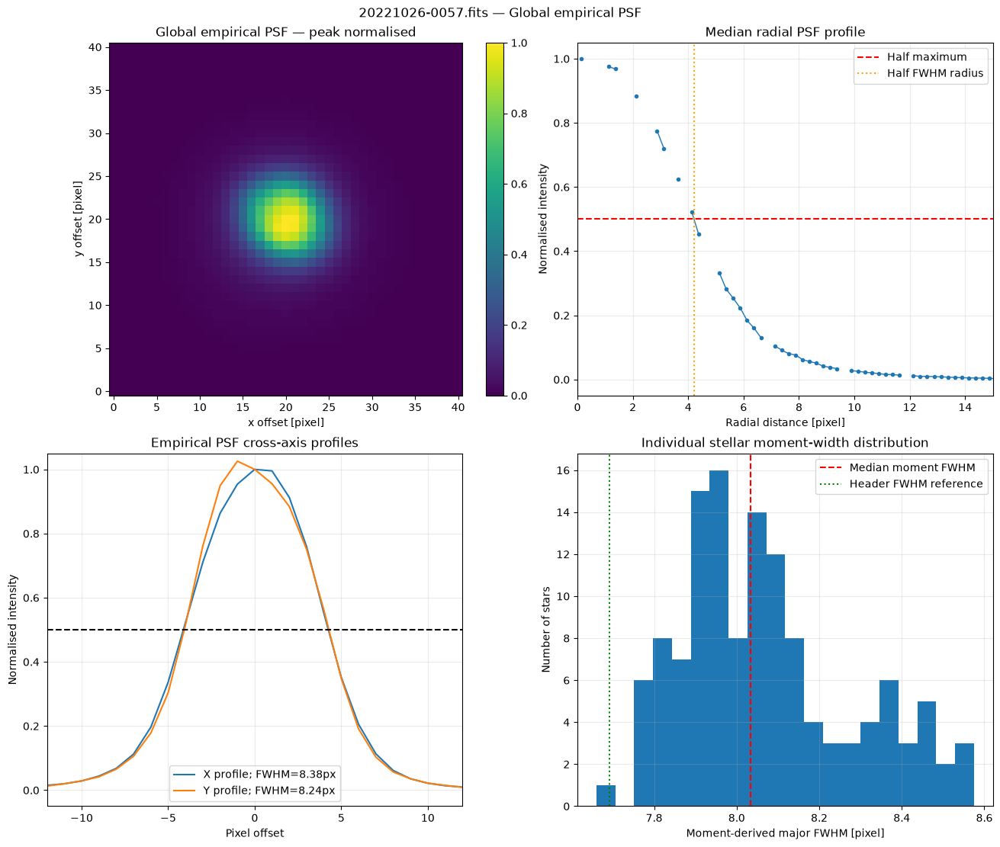

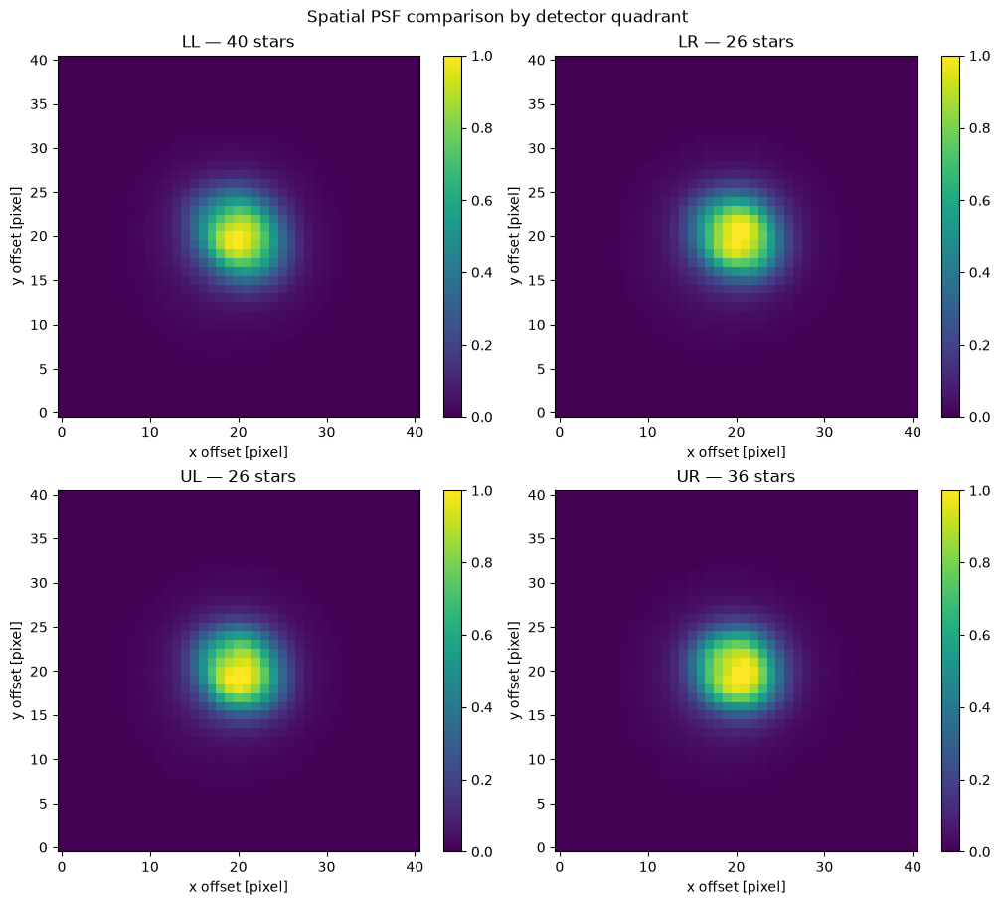


EMPIRICAL PSF SUMMARY
---------------------
Registered stars: 128
Radial-profile FWHM: 8.416157605375687
X-profile FWHM: 8.37614122359002
Y-profile FWHM: 8.23500421068733
Header FWHM reference: 7.6926136389950015
Radial FWHM difference from header [%]: 9.405697469491177

STAGE 7.2 COMPLETE
------------------
PSF array: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/empirical_psf_stacks.npz
Star measurements: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/empirical_psf_star_measurements.csv
Global PSF figure: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/empirical_psf_global_diagnostic.png
Quadrant PSF figure: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/empirical_psf_quadrant_comparison.png
Summary: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/2022

108640

In [28]:
# ============================================================
# CELL 22 — SUBPIXEL-REGISTERED EMPIRICAL PSF CONSTRUCTION
#
# Inputs:
#   psf_candidates
#   residual_128
#
# Outputs:
#   Globally stacked empirical PSF
#   Four quadrant-specific PSFs
#   Individual stellar width measurements
#   Radial and cross-axis profiles
#
# No source subtraction or masking.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import gc

from scipy import ndimage as ndi


# ------------------------------------------------------------
# 1. Validate inputs
# ------------------------------------------------------------

if len(psf_candidates) < 20:
    raise RuntimeError(
        "Insufficient PSF candidates for this experiment."
    )

if residual_128.shape != image_raw.shape:
    raise RuntimeError("Residual and raw image shapes differ.")

PSF_CUTOUT_RADIUS = 20
PSF_CUTOUT_SIZE = 2 * PSF_CUTOUT_RADIUS + 1

PSF_CENTER = int(PSF_CUTOUT_RADIUS)

PSF_SKY_INNER_RADIUS = 15.0
PSF_SKY_OUTER_RADIUS = 19.0

PSF_MOMENT_RADIUS = 10.0
PSF_FLUX_RADIUS = 15.0

PSF_REFERENCE = PSF_REFERENCE_FWHM_PIX

assert isinstance(PSF_CENTER, (int, np.integer))

assert PSF_CUTOUT_SIZE % 2 == 1

assert PSF_CENTER == PSF_CUTOUT_SIZE // 2

# ------------------------------------------------------------
# 2. Prepare coordinate grids
# ------------------------------------------------------------

grid_y, grid_x = np.mgrid[
    0:PSF_CUTOUT_SIZE,
    0:PSF_CUTOUT_SIZE
]

dx_grid = grid_x - PSF_CENTER
dy_grid = grid_y - PSF_CENTER

radius_grid = np.sqrt(
    dx_grid**2 + dy_grid**2
)

sky_annulus = (
    (radius_grid >= PSF_SKY_INNER_RADIUS)
    & (radius_grid <= PSF_SKY_OUTER_RADIUS)
)

moment_aperture = (
    radius_grid <= PSF_MOMENT_RADIUS
)

flux_aperture = (
    radius_grid <= PSF_FLUX_RADIUS
)


# ------------------------------------------------------------
# 3. Helper — positive-weight image moments
# ------------------------------------------------------------

def measure_cutout_moments(cutout):

    values = np.asarray(
        cutout,
        dtype=np.float64
    )

    weights = np.clip(
        values,
        0,
        None
    )

    weights *= moment_aperture

    total = float(weights.sum())

    if total <= 0:
        return None

    cx = float(
        np.sum(weights * dx_grid) / total
    )

    cy = float(
        np.sum(weights * dy_grid) / total
    )

    sx2 = float(
        np.sum(
            weights * (dx_grid - cx)**2
        ) / total
    )

    sy2 = float(
        np.sum(
            weights * (dy_grid - cy)**2
        ) / total
    )

    sxy = float(
        np.sum(
            weights
            * (dx_grid - cx)
            * (dy_grid - cy)
        ) / total
    )

    covariance = np.array([
        [sx2, sxy],
        [sxy, sy2]
    ])

    eigenvalues = np.linalg.eigvalsh(
        covariance
    )

    eigenvalues = np.maximum(
        eigenvalues,
        0
    )

    sigma_minor = float(
        np.sqrt(eigenvalues[0])
    )

    sigma_major = float(
        np.sqrt(eigenvalues[1])
    )

    return {

        "centroid_dx": cx,

        "centroid_dy": cy,

        "sigma_x": float(np.sqrt(max(sx2, 0))),

        "sigma_y": float(np.sqrt(max(sy2, 0))),

        "sigma_major": sigma_major,

        "sigma_minor": sigma_minor,

        "fwhm_major_moment": 2.354820045 * sigma_major,

        "fwhm_minor_moment": 2.354820045 * sigma_minor,

        "ellipticity_moment": (
            1.0 - sigma_minor / sigma_major
            if sigma_major > 0 else np.nan
        )

    }


# ------------------------------------------------------------
# 4. Extract, background-correct and subpixel-register stars
# ------------------------------------------------------------

registered_cutouts = []

registered_flux_cutouts = []

registration_records = []

print("EMPIRICAL PSF CONSTRUCTION")
print("--------------------------")

print("Candidate stars:", len(psf_candidates))

for row in psf_candidates.itertuples():

    x = float(row.x)
    y = float(row.y)

    x_integer = int(round(x))
    y_integer = int(round(y))

    xmin = x_integer - PSF_CUTOUT_RADIUS
    xmax = x_integer + PSF_CUTOUT_RADIUS + 1

    ymin = y_integer - PSF_CUTOUT_RADIUS
    ymax = y_integer + PSF_CUTOUT_RADIUS + 1

    # --------------------------------------------------------
    # A. Extract cutout
    # --------------------------------------------------------

    cutout = residual_128[
        ymin:ymax,
        xmin:xmax
    ].astype(np.float32)

    if cutout.shape != (
        PSF_CUTOUT_SIZE,
        PSF_CUTOUT_SIZE
    ):
        continue

    if not np.isfinite(cutout).all():
        continue

    # --------------------------------------------------------
    # B. Estimate local residual background
    # --------------------------------------------------------

    local_sky = float(
        np.median(cutout[sky_annulus])
    )

    cutout = (
        cutout - local_sky
    )

    # --------------------------------------------------------
    # C. Initial subpixel registration using SEP centroid
    #
    # Source location inside the cutout:
    # centre + fractional pixel offset.
    # --------------------------------------------------------

    fractional_dx = x - x_integer
    fractional_dy = y - y_integer

    cutout = ndi.shift(
        cutout,
        shift=(
            -fractional_dy,
            -fractional_dx
        ),
        order=3,
        mode="constant",
        cval=0.0,
        prefilter=True
    )

    # --------------------------------------------------------
    # D. One small residual-centroid correction
    # --------------------------------------------------------

    preliminary_moments = measure_cutout_moments(
        cutout
    )

    if preliminary_moments is None:
        continue

    residual_dx = preliminary_moments["centroid_dx"]
    residual_dy = preliminary_moments["centroid_dy"]

    if (
        abs(residual_dx) > 2.0
        or abs(residual_dy) > 2.0
    ):
        continue

    cutout = ndi.shift(
        cutout,
        shift=(
            -residual_dy,
            -residual_dx
        ),
        order=3,
        mode="constant",
        cval=0.0,
        prefilter=True
    )

    # --------------------------------------------------------
    # E. Calculate flux and peak in fixed apertures
    # --------------------------------------------------------

    aperture_flux = float(
        np.sum(cutout[flux_aperture])
    )

    peak = float(
        np.max(cutout)
    )

    if (
        not np.isfinite(aperture_flux)
        or aperture_flux <= 0
        or peak <= 0
    ):
        continue

    # --------------------------------------------------------
    # F. Measure individual stellar moments
    # --------------------------------------------------------

    moments = measure_cutout_moments(
        cutout
    )

    if moments is None:
        continue

    # --------------------------------------------------------
    # G. Create two independent normalisations
    # --------------------------------------------------------

    # Peak-normalised stack:
    # Useful for comparing PSF shapes.
    cutout_peak_norm = (
        cutout / peak
    )

    # Aperture-flux-normalised stack:
    # Useful as a spatial PSF model.
    cutout_flux_norm = (
        cutout / aperture_flux
    )

    registered_cutouts.append(
        cutout_peak_norm.astype(np.float32)
    )

    registered_flux_cutouts.append(
        cutout_flux_norm.astype(np.float32)
    )

    # --------------------------------------------------------
    # H. Assign image quadrant
    # --------------------------------------------------------

    if x < image_raw.shape[1] / 2:
        horizontal_quadrant = "L"
    else:
        horizontal_quadrant = "R"

    if y < image_raw.shape[0] / 2:
        vertical_quadrant = "L"
        # This variable will be corrected below.
    else:
        vertical_quadrant = "U"

    # Define standard quadrant labels.
    quadrant = (
        ("L" if y < image_raw.shape[0] / 2 else "U")
        + horizontal_quadrant
    )

    # --------------------------------------------------------
    # I. Store provenance and measurements
    # --------------------------------------------------------

    record = {

        "object_id": int(row.object_id),

        "x": x,

        "y": y,

        "fractional_dx": fractional_dx,

        "fractional_dy": fractional_dy,

        "local_sky": local_sky,

        "aperture_flux": aperture_flux,

        "peak_after_sky_subtraction": peak,

        "quadrant": quadrant,

        "moment_correction_dx": residual_dx,

        "moment_correction_dy": residual_dy

    }

    record.update(moments)

    registration_records.append(record)


# ------------------------------------------------------------
# 5. Validate registered sample
# ------------------------------------------------------------

if len(registered_cutouts) < 20:

    raise RuntimeError(
        f"Only {len(registered_cutouts)} stars registered. "
        "At least 20 are required for this experiment."
    )

registered_cutouts = np.stack(
    registered_cutouts,
    axis=0
)

registered_flux_cutouts = np.stack(
    registered_flux_cutouts,
    axis=0
)

registration_df = pd.DataFrame(
    registration_records
)

print("\nSUBPIXEL REGISTRATION RESULTS")
print("-----------------------------")

print("Registered stars:", len(registration_df))

print(
    "Cutout array shape:",
    registered_cutouts.shape
)

print(
    "Median residual-centroid correction [x]:",
    float(
        registration_df["moment_correction_dx"].median()
    )
)

print(
    "Median residual-centroid correction [y]:",
    float(
        registration_df["moment_correction_dy"].median()
    )
)


# ------------------------------------------------------------
# 6. Construct global empirical PSFs
# ------------------------------------------------------------

# Median stacking suppresses isolated outlier pixels and
# atypical source profiles compared with a simple mean.
EMPIRICAL_PSF_PEAK = np.median(
    registered_cutouts,
    axis=0
).astype(np.float32)

EMPIRICAL_PSF_FLUX = np.median(
    registered_flux_cutouts,
    axis=0
).astype(np.float32)

# Re-normalise the flux stack.
global_psf_flux = float(
    EMPIRICAL_PSF_FLUX[flux_aperture].sum()
)

if global_psf_flux <= 0:
    raise RuntimeError("Empirical PSF flux normalisation failed.")

EMPIRICAL_PSF_FLUX /= global_psf_flux

# Peak normalisation.
global_psf_peak = float(
    EMPIRICAL_PSF_PEAK[PSF_CENTER, PSF_CENTER]
)

if global_psf_peak <= 0:
    raise RuntimeError("Empirical PSF peak is non-positive.")

EMPIRICAL_PSF_PEAK /= global_psf_peak


# ------------------------------------------------------------
# 7. Construct quadrant-specific PSFs
# ------------------------------------------------------------

QUADRANT_PSFS = {}

for quadrant in ["LL", "LR", "UL", "UR"]:

    selected = (
        registration_df["quadrant"].to_numpy()
        == quadrant
    )

    n = int(selected.sum())

    if n < 5:

        print(
            f"Quadrant {quadrant}: only {n} candidates; "
            "not constructing a stack."
        )

        continue

    quadrant_stack = np.median(
        registered_cutouts[selected],
        axis=0
    ).astype(np.float32)

    centre_peak = float(
        quadrant_stack[
            PSF_CENTER,
            PSF_CENTER
        ]
    )

    if centre_peak <= 0:
        continue

    quadrant_stack /= centre_peak

    QUADRANT_PSFS[quadrant] = quadrant_stack

    print(
        f"Quadrant {quadrant}: {n} stars stacked."
    )


# ------------------------------------------------------------
# 8. Estimate radial profile of empirical PSF
# ------------------------------------------------------------

def calculate_radial_profile(
    psf,
    radius_max=18.0,
    bin_width=0.25
):

    radii = np.arange(
        0,
        radius_max + bin_width,
        bin_width
    )

    profile = np.full(
        len(radii) - 1,
        np.nan,
        dtype=np.float64
    )

    radius_centres = 0.5 * (
        radii[:-1] + radii[1:]
    )

    for i in range(len(profile)):

        mask = (
            (radius_grid >= radii[i])
            & (radius_grid < radii[i + 1])
        )

        if np.any(mask):

            profile[i] = float(
                np.median(psf[mask])
            )

    return radius_centres, profile


radial_radius, radial_profile = calculate_radial_profile(
    EMPIRICAL_PSF_PEAK
)


# ------------------------------------------------------------
# 9. Estimate FWHM from the radial profile
# ------------------------------------------------------------

def estimate_half_max_width(
    coordinates,
    profile,
    centre_index
):

    coordinates = np.asarray(
        coordinates,
        dtype=np.float64
    )

    profile = np.asarray(
        profile,
        dtype=np.float64
    )

    valid = np.isfinite(profile)

    coordinates = coordinates[valid]
    profile = profile[valid]

    if profile.size < 3:
        return np.nan

    profile = profile / np.max(profile)

    # Find first half-maximum crossing to the positive side.
    right = coordinates >= coordinates[centre_index]

    x_right = coordinates[right]
    y_right = profile[right]

    below = np.flatnonzero(
        y_right <= 0.5
    )

    if below.size == 0:
        return np.nan

    i = int(below[0])

    if i == 0:
        return np.nan

    x1, x2 = x_right[i - 1:i + 1]
    y1, y2 = y_right[i - 1:i + 1]

    if y2 == y1:
        return np.nan

    crossing_right = (
        x1 + (0.5 - y1) * (x2 - x1) / (y2 - y1)
    )

    # First crossing on negative side.
    left = coordinates <= coordinates[centre_index]

    x_left = coordinates[left][::-1]
    y_left = profile[left][::-1]

    below = np.flatnonzero(
        y_left <= 0.5
    )

    if below.size == 0:
        return np.nan

    i = int(below[0])

    if i == 0:
        return np.nan

    x1, x2 = x_left[i - 1:i + 1]
    y1, y2 = y_left[i - 1:i + 1]

    if y2 == y1:
        return np.nan

    crossing_left = (
        x1 + (0.5 - y1) * (x2 - x1) / (y2 - y1)
    )

    return float(
        crossing_right - crossing_left
    )


# Radial half-maximum: find first radius <= 0.5.
radial_half = np.flatnonzero(
    radial_profile <= 0.5
)

if radial_half.size:

    i = int(radial_half[0])

    if i == 0:
        PSF_RADIAL_FWHM = np.nan
    else:

        r1, r2 = radial_radius[i - 1:i + 1]

        p1, p2 = radial_profile[i - 1:i + 1]

        half_radius = (
            r1 + (0.5 - p1) * (r2 - r1) / (p2 - p1)
        )

        PSF_RADIAL_FWHM = float(
            2.0 * half_radius
        )

else:

    PSF_RADIAL_FWHM = np.nan


# Cross-axis profiles.
profile_x = EMPIRICAL_PSF_PEAK[
    PSF_CUTOUT_RADIUS,
    :
]

profile_y = EMPIRICAL_PSF_PEAK[
    :,
    PSF_CUTOUT_RADIUS
]

axis_coordinates = np.arange(
    PSF_CUTOUT_SIZE,
    dtype=float
) - PSF_CENTER

PSF_X_FWHM = estimate_half_max_width(
    axis_coordinates,
    profile_x,
    PSF_CUTOUT_RADIUS
)

PSF_Y_FWHM = estimate_half_max_width(
    axis_coordinates,
    profile_y,
    PSF_CUTOUT_RADIUS
)


# ------------------------------------------------------------
# 10. Individual moment-width distribution
# ------------------------------------------------------------

moment_columns = [
    "fwhm_major_moment",
    "fwhm_minor_moment",
    "ellipticity_moment"
]

print("\nINDIVIDUAL STAR MOMENT DISTRIBUTION")
print("-----------------------------------")

for column in moment_columns:

    values = registration_df[column].dropna().to_numpy()

    print({

        "measurement": column,

        "count": len(values),

        "median": float(np.median(values)),

        "p16": float(np.percentile(values, 16)),

        "p84": float(np.percentile(values, 84))

    })


# ------------------------------------------------------------
# 11. Robust outlier diagnostics
# ------------------------------------------------------------

sigma_values = registration_df[
    "fwhm_major_moment"
].to_numpy(dtype=np.float64)

sigma_median = float(
    np.median(sigma_values)
)

sigma_mad = float(
    1.4826022185
    * np.median(
        np.abs(sigma_values - sigma_median)
    )
)

if sigma_mad > 0:

    moment_outlier_mask = (
        np.abs(sigma_values - sigma_median)
        > 3.5 * sigma_mad
    )

else:

    moment_outlier_mask = np.zeros(
        len(sigma_values),
        dtype=bool
    )

registration_df["moment_outlier"] = (
    moment_outlier_mask
)

print("\nMOMENT OUTLIER DIAGNOSTIC")

print(
    "Median major FWHM:",
    sigma_median
)

print(
    "Robust spread:",
    sigma_mad
)

print(
    "Potential outliers:",
    int(moment_outlier_mask.sum())
)

print(
    "Outlier object IDs:",
    registration_df.loc[
        moment_outlier_mask,
        "object_id"
    ].astype(int).tolist()
)


# ------------------------------------------------------------
# 12. Plot global empirical PSF
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 11),
    constrained_layout=True
)

# PSF image.
im0 = axes[0, 0].imshow(
    EMPIRICAL_PSF_PEAK,
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

axes[0, 0].set_title(
    "Global empirical PSF — peak normalised"
)

axes[0, 0].set_xlabel("x offset [pixel]")
axes[0, 0].set_ylabel("y offset [pixel]")

fig.colorbar(
    im0,
    ax=axes[0, 0]
)


# Radial profile.
axes[0, 1].plot(
    radial_radius,
    radial_profile,
    marker=".",
    linewidth=1
)

axes[0, 1].axhline(
    0.5,
    color="red",
    linestyle="--",
    label="Half maximum"
)

if np.isfinite(PSF_RADIAL_FWHM):

    axes[0, 1].axvline(
        PSF_RADIAL_FWHM / 2,
        color="orange",
        linestyle=":",
        label="Half FWHM radius"
    )

axes[0, 1].set_title(
    "Median radial PSF profile"
)

axes[0, 1].set_xlabel("Radial distance [pixel]")
axes[0, 1].set_ylabel("Normalised intensity")

axes[0, 1].set_xlim(0, 15)
axes[0, 1].set_ylim(-0.05, 1.05)

axes[0, 1].legend()
axes[0, 1].grid(alpha=0.25)


# Central x/y cross profiles.
axes[1, 0].plot(
    axis_coordinates,
    profile_x,
    label=f"X profile; FWHM={PSF_X_FWHM:.2f}px"
)

axes[1, 0].plot(
    axis_coordinates,
    profile_y,
    label=f"Y profile; FWHM={PSF_Y_FWHM:.2f}px"
)

axes[1, 0].axhline(
    0.5,
    color="black",
    linestyle="--"
)

axes[1, 0].set_title(
    "Empirical PSF cross-axis profiles"
)

axes[1, 0].set_xlabel("Pixel offset")
axes[1, 0].set_ylabel("Normalised intensity")

axes[1, 0].set_xlim(-12, 12)
axes[1, 0].set_ylim(-0.05, 1.05)

axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)


# Distribution of individual widths.
axes[1, 1].hist(
    sigma_values,
    bins=20
)

axes[1, 1].axvline(
    sigma_median,
    color="red",
    linestyle="--",
    label="Median moment FWHM"
)

axes[1, 1].axvline(
    PSF_REFERENCE_FWHM_PIX,
    color="green",
    linestyle=":",
    label="Header FWHM reference"
)

axes[1, 1].set_title(
    "Individual stellar moment-width distribution"
)

axes[1, 1].set_xlabel("Moment-derived major FWHM [pixel]")
axes[1, 1].set_ylabel("Number of stars")

axes[1, 1].legend()
axes[1, 1].grid(alpha=0.25)


fig.suptitle(
    f"{FRAME_FILENAME} — Global empirical PSF"
)

EMPIRICAL_PSF_FIGURE = (
    FRAME_OUTPUT_DIR /
    "empirical_psf_global_diagnostic.png"
)

fig.savefig(
    EMPIRICAL_PSF_FIGURE,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 13. Plot quadrant-specific PSFs
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 9),
    constrained_layout=True
)

for ax, quadrant in zip(
    axes.flat,
    ["LL", "LR", "UL", "UR"]
):

    if quadrant not in QUADRANT_PSFS:

        ax.set_title(
            f"{quadrant}: insufficient candidates"
        )

        ax.axis("off")
        continue

    im = ax.imshow(
        QUADRANT_PSFS[quadrant],
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    n = int(
        (
            registration_df["quadrant"]
            == quadrant
        ).sum()
    )

    ax.set_title(
        f"{quadrant} — {n} stars"
    )

    ax.set_xlabel("x offset [pixel]")
    ax.set_ylabel("y offset [pixel]")

    fig.colorbar(
        im,
        ax=ax
    )


fig.suptitle(
    "Spatial PSF comparison by detector quadrant"
)

QUADRANT_PSF_FIGURE = (
    FRAME_OUTPUT_DIR /
    "empirical_psf_quadrant_comparison.png"
)

fig.savefig(
    QUADRANT_PSF_FIGURE,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 14. Print final measurement summary
# ------------------------------------------------------------

print("\nEMPIRICAL PSF SUMMARY")
print("---------------------")

print("Registered stars:", len(registration_df))

print("Radial-profile FWHM:", PSF_RADIAL_FWHM)

print("X-profile FWHM:", PSF_X_FWHM)

print("Y-profile FWHM:", PSF_Y_FWHM)

print("Header FWHM reference:", PSF_REFERENCE_FWHM_PIX)

if np.isfinite(PSF_RADIAL_FWHM):

    print(
        "Radial FWHM difference from header [%]:",
        100.0 * (
            PSF_RADIAL_FWHM - PSF_REFERENCE_FWHM_PIX
        ) / PSF_REFERENCE_FWHM_PIX
    )


# ------------------------------------------------------------
# 15. Save PSF arrays and metadata
# ------------------------------------------------------------

PSF_STACK_PATH = (
    FRAME_OUTPUT_DIR /
    "empirical_psf_stacks.npz"
)

np.savez_compressed(

    PSF_STACK_PATH,

    global_peak_normalised=EMPIRICAL_PSF_PEAK,

    global_flux_normalised=EMPIRICAL_PSF_FLUX,

    registered_cutouts=registered_cutouts,

    registered_flux_cutouts=registered_flux_cutouts,

    radial_radius=radial_radius,

    radial_profile=radial_profile,

    **{
        f"quadrant_{key}": value
        for key, value in QUADRANT_PSFS.items()
    }

)


PSF_REGISTRATION_TABLE = (
    FRAME_OUTPUT_DIR /
    "empirical_psf_star_measurements.csv"
)

registration_df.to_csv(
    PSF_REGISTRATION_TABLE,
    index=False
)


PSF_STACK_SUMMARY = {

    "frame": FRAME_FILENAME,

    "fits_sha256": FITS_SHA256,

    "candidate_count": int(len(psf_candidates)),

    "registered_star_count": int(len(registration_df)),

    "cutout_size_px": PSF_CUTOUT_SIZE,

    "subpixel_registration": True,

    "registration_method":
        "SEP barycenter plus residual positive-weight centroid correction",

    "local_background_method":
        "Median in outer annulus",

    "stacking_method":
        "Pixel-wise median",

    "header_reference_fwhm_px":
        PSF_REFERENCE_FWHM_PIX,

    "empirical_radial_fwhm_px":
        float(PSF_RADIAL_FWHM)
        if np.isfinite(PSF_RADIAL_FWHM)
        else None,

    "empirical_x_fwhm_px":
        float(PSF_X_FWHM)
        if np.isfinite(PSF_X_FWHM)
        else None,

    "empirical_y_fwhm_px":
        float(PSF_Y_FWHM)
        if np.isfinite(PSF_Y_FWHM)
        else None,

    "individual_moment_fwhm_major_median":
        float(registration_df["fwhm_major_moment"].median()),

    "individual_moment_fwhm_minor_median":
        float(registration_df["fwhm_minor_moment"].median()),

    "individual_moment_ellipticity_median":
        float(registration_df["ellipticity_moment"].median()),

    "potential_moment_outliers":
        int(moment_outlier_mask.sum()),

    "quadrant_counts":
        registration_df["quadrant"].value_counts().to_dict(),

    "fit_status":
        "Empirical PSF stack completed; analytical fitting not yet performed"

}

PSF_STACK_SUMMARY_PATH = (
    FRAME_OUTPUT_DIR /
    "empirical_psf_stack_summary.json"
)

PSF_STACK_SUMMARY_PATH.write_text(
    json.dumps(
        PSF_STACK_SUMMARY,
        indent=2
    ),
    encoding="utf-8"
)


print("\nSTAGE 7.2 COMPLETE")
print("------------------")

print("PSF array:", PSF_STACK_PATH)

print("Star measurements:", PSF_REGISTRATION_TABLE)

print("Global PSF figure:", EMPIRICAL_PSF_FIGURE)

print("Quadrant PSF figure:", QUADRANT_PSF_FIGURE)

print("Summary:", PSF_STACK_SUMMARY_PATH)

print("\nMemory:", memory_report())

gc.collect()

**Important interpretation rules**

The output will contain three different width measurements.

* Radial-profile FWHM: derived from the median empirical PSF's radial intensity profile.

* X/Y FWHM: measured directly from the central horizontal and vertical cuts through the empirical PSF.

* Moment-derived FWHM: calculated separately for individual source cutouts using their positive pixel weights.

These are not guaranteed to agree exactly. The PSF may not be perfectly Gaussian or circular, and moment measurements are sensitive to faint wings.

The quadrant stacks are especially important. If their widths or shapes differ substantially, we should not use one global PSF everywhere in the image.

### Quantify the PSF with Gaussian and Moffat models

We should now fit two models to the observed empirical PSF.

Gaussian model
$$
P(r)=A\exp\left(-\frac{r^2}{2\sigma^2}\right)+C
$$
It describes the central stellar profile well when the PSF is approximately Gaussian.

Moffat model
$$
P(r)=A\left(1+\frac{r^2}{\alpha^2}\right)^{-\beta}+C
$$
It allows broader wings than a Gaussian, which can be useful for astronomical PSFs.

For an elliptical Moffat profile:
$$
FWHM_{\rm major/minor}
=
2\alpha_{\rm major/minor}
\sqrt{2^{1/\beta}-1}
$$
We will fit both models to the global PSF and the four quadrant stacks.


Fitting PSF: GLOBAL
Gaussian FWHM: 8.170936903149498 7.517570393400126
Moffat FWHM: 7.789951176299211 7.187325806141589

Fitting PSF: LL
Gaussian FWHM: 8.531748747303032 7.558959851293525
Moffat FWHM: 8.116703759172092 7.202449803606851

Fitting PSF: LR
Gaussian FWHM: 8.195645760560401 7.515443646109177
Moffat FWHM: 7.814589228754318 7.1945472365215375

Fitting PSF: UL
Gaussian FWHM: 8.027876224540945 7.437318140639341
Moffat FWHM: 7.6527006014060905 7.103818925210626

Fitting PSF: UR
Gaussian FWHM: 7.973310477287017 7.491129167513178
Moffat FWHM: 7.612581801265919 7.176646251335483

PSF MODEL COMPARISON
--------------------
region    model  FWHM_major_px  FWHM_minor_px  ellipticity  core_RMSE  full_RMSE  fit_success
GLOBAL gaussian       8.170937       7.517570     0.079962   0.017682   0.009807         True
GLOBAL   moffat       7.789951       7.187326     0.077359   0.020112   0.010749         True
    LL gaussian       8.531749       7.558960     0.114020   0.015154   0.008658    

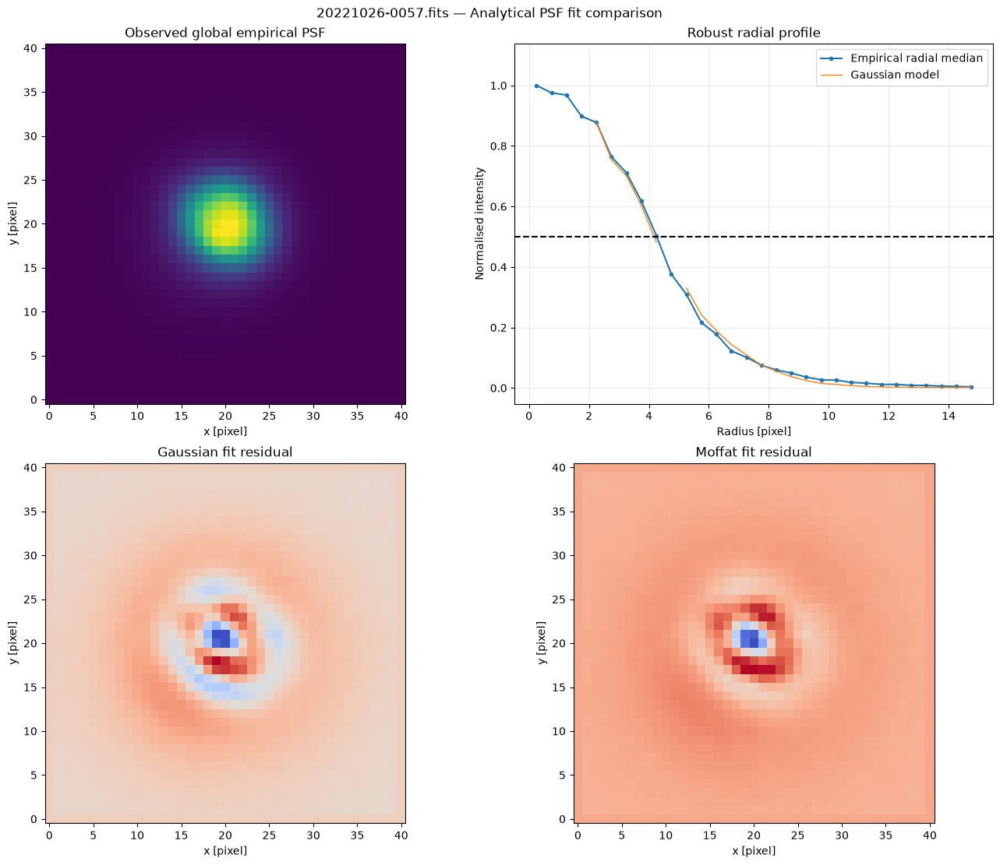

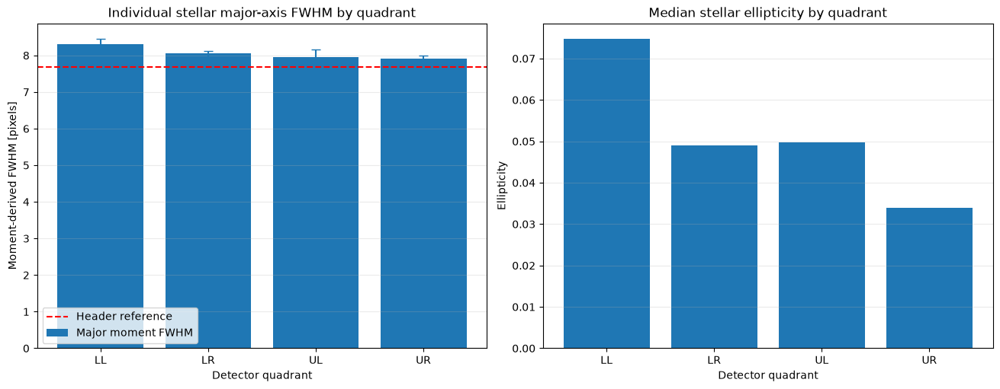


STAGE 7.3 COMPLETE
------------------
Fit results: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_gaussian_moffat_fit_results.csv
Quadrant widths: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_quadrant_individual_widths.csv
Fit figure: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_gaussian_moffat_fit_comparison.png
Quadrant figure: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_quadrant_width_comparison.png
Fit report: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_gaussian_moffat_fit_report.json

Memory: {'process_rss_gib': 2.141, 'available_ram_gib': 4.307}


12128

In [29]:
# ============================================================
# CELL 23 — GAUSSIAN/MOFFAT PSF FITTING
#
# Fits:
#   1. Global empirical PSF
#   2. Four quadrant-specific empirical PSFs
#
# Also produces:
#   - More robust radial profile with annular pixel counts
#   - Gaussian and Moffat fit statistics
#   - Spatial comparison of measured FWHM
#   - Comparison with header FWHM
#
# No source subtraction or masking.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import gc

from scipy.optimize import least_squares
from scipy.ndimage import map_coordinates


# ------------------------------------------------------------
# 1. Validate previous-stage products
# ------------------------------------------------------------

required = [
    "EMPIRICAL_PSF_PEAK",
    "QUADRANT_PSFS",
    "registration_df",
    "PSF_REFERENCE_FWHM_PIX",
    "PSF_CENTER",
    "FRAME_OUTPUT_DIR"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing PSF products: {missing}"
    )

if EMPIRICAL_PSF_PEAK.ndim != 2:
    raise RuntimeError("Global PSF must be two-dimensional.")

if EMPIRICAL_PSF_PEAK.shape[0] != EMPIRICAL_PSF_PEAK.shape[1]:
    raise RuntimeError("Expected square PSF cutouts.")

if len(QUADRANT_PSFS) == 0:
    raise RuntimeError("No quadrant-specific PSF stacks exist.")


# ------------------------------------------------------------
# 2. Coordinate system
# ------------------------------------------------------------

ny, nx = EMPIRICAL_PSF_PEAK.shape

PSF_FIT_CENTRE = (nx - 1) / 2.0

fit_y, fit_x = np.mgrid[
    0:ny,
    0:nx
]

fit_x = fit_x.astype(np.float64)
fit_y = fit_y.astype(np.float64)

fit_radius = np.sqrt(
    (fit_x - PSF_FIT_CENTRE)**2
    + (fit_y - PSF_FIT_CENTRE)**2
)


# ------------------------------------------------------------
# 3. Model functions
# ------------------------------------------------------------

def elliptical_coordinates(x, y, cx, cy, theta):

    dx = x - cx
    dy = y - cy

    ct = np.cos(theta)
    st = np.sin(theta)

    xr = dx * ct + dy * st
    yr = -dx * st + dy * ct

    return xr, yr


def gaussian_elliptical(
    params,
    x,
    y
):

    amp, cx, cy, sigma_major, sigma_minor, theta, offset = params

    xr, yr = elliptical_coordinates(
        x, y, cx, cy, theta
    )

    return (
        offset
        + amp * np.exp(
            -0.5 * (
                (xr / sigma_major)**2
                + (yr / sigma_minor)**2
            )
        )
    )


def moffat_elliptical(
    params,
    x,
    y
):

    amp, cx, cy, alpha_major, alpha_minor, beta, theta, offset = params

    xr, yr = elliptical_coordinates(
        x, y, cx, cy, theta
    )

    scaled_radius_squared = (
        (xr / alpha_major)**2
        + (yr / alpha_minor)**2
    )

    return (
        offset
        + amp
        * (1.0 + scaled_radius_squared)**(-beta)
    )


# ------------------------------------------------------------
# 4. Estimate initial centroid
# ------------------------------------------------------------

def estimate_stack_centre(psf):

    psf = np.asarray(
        psf,
        dtype=np.float64
    )

    outer = (
        fit_radius >= 15
    )

    background = float(
        np.median(psf[outer])
    )

    weights = np.clip(
        psf - background,
        0,
        None
    )

    central = (
        fit_radius <= 10
    )

    weights *= central

    total = weights.sum()

    if total <= 0:
        raise RuntimeError("Cannot estimate PSF centroid.")

    cx = float(
        np.sum(weights * fit_x) / total
    )

    cy = float(
        np.sum(weights * fit_y) / total
    )

    return cx, cy, background


# ------------------------------------------------------------
# 5. Fit the two models
# ------------------------------------------------------------

def fit_psf_models(psf, label):

    data = np.asarray(
        psf,
        dtype=np.float64
    )

    if not np.isfinite(data).all():
        raise RuntimeError(
            f"{label}: PSF contains non-finite pixels."
        )

    cx0, cy0, background0 = estimate_stack_centre(
        data
    )

    amp0 = float(
        data.max() - background0
    )

    if amp0 <= 0:
        raise RuntimeError(
            f"{label}: non-positive PSF amplitude."
        )

    data_flat = data.ravel()

    # --------------------------------------------------------
    # Gaussian
    # --------------------------------------------------------

    gaussian_initial = np.array([

        amp0,

        cx0,

        cy0,

        3.5,

        3.5,

        0.0,

        background0

    ])

    gaussian_lower = np.array([

        0.05,
        PSF_FIT_CENTRE - 2,
        PSF_FIT_CENTRE - 2,
        1.0,
        1.0,
        -np.pi / 2,
        -0.2

    ])

    gaussian_upper = np.array([

        2.0,
        PSF_FIT_CENTRE + 2,
        PSF_FIT_CENTRE + 2,
        10.0,
        10.0,
        np.pi / 2,
        0.2

    ])

    def gaussian_residual(params):

        model = gaussian_elliptical(
            params,
            fit_x,
            fit_y
        )

        return (
            model.ravel() - data_flat
        )

    gaussian_result = least_squares(

        gaussian_residual,

        gaussian_initial,

        bounds=(
            gaussian_lower,
            gaussian_upper
        ),

        loss="soft_l1",

        f_scale=0.01,

        max_nfev=2000

    )

    gaussian_params = gaussian_result.x

    gaussian_model = gaussian_elliptical(
        gaussian_params,
        fit_x,
        fit_y
    )

    sigma_major = gaussian_params[3]
    sigma_minor = gaussian_params[4]

    gaussian_fwhm_major = (
        2.354820045 * max(
            sigma_major,
            sigma_minor
        )
    )

    gaussian_fwhm_minor = (
        2.354820045 * min(
            sigma_major,
            sigma_minor
        )
    )

    gaussian_ellipticity = (
        1.0
        - min(sigma_major, sigma_minor)
        / max(sigma_major, sigma_minor)
    )

    gaussian_resid = (
        data - gaussian_model
    )

    # --------------------------------------------------------
    # Moffat
    # --------------------------------------------------------

    moffat_initial = np.array([

        amp0,

        cx0,

        cy0,

        7.0,

        7.0,

        2.5,

        0.0,

        background0

    ])

    moffat_lower = np.array([

        0.05,
        PSF_FIT_CENTRE - 2,
        PSF_FIT_CENTRE - 2,
        1.0,
        1.0,
        1.05,
        -np.pi / 2,
        -0.2

    ])

    moffat_upper = np.array([

        2.0,
        PSF_FIT_CENTRE + 2,
        PSF_FIT_CENTRE + 2,
        18.0,
        18.0,
        12.0,
        np.pi / 2,
        0.2

    ])

    def moffat_residual(params):

        model = moffat_elliptical(
            params,
            fit_x,
            fit_y
        )

        return (
            model.ravel() - data_flat
        )

    moffat_result = least_squares(

        moffat_residual,

        moffat_initial,

        bounds=(
            moffat_lower,
            moffat_upper
        ),

        loss="soft_l1",

        f_scale=0.01,

        max_nfev=3000

    )

    moffat_params = moffat_result.x

    moffat_model = moffat_elliptical(
        moffat_params,
        fit_x,
        fit_y
    )

    alpha_major = max(
        moffat_params[3],
        moffat_params[4]
    )

    alpha_minor = min(
        moffat_params[3],
        moffat_params[4]
    )

    beta = moffat_params[5]

    moffat_fwhm_factor = (
        2.0
        * np.sqrt(
            2.0**(1.0 / beta) - 1.0
        )
    )

    moffat_fwhm_major = (
        alpha_major * moffat_fwhm_factor
    )

    moffat_fwhm_minor = (
        alpha_minor * moffat_fwhm_factor
    )

    moffat_ellipticity = (
        1.0 - alpha_minor / alpha_major
    )

    moffat_resid = (
        data - moffat_model
    )

    # --------------------------------------------------------
    # Fit quality metrics
    # --------------------------------------------------------

    quality_radius = (
        fit_radius <= 12.0
    )

    def residual_quality(residual):

        values = residual[quality_radius]

        return {

            "core_rmse": float(
                np.sqrt(np.mean(values**2))
            ),

            "core_median_absolute_error": float(
                np.median(np.abs(values))
            ),

            "full_rmse": float(
                np.sqrt(np.mean(residual**2))
            )

        }

    summary = {

        "label": label,

        "gaussian": {

            "success": bool(gaussian_result.success),

            "fwhm_major_px": float(gaussian_fwhm_major),

            "fwhm_minor_px": float(gaussian_fwhm_minor),

            "ellipticity": float(gaussian_ellipticity),

            "centre_x": float(gaussian_params[1]),

            "centre_y": float(gaussian_params[2]),

            "sigma_major": float(max(
                sigma_major,
                sigma_minor
            )),

            "sigma_minor": float(min(
                sigma_major,
                sigma_minor
            )),

            "theta_rad": float(gaussian_params[5]),

            "background": float(gaussian_params[6]),

            **residual_quality(gaussian_resid)

        },

        "moffat": {

            "success": bool(moffat_result.success),

            "fwhm_major_px": float(moffat_fwhm_major),

            "fwhm_minor_px": float(moffat_fwhm_minor),

            "ellipticity": float(moffat_ellipticity),

            "alpha_major": float(alpha_major),

            "alpha_minor": float(alpha_minor),

            "beta": float(beta),

            "centre_x": float(moffat_params[1]),

            "centre_y": float(moffat_params[2]),

            "theta_rad": float(moffat_params[6]),

            "background": float(moffat_params[7]),

            **residual_quality(moffat_resid)

        }

    }

    return {

        "summary": summary,

        "data": data,

        "gaussian_model": gaussian_model,

        "moffat_model": moffat_model,

        "gaussian_residual": gaussian_resid,

        "moffat_residual": moffat_resid,

        "gaussian_params": gaussian_params,

        "moffat_params": moffat_params

    }


# ------------------------------------------------------------
# 6. Fit global and quadrant PSFs
# ------------------------------------------------------------

PSF_FIT_RESULTS = {}

PSF_STACKS = {
    "GLOBAL": EMPIRICAL_PSF_PEAK,
    **QUADRANT_PSFS
}

for label, stack in PSF_STACKS.items():

    print(
        f"\nFitting PSF: {label}"
    )

    PSF_FIT_RESULTS[label] = fit_psf_models(
        stack,
        label
    )

    print(
        "Gaussian FWHM:",
        PSF_FIT_RESULTS[label]["summary"]["gaussian"]
        ["fwhm_major_px"],
        PSF_FIT_RESULTS[label]["summary"]["gaussian"]
        ["fwhm_minor_px"]
    )

    print(
        "Moffat FWHM:",
        PSF_FIT_RESULTS[label]["summary"]["moffat"]
        ["fwhm_major_px"],
        PSF_FIT_RESULTS[label]["summary"]["moffat"]
        ["fwhm_minor_px"]
    )


# ------------------------------------------------------------
# 7. Robust radial profile using 0.5-pixel annuli
# ------------------------------------------------------------

def robust_radial_profile(
    psf,
    centre_x,
    centre_y,
    bin_width=0.5,
    maximum_radius=15.0
):

    radius = np.sqrt(
        (fit_x - centre_x)**2
        + (fit_y - centre_y)**2
    )

    edges = np.arange(
        0,
        maximum_radius + bin_width,
        bin_width
    )

    centres = 0.5 * (
        edges[:-1] + edges[1:]
    )

    medians = np.full(
        len(centres),
        np.nan
    )

    counts = np.zeros(
        len(centres),
        dtype=np.int32
    )

    for i in range(len(centres)):

        mask = (
            (radius >= edges[i])
            & (radius < edges[i + 1])
        )

        values = psf[mask]

        counts[i] = len(values)

        if len(values):
            medians[i] = float(
                np.median(values)
            )

    return centres, medians, counts


global_result = PSF_FIT_RESULTS["GLOBAL"]

global_gaussian = global_result["summary"]["gaussian"]

radial_r, radial_values, radial_counts = robust_radial_profile(

    EMPIRICAL_PSF_PEAK,

    global_gaussian["centre_x"],

    global_gaussian["centre_y"],

    bin_width=0.5,

    maximum_radius=15.0

)


# ------------------------------------------------------------
# 8. Print model comparison
# ------------------------------------------------------------

print("\nPSF MODEL COMPARISON")
print("--------------------")

fit_rows = []

for label, result in PSF_FIT_RESULTS.items():

    for model_name in ["gaussian", "moffat"]:

        metrics = result["summary"][model_name]

        fit_rows.append({

            "region": label,

            "model": model_name,

            "FWHM_major_px":
                metrics["fwhm_major_px"],

            "FWHM_minor_px":
                metrics["fwhm_minor_px"],

            "ellipticity":
                metrics["ellipticity"],

            "core_RMSE":
                metrics["core_rmse"],

            "full_RMSE":
                metrics["full_rmse"],

            "fit_success":
                metrics["success"]

        })

psf_fit_table = pd.DataFrame(
    fit_rows
)

print(
    psf_fit_table.to_string(index=False)
)


# ------------------------------------------------------------
# 9. Quadrant comparison using individual stellar moments
# ------------------------------------------------------------

quadrant_moment_rows = []

for quadrant in ["LL", "LR", "UL", "UR"]:

    subset = registration_df.loc[
        registration_df["quadrant"] == quadrant
    ]

    if subset.empty:
        continue

    major = subset["fwhm_major_moment"].to_numpy()
    minor = subset["fwhm_minor_moment"].to_numpy()
    ellipticity = subset["ellipticity_moment"].to_numpy()

    quadrant_moment_rows.append({

        "quadrant": quadrant,

        "star_count": len(subset),

        "major_fwhm_median": float(np.median(major)),

        "major_fwhm_p16": float(np.percentile(major, 16)),

        "major_fwhm_p84": float(np.percentile(major, 84)),

        "minor_fwhm_median": float(np.median(minor)),

        "minor_fwhm_p16": float(np.percentile(minor, 16)),

        "minor_fwhm_p84": float(np.percentile(minor, 84)),

        "ellipticity_median": float(np.median(ellipticity))

    })

quadrant_moment_df = pd.DataFrame(
    quadrant_moment_rows
)

print("\nINDIVIDUAL STAR WIDTHS BY QUADRANT")
print("----------------------------------")

print(
    quadrant_moment_df.to_string(index=False)
)


# ------------------------------------------------------------
# 10. Global empirical PSF and residual plots
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 11),
    constrained_layout=True
)

axes[0, 0].imshow(
    EMPIRICAL_PSF_PEAK,
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=1
)

axes[0, 0].set_title(
    "Observed global empirical PSF"
)

axes[0, 0].set_xlabel("x [pixel]")
axes[0, 0].set_ylabel("y [pixel]")


axes[0, 1].plot(
    radial_r,
    radial_values,
    marker="o",
    markersize=3,
    label="Empirical radial median"
)

axes[0, 1].plot(
    radial_r,
    np.array([
        np.mean(
            PSF_FIT_RESULTS["GLOBAL"]["gaussian_model"][
                (fit_radius >= r - 0.25)
                & (fit_radius < r + 0.25)
            ]
        )
        if np.any(
            (fit_radius >= r - 0.25)
            & (fit_radius < r + 0.25)
        )
        else np.nan
        for r in radial_r
    ]),
    label="Gaussian model",
    linewidth=1
)

axes[0, 1].axhline(
    0.5,
    linestyle="--",
    color="black"
)

axes[0, 1].set_title(
    "Robust radial profile"
)

axes[0, 1].set_xlabel("Radius [pixel]")
axes[0, 1].set_ylabel("Normalised intensity")

axes[0, 1].legend()
axes[0, 1].grid(alpha=0.25)


axes[1, 0].imshow(
    global_result["gaussian_residual"],
    origin="lower",
    cmap="coolwarm"
)

axes[1, 0].set_title(
    "Gaussian fit residual"
)

axes[1, 0].set_xlabel("x [pixel]")
axes[1, 0].set_ylabel("y [pixel]")


axes[1, 1].imshow(
    global_result["moffat_residual"],
    origin="lower",
    cmap="coolwarm"
)

axes[1, 1].set_title(
    "Moffat fit residual"
)

axes[1, 1].set_xlabel("x [pixel]")
axes[1, 1].set_ylabel("y [pixel]")


fig.suptitle(
    f"{FRAME_FILENAME} — Analytical PSF fit comparison"
)

PSF_MODEL_FIGURE = (
    FRAME_OUTPUT_DIR /
    "psf_gaussian_moffat_fit_comparison.png"
)

fig.savefig(
    PSF_MODEL_FIGURE,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 11. Plot quadrant widths
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
    constrained_layout=True
)

quadrants = quadrant_moment_df["quadrant"].tolist()

axes[0].bar(
    quadrants,
    quadrant_moment_df["major_fwhm_median"],
    label="Major moment FWHM"
)

axes[0].errorbar(
    quadrants,
    quadrant_moment_df["major_fwhm_median"],
    yerr=[
        quadrant_moment_df["major_fwhm_median"]
        - quadrant_moment_df["major_fwhm_p16"],

        quadrant_moment_df["major_fwhm_p84"]
        - quadrant_moment_df["major_fwhm_median"]

    ],
    fmt="none",
    capsize=4
)

axes[0].axhline(
    PSF_REFERENCE_FWHM_PIX,
    color="red",
    linestyle="--",
    label="Header reference"
)

axes[0].set_title(
    "Individual stellar major-axis FWHM by quadrant"
)

axes[0].set_xlabel("Detector quadrant")
axes[0].set_ylabel("Moment-derived FWHM [pixels]")

axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)


axes[1].bar(
    quadrants,
    quadrant_moment_df["ellipticity_median"]
)

axes[1].set_title(
    "Median stellar ellipticity by quadrant"
)

axes[1].set_xlabel("Detector quadrant")
axes[1].set_ylabel("Ellipticity")

axes[1].grid(axis="y", alpha=0.25)


QUADRANT_WIDTH_FIGURE = (
    FRAME_OUTPUT_DIR /
    "psf_quadrant_width_comparison.png"
)

fig.savefig(
    QUADRANT_WIDTH_FIGURE,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 12. Save fit results
# ------------------------------------------------------------

PSF_FIT_TABLE_PATH = (
    FRAME_OUTPUT_DIR /
    "psf_gaussian_moffat_fit_results.csv"
)

psf_fit_table.to_csv(
    PSF_FIT_TABLE_PATH,
    index=False
)

QUADRANT_WIDTH_TABLE_PATH = (
    FRAME_OUTPUT_DIR /
    "psf_quadrant_individual_widths.csv"
)

quadrant_moment_df.to_csv(
    QUADRANT_WIDTH_TABLE_PATH,
    index=False
)


PSF_FIT_REPORT = {

    "frame": FRAME_FILENAME,

    "fits_sha256": FITS_SHA256,

    "header_reference_fwhm_px":
        float(PSF_REFERENCE_FWHM_PIX),

    "fits": {

        label: result["summary"]

        for label, result in PSF_FIT_RESULTS.items()

    },

    "quadrant_individual_moments":
        quadrant_moment_df.to_dict(orient="records"),

    "radial_profile": {

        "bin_width_px": 0.5,

        "radius_px": radial_r.tolist(),

        "median_intensity": [
            None if not np.isfinite(v) else float(v)
            for v in radial_values
        ],

        "pixel_counts": radial_counts.tolist()

    },

    "interpretation":
        "Analytical fit diagnostics only. Model selection and PSF "
        "acceptance require review of residuals and quadrant consistency."

}

PSF_FIT_REPORT_PATH = (
    FRAME_OUTPUT_DIR /
    "psf_gaussian_moffat_fit_report.json"
)

PSF_FIT_REPORT_PATH.write_text(
    json.dumps(
        PSF_FIT_REPORT,
        indent=2
    ),
    encoding="utf-8"
)


print("\nSTAGE 7.3 COMPLETE")
print("------------------")

print("Fit results:", PSF_FIT_TABLE_PATH)

print("Quadrant widths:", QUADRANT_WIDTH_TABLE_PATH)

print("Fit figure:", PSF_MODEL_FIGURE)

print("Quadrant figure:", QUADRANT_WIDTH_FIGURE)

print("Fit report:", PSF_FIT_REPORT_PATH)

print("\nMemory:", memory_report())

gc.collect()

### Quantitive Audit of Gaussian and Moffat fits

PSF FIT PARAMETER AUDIT
-----------------------

REGION: GLOBAL

GAUSSIAN
success                            : True
fwhm_major_px                      : 8.170936903149498
fwhm_minor_px                      : 7.517570393400126
ellipticity                        : 0.07996225126858225
centre_x                           : 20.061989477268906
centre_y                           : 20.03094894335083
sigma_major                        : 3.4698774203569758
sigma_minor                        : 3.1924182101992113
theta_rad                          : 0.8894478137403633
background                         : 0.0013170789908091918
core_rmse                          : 0.017682400531952715
core_median_absolute_error         : 0.0107153334435973
full_rmse                          : 0.009807172324412939
Raw parameters: [1.08303292e+00 2.00619895e+01 2.00309489e+01 3.19241821e+00
 3.46987742e+00 8.89447814e-01 1.31707899e-03]

MOFFAT
success                            : True
fwhm_major_px                    

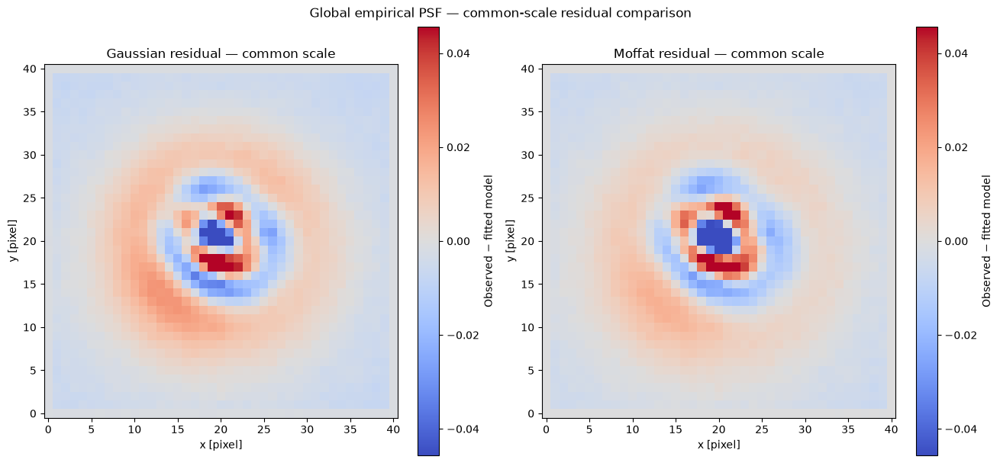


STAGE 7.3.1 COMPLETE
--------------------
Residual audit: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_fit_residual_audit.csv
Parameter audit: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_fit_parameter_boundary_audit.csv
Common residual figure: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/psf_common_scale_residual_comparison.png


In [30]:
# ============================================================
# CELL 23.1 — QUANTITATIVE PSF FIT AUDIT
#
# Uses existing PSF_FIT_RESULTS.
# Does not refit, modify or overwrite any PSF.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Validate products
# ------------------------------------------------------------

if "PSF_FIT_RESULTS" not in globals():
    raise RuntimeError("Run Cell 23 first.")

if "GLOBAL" not in PSF_FIT_RESULTS:
    raise RuntimeError("Global PSF fit is missing.")


# ------------------------------------------------------------
# 2. Print complete fitted parameters
# ------------------------------------------------------------

print("PSF FIT PARAMETER AUDIT")
print("-----------------------")

for region, result in PSF_FIT_RESULTS.items():

    print(f"\nREGION: {region}")

    for model_name in ["gaussian", "moffat"]:

        metrics = result["summary"][model_name]

        print(f"\n{model_name.upper()}")

        for key, value in metrics.items():

            print(f"{key:35s}: {value}")

        parameter_name = (
            "gaussian_params"
            if model_name == "gaussian"
            else "moffat_params"
        )

        print(
            "Raw parameters:",
            result[parameter_name]
        )


# ------------------------------------------------------------
# 3. Calculate residual metrics consistently
# ------------------------------------------------------------

def calculate_residual_metrics(
    data,
    model,
    residual,
    radius
):

    regions = {

        "core_r0_5": radius <= 5,

        "intermediate_r5_10": (
            (radius > 5)
            & (radius <= 10)
        ),

        "wings_r10_15": (
            (radius > 10)
            & (radius <= 15)
        ),

        "full_r0_15": radius <= 15

    }

    records = []

    for region_name, mask in regions.items():

        observed = data[mask]
        predicted = model[mask]
        errors = residual[mask]

        records.append({

            "region": region_name,

            "pixels": int(mask.sum()),

            "data_rmse": float(
                np.sqrt(np.mean(errors**2))
            ),

            "data_median_absolute_residual": float(
                np.median(np.abs(errors))
            ),

            "residual_median": float(
                np.median(errors)
            ),

            "residual_p95_abs": float(
                np.percentile(np.abs(errors), 95)
            ),

            "residual_rmse_relative_to_peak": float(
                np.sqrt(np.mean(errors**2))
                / max(float(data.max()), 1e-12)
            ),

            "model_median": float(
                np.median(predicted)
            )

        })

    return records


global_result = PSF_FIT_RESULTS["GLOBAL"]

global_data = global_result["data"]

global_radius = np.sqrt(
    (fit_x - global_gaussian["centre_x"])**2
    + (fit_y - global_gaussian["centre_y"])**2
) if "global_gaussian" in globals() else fit_radius


# Recompute model radii around the fitted Gaussian centroid.
gparams = global_result["gaussian_params"]
mparams = global_result["moffat_params"]

gaussian_cx = float(gparams[1])
gaussian_cy = float(gparams[2])

moffat_cx = float(mparams[1])
moffat_cy = float(mparams[2])

gaussian_radius = np.sqrt(
    (fit_x - gaussian_cx)**2
    + (fit_y - gaussian_cy)**2
)

moffat_radius = np.sqrt(
    (fit_x - moffat_cx)**2
    + (fit_y - moffat_cy)**2
)


metric_records = []

for model_name, model_key, residual_key, radius in [

    (
        "gaussian",
        "gaussian_model",
        "gaussian_residual",
        gaussian_radius
    ),

    (
        "moffat",
        "moffat_model",
        "moffat_residual",
        moffat_radius
    )

]:

    records = calculate_residual_metrics(

        global_data,

        global_result[model_key],

        global_result[residual_key],

        radius

    )

    for record in records:

        record["model"] = model_name

        metric_records.append(record)


residual_audit_df = pd.DataFrame(
    metric_records
)

print("\nGLOBAL FIT RESIDUAL AUDIT")
print("-------------------------")

print(
    residual_audit_df[
        [
            "model",
            "region",
            "pixels",
            "data_rmse",
            "residual_median",
            "residual_p95_abs",
            "residual_rmse_relative_to_peak"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 4. Parameter boundary checks
# ------------------------------------------------------------

parameter_records = []

for region, result in PSF_FIT_RESULTS.items():

    gp = result["gaussian_params"]
    mp = result["moffat_params"]

    gaussian_names = [
        "amplitude",
        "centre_x",
        "centre_y",
        "sigma_major",
        "sigma_minor",
        "theta",
        "background"
    ]

    gaussian_lower = np.array([
        0.05,
        PSF_FIT_CENTRE - 2,
        PSF_FIT_CENTRE - 2,
        1.0,
        1.0,
        -np.pi / 2,
        -0.2
    ])

    gaussian_upper = np.array([
        2.0,
        PSF_FIT_CENTRE + 2,
        PSF_FIT_CENTRE + 2,
        10.0,
        10.0,
        np.pi / 2,
        0.2
    ])

    moffat_names = [
        "amplitude",
        "centre_x",
        "centre_y",
        "alpha_major",
        "alpha_minor",
        "beta",
        "theta",
        "background"
    ]

    moffat_lower = np.array([
        0.05,
        PSF_FIT_CENTRE - 2,
        PSF_FIT_CENTRE - 2,
        1.0,
        1.0,
        1.05,
        -np.pi / 2,
        -0.2
    ])

    moffat_upper = np.array([
        2.0,
        PSF_FIT_CENTRE + 2,
        PSF_FIT_CENTRE + 2,
        18.0,
        18.0,
        12.0,
        np.pi / 2,
        0.2
    ])

    for model_name, params, names, lower, upper in [

        ("gaussian", gp, gaussian_names, gaussian_lower, gaussian_upper),

        ("moffat", mp, moffat_names, moffat_lower, moffat_upper)

    ]:

        for name, value, lo, hi in zip(
            names,
            params,
            lower,
            upper
        ):

            margin = min(
                float(value - lo),
                float(hi - value)
            )

            parameter_records.append({

                "region": region,

                "model": model_name,

                "parameter": name,

                "value": float(value),

                "lower_bound": float(lo),

                "upper_bound": float(hi),

                "minimum_margin": margin,

                "near_bound": bool(
                    margin < 1e-3
                    * max(1.0, abs(hi - lo))
                )

            })


parameter_audit_df = pd.DataFrame(
    parameter_records
)

print("\nPARAMETER BOUNDARY AUDIT")
print("------------------------")

print(
    parameter_audit_df.loc[
        parameter_audit_df["near_bound"]
    ].to_string(index=False)
)

print(
    "\nNumber of parameters near bounds:",
    int(parameter_audit_df["near_bound"].sum())
)


# ------------------------------------------------------------
# 5. Common-scale residual visualization
# ------------------------------------------------------------

residuals = [

    global_result["gaussian_residual"],

    global_result["moffat_residual"]

]

# Use a common symmetric scale for both maps.
common_scale = float(
    np.percentile(
        np.abs(
            np.concatenate([
                r.ravel()
                for r in residuals
            ])
        ),
        99
    )
)

common_scale = max(
    common_scale,
    1e-8
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 6),
    constrained_layout=True
)

for ax, residual, title in zip(

    axes,

    residuals,

    [
        "Gaussian residual — common scale",
        "Moffat residual — common scale"
    ]

):

    im = ax.imshow(
        residual,
        origin="lower",
        cmap="coolwarm",
        vmin=-common_scale,
        vmax=common_scale
    )

    ax.set_title(title)

    ax.set_xlabel("x [pixel]")
    ax.set_ylabel("y [pixel]")

    fig.colorbar(
        im,
        ax=ax,
        label="Observed − fitted model"
    )


fig.suptitle(
    "Global empirical PSF — common-scale residual comparison"
)

PSF_COMMON_RESIDUAL_FIGURE = (
    FRAME_OUTPUT_DIR /
    "psf_common_scale_residual_comparison.png"
)

fig.savefig(
    PSF_COMMON_RESIDUAL_FIGURE,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 6. Save quantitative audit
# ------------------------------------------------------------

RESIDUAL_AUDIT_PATH = (
    FRAME_OUTPUT_DIR /
    "psf_fit_residual_audit.csv"
)

residual_audit_df.to_csv(
    RESIDUAL_AUDIT_PATH,
    index=False
)

PARAMETER_AUDIT_PATH = (
    FRAME_OUTPUT_DIR /
    "psf_fit_parameter_boundary_audit.csv"
)

parameter_audit_df.to_csv(
    PARAMETER_AUDIT_PATH,
    index=False
)


print("\nSTAGE 7.3.1 COMPLETE")
print("--------------------")

print("Residual audit:", RESIDUAL_AUDIT_PATH)

print("Parameter audit:", PARAMETER_AUDIT_PATH)

print("Common residual figure:", PSF_COMMON_RESIDUAL_FIGURE)

**What the PSF audit establishes**

The global model comparison is:
| Metric | Gaussian | Moffat | Better |
|---|---:|---:|---|
| Core RMSE, radius ≤5 px | 0.03179 | 0.04344 | Gaussian |
| Intermediate RMSE, 5–10 px | 0.01321 | 0.01081 | Moffat |
| Wing RMSE, 10–15 px | 0.00891 | 0.00658 | Moffat |
| Overall RMSE, radius ≤15 px | 0.01450 | 0.01625 | Gaussian |

The parameter fits converged without hitting their configured bounds. However, both residual images show structured central patterns, not just random-looking residuals. The optimizer's success=True means it converged; it does not mean the analytical model accurately represents every feature of the observed PSF.

Decision: use the empirical 2-D PSF, not the Gaussian or Moffat approximation.

In [31]:
# ============================================================
# STAGE 7.4 — FREEZE EMPIRICAL PSF FOR FRT
# ============================================================

import numpy as np

if "EMPIRICAL_PSF_FLUX" not in globals():
    raise RuntimeError("Empirical flux-normalised PSF is missing.")

# Independent copy: PyRaDoN's PSF setter normalises an
# input array in-place, so never hand it our original array.
FRT_PSF_KERNEL = np.array(
    EMPIRICAL_PSF_FLUX,
    dtype=np.float64,
    copy=True
)

if not np.isfinite(FRT_PSF_KERNEL).all():
    raise RuntimeError("PSF kernel contains non-finite values.")

negative_fraction = float(
    np.mean(FRT_PSF_KERNEL < 0)
)

negative_sum = float(
    np.abs(FRT_PSF_KERNEL[FRT_PSF_KERNEL < 0]).sum()
)

total_positive = float(
    np.clip(FRT_PSF_KERNEL, 0, None).sum()
)

# A physical intensity PSF must be non-negative.
FRT_PSF_KERNEL = np.clip(
    FRT_PSF_KERNEL,
    0,
    None
)

if FRT_PSF_KERNEL.sum() <= 0:
    raise RuntimeError("PSF kernel has no positive flux.")

# Unit-sum normalisation; PyRaDoN subsequently applies
# its own L2 normalisation in its PSF setter.
FRT_PSF_KERNEL /= FRT_PSF_KERNEL.sum()

assert FRT_PSF_KERNEL.ndim == 2
assert np.isfinite(FRT_PSF_KERNEL).all()
assert np.all(FRT_PSF_KERNEL >= 0)
assert np.isclose(FRT_PSF_KERNEL.sum(), 1.0)

PSF_KERNEL_PATH = (
    FRAME_OUTPUT_DIR / "frt_empirical_psf_kernel.npy"
)

np.save(
    PSF_KERNEL_PATH,
    FRT_PSF_KERNEL
)

print("FRT PSF KERNEL FROZEN")
print("---------------------")
print("Shape:", FRT_PSF_KERNEL.shape)
print("Sum:", FRT_PSF_KERNEL.sum())
print("Minimum:", FRT_PSF_KERNEL.min())
print("Maximum:", FRT_PSF_KERNEL.max())
print("Original negative-pixel fraction:", negative_fraction)
print("Absolute negative contribution:", negative_sum)
print("Original positive contribution:", total_positive)
print("Saved:", PSF_KERNEL_PATH)

FRT PSF KERNEL FROZEN
---------------------
Shape: (41, 41)
Sum: 1.0
Minimum: 0.0
Maximum: 0.012637071052840837
Original negative-pixel fraction: 0.4146341463414634
Absolute negative contribution: 0.02235185421692698
Original positive contribution: 1.0043059536875703
Saved: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/single_frame_preprocessing/20221026-0057/frt_empirical_psf_kernel.npy
